# Marvel CPG: Exploratory Data Analysis v2 (updated client data)

**CDA 650 Experiential Learning · Client project with Globant · Team 1**
**Dataset:** Marvel CPG synthetic commercial data, **v2** (the update Dr. Masse shared in October 2026), Jan 2025 – Jun 2026
**Previous version:** `Marvel EDA.ipynb` (v1, original data). Everything in this notebook is v2 evidence; v1 numbers only appear when we compare.

---

### Table of contents
1. Introduction
2. Setup and data loading
3. Data understanding and quality checks (and what changed since v1)
4. Univariate analysis
5. Bivariate and multivariate analysis
6. Time series analysis
7. The brief's KPIs (baseline values, official definitions)
8. Deep dives
9. Key insights: what changed from v1 and what it means for our build
10. Questions for Dr. Masse
11. Next steps

> **To run on Colab:** `Runtime → Run all`. In section 2 a file picker opens (up to twice). Choose `marvel_data_update.zip` (the new zip) and `marvel_data.zip` (the original one). We still need the original zip because the update only contains the five tables that changed. The whole notebook takes a few minutes.

## 1. Introduction

### 1.1 Why a second EDA
On 10 October Dr. Masse sent us a data update (`marvel_data_update.zip`) with this note:

| | File | What the client said changed |
|---|---|---|
| New | `dim_promotions.csv` | did not exist before |
| New | `fact_deliveries.csv` | did not exist before |
| Updated | `dim_products.csv` | added `consumer_price` |
| Updated | `fact_sell_out.csv` | added `consumer_price_actual`, `promo_id`, `promo_discount_pct`; "OOS fixed from ~30% → 6.8%" |
| Updated | `fact_sell_in.csv` | added `gross_sales`; `discount_pct` now volume-correlated; added `promo_id` |

A lot of our v1 findings were about things the data *couldn't* do: no prices in sell-out, random discounts, 30% missing store-days, and no way to know when the next delivery lands. This update looks like a direct answer to several of them. So we can't just swap the files and keep our old conclusions. We redid the EDA in the same order as v1, checking every v1 finding again on the new data.

(Team rule from the repo: the v1 work is frozen under the `v1-data-baseline` tag, and anything built on the new data should say it is **v2**. That's why this is a separate notebook.)

### 1.2 What we want to learn from this EDA
1. Is everything the client said changed actually in the data? Did anything change that the note doesn't mention?
2. Is the v2 data still clean and internally consistent, including the two new tables?
3. Which v1 findings still hold, and which ones are no longer true?
4. What do promotions, consumer prices and deliveries add for each module (dashboard, OOS model, what-if simulator, chatbot)?
5. What are the KPI baselines now, using the official definitions from the Q&A?
6. What does the new data mean for the OOS model: which new signals are real, and which would leak the future?
7. What do we need to clarify with Dr. Masse this time?

### 1.3 The dataset (v2)
Eight tables now. The update zip has five of them; the other three were not sent again, so we use the v1 copies. (A teammate also uploaded the full v2 set to the repo under `new_marvel_data/`. Its three unchanged files have exactly the same checksums as the v1 ones, so nothing was silently changed there.)

| File | v2 status | What one row is |
|---|---|---|
| `dim_stores` | unchanged | one store (channel, region, state, tier, city) |
| `dim_products` | **updated** | one SKU (category, brand, MSL flag, cost, list price, **consumer price**) |
| `dim_guardrails` | unchanged | discount and margin rules for one channel × category |
| `dim_promotions` | **new** | one promotion: type, channel, category, dates, discount, minimum volume |
| `fact_sell_out` | **updated** | one store-SKU-day: units sold, end-of-day stock, OOS flag, **price paid, promo** |
| `fact_sell_in` | **updated** | one invoice line: units, **gross sales, discount %**, net sales, **promo** |
| `fact_deliveries` | **new** | one delivery per invoice line: scheduled vs actual date, delay, units ordered vs delivered |
| `fact_execution_audits` | unchanged | one SKU checked during a store audit: planogram, shelf share, secondary display |

### 1.4 What the client has answered since v1
After v1 we sent 19 questions; the answers (Marvel CPG Q&A) are binding, so this notebook follows them:

| Q | Answer we apply here |
|---|---|
| Q3 | `inventory_level` is end-of-day stock; OOS = ended the day at 0 |
| Q5, Q16 | `list_price` is the trade price; margin = (net price − cost) ÷ net price, with net price = list × (1 − discount) |
| Q10, Q15 | Exact KPI definitions (used in section 7); MSL and planogram compliance are different things |
| Q11 | Missing store-days are **not reported**, not zero sales |
| Q12 | OOS target = out of stock on **any** of the next 7 days; 0.75 / 0.70 / 0.80 are fixed minimums |
| Q13 | Compare sell-in and sell-out over the **same time window** (Traditional Trade is invoiced every two weeks) |
| Q14 | Elasticity and execution uplift must be **estimated from the data**, not assumed |
| Q17 | Distributors are wholesale accounts; show them separately from retail KPIs |
| Q18 | 30 June 2026 is "today"; train up to ~May 2026, test on June 2026 |

### 1.5 What this notebook covers
This notebook is EDA only. The missing-data experiments and the OOS model live in their own notebooks. Because June 2026 is the OOS model's test month, the checks on structure, keys and formulas (3.1–3.6) use the full data, but every analysis after that uses **1 Jan 2025 – 31 May 2026** (see the end of 3.6).

## 2. Setup and data loading

In [1]:
import os, gc, zipfile, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)

# fixed orders and colours so every chart in the notebook is consistent.
# Same as v1, except Distributor, Tier 2 and two category colours: we ran a colour-blind check
# and the v1 versions were hard to tell apart (e.g. the green and orange for protanopia)
CH_ORDER = ['Modern Trade', 'Traditional Trade', 'Distributor']
TIER_ORDER = ['Tier 1', 'Tier 2', 'Tier 3']
CAT_ORDER = ['Surface Cleaners', 'Dishwashing', 'Laundry']
REGION_ORDER = ['Northeast', 'Midwest', 'Southeast', 'West']
CH_COL = dict(zip(CH_ORDER, ['#4C72B0', '#DD8452', '#8C5A9E']))
TIER_COL = dict(zip(TIER_ORDER, ['#2A9D8F', '#D4A72C', '#C4473A']))
CAT_COL = dict(zip(CAT_ORDER, ['#7A5FC0', '#2E9BC0', '#C44E52']))
REG_COL = dict(zip(REGION_ORDER, ['#4C72B0', '#937860', '#DA8BC3', '#8C8C8C']))
DAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
TODAY = pd.Timestamp('2026-06-30')     # Q18: "today" in the simulation

def heatmap(*args, **kwargs):          # seaborn heatmap without the background grid lines
    ax = sns.heatmap(*args, **kwargs); ax.grid(False); return ax

def label_bars(ax, fmt='{:.1f}', size=9):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) for v in c.datavalues], fontsize=size, padding=2)

FIG_DIR = 'Marvel EDA v2 Figures'       # every chart is also saved here (for slides and the repo)
os.makedirs(FIG_DIR, exist_ok=True)
def show(name, tight=True):
    if tight:
        plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=130, bbox_inches='tight'); plt.show()

print('pandas', pd.__version__)

pandas 2.2.3


The cell below looks for the two data folders. If one isn't there, it asks for the matching zip and unzips it: `marvel_data_update.zip` (new, files at the top level) goes into `marvel_data_update/`, and `marvel_data.zip` (original) unzips into `marvel_data/`.
*(Google Drive instead? Mount Drive with `from google.colab import drive; drive.mount('/content/drive')`, then copy both zips into the working folder before this cell.)*

In [2]:
NEW_DIR, OLD_DIR = 'marvel_data_update', 'marvel_data'
for folder, zip_name, target in [(NEW_DIR, 'marvel_data_update.zip', NEW_DIR), (OLD_DIR, 'marvel_data.zip', '.')]:
    if not os.path.isdir(folder):
        if not os.path.exists(zip_name):
            from google.colab import files   # opens a file picker -> choose the zip printed below
            print('Please choose', zip_name); files.upload()
        with zipfile.ZipFile(zip_name) as z:
            z.extractall(target)
print(NEW_DIR, sorted(os.listdir(NEW_DIR)))
print(OLD_DIR, sorted(os.listdir(OLD_DIR)))

# v2: the five new or updated tables
products   = pd.read_csv(f'{NEW_DIR}/dim_products.csv')
promos     = pd.read_csv(f'{NEW_DIR}/dim_promotions.csv', parse_dates=['start_date', 'end_date'])
sell_out   = pd.read_csv(f'{NEW_DIR}/fact_sell_out.csv', parse_dates=['date'], dtype={'promo_id': str})
sell_in    = pd.read_csv(f'{NEW_DIR}/fact_sell_in.csv', parse_dates=['date'], dtype={'promo_id': str})
deliveries = pd.read_csv(f'{NEW_DIR}/fact_deliveries.csv', parse_dates=['invoice_date', 'scheduled_delivery', 'actual_delivery'])
# not in the update, so unchanged from v1
stores     = pd.read_csv(f'{OLD_DIR}/dim_stores.csv')
guardrails = pd.read_csv(f'{OLD_DIR}/dim_guardrails.csv')
audits     = pd.read_csv(f'{OLD_DIR}/fact_execution_audits.csv', parse_dates=['date'])
# v1 versions of the changed tables, only used to compare old vs new
v1 = {'dim_products': pd.read_csv(f'{OLD_DIR}/dim_products.csv'),
      'fact_sell_out': pd.read_csv(f'{OLD_DIR}/fact_sell_out.csv', parse_dates=['date']),
      'fact_sell_in': pd.read_csv(f'{OLD_DIR}/fact_sell_in.csv', parse_dates=['date'])}

tables = {'dim_stores': stores, 'dim_products': products, 'dim_guardrails': guardrails, 'dim_promotions': promos,
          'fact_sell_out': sell_out, 'fact_sell_in': sell_in, 'fact_deliveries': deliveries, 'fact_execution_audits': audits}
ch_of = stores.set_index('store_id').channel        # quick lookups we use a lot
cat_of = products.set_index('sku_id').category

marvel_data_update ['dim_products.csv', 'dim_promotions.csv', 'fact_deliveries.csv', 'fact_sell_in.csv', 'fact_sell_out.csv']
marvel_data ['dim_guardrails.csv', 'dim_products.csv', 'dim_stores.csv', 'fact_execution_audits.csv', 'fact_sell_in.csv', 'fact_sell_out.csv']


## 3. Data understanding and quality checks
Same checklist as v1 (size and types, missing values, duplicates, keys, value ranges, date coverage, internal consistency), plus one new question: **what exactly changed since v1?**

### 3.1 Size, columns and types

In [3]:
STATUS = {'dim_stores': 'unchanged', 'dim_products': 'updated', 'dim_guardrails': 'unchanged', 'dim_promotions': 'NEW',
          'fact_sell_out': 'updated', 'fact_sell_in': 'updated', 'fact_deliveries': 'NEW', 'fact_execution_audits': 'unchanged'}
SPAN = {'fact_sell_out': ('date', 'date'), 'fact_sell_in': ('date', 'date'), 'fact_execution_audits': ('date', 'date'),
        'fact_deliveries': ('invoice_date', 'actual_delivery'), 'dim_promotions': ('start_date', 'end_date')}
overview = pd.DataFrame([{
    'table': n, 'v2_status': STATUS[n], 'rows': len(d), 'columns': d.shape[1],
    'memory_MB': round(d.memory_usage(deep=True).sum() / 1e6, 1),
    'first_date': d[SPAN[n][0]].min().date() if n in SPAN else '-',
    'last_date': d[SPAN[n][1]].max().date() if n in SPAN else '-'} for n, d in tables.items()])
display(overview)

for n in ['dim_products', 'dim_promotions', 'fact_sell_out', 'fact_sell_in', 'fact_deliveries']:
    print(f'--- {n} ---')
    display(tables[n].head(3))

,table,v2_status,rows,columns,memory_MB,first_date,last_date
0,dim_stores,unchanged,221,7,0.1,-,-
1,dim_products,updated,23,8,0.0,-,-
2,dim_guardrails,unchanged,9,5,0.0,-,-
3,dim_promotions,NEW,37,9,0.0,2025-01-05,2026-06-15
4,fact_sell_out,updated,2194549,9,419.7,2025-01-01,2026-06-30
5,fact_sell_in,updated,281004,9,70.0,2024-12-30,2026-06-29
6,fact_deliveries,NEW,281004,12,96.4,2024-12-30,2026-07-13
7,fact_execution_audits,unchanged,207020,7,39.4,2025-01-01,2026-06-30


--- dim_products ---


,sku_id,product_name,category,brand,is_msl,unit_cost,list_price,consumer_price
0,SKU-1001,Marvel Power Clean Lemon 1L,Surface Cleaners,Marvel Clean,True,2.10,4.5,6.17
1,SKU-1002,Marvel Power Clean Original 1L,Surface Cleaners,Marvel Clean,True,2.05,4.4,5.98
2,SKU-1003,Marvel Power Clean Lavender 750ml,Surface Cleaners,Marvel Clean,False,1.85,3.9,5.22


--- dim_promotions ---


,promo_id,promo_name,promo_type,category,channel,start_date,end_date,discount_pct,min_volume_units
0,PRO-001,Spring Clean Blitz,TPR,Surface Cleaners,Modern Trade,2025-03-03,2025-03-23,12.0,50
1,PRO-002,Spring Clean Blitz,TPR,Surface Cleaners,Traditional Trade,2025-03-03,2025-03-23,12.0,50
2,PRO-003,Spring Clean Blitz,TPR,Dishwashing,Modern Trade,2025-03-03,2025-03-23,10.0,30


...

,date,store_id,sku_id,units_sold_daily,inventory_level,is_out_of_stock,consumer_price_actual,promo_id,promo_discount_pct
0,2025-01-01,STR-0008,SKU-1001,0,42,False,6.34,NaN,0.0
1,2025-01-01,STR-0008,SKU-1002,2,35,False,5.90,NaN,0.0
2,2025-01-01,STR-0008,SKU-1004,2,22,False,8.20,NaN,0.0


--- fact_sell_in ---


,transaction_id,date,store_id,sku_id,units_sold,gross_sales,discount_pct,net_sales,promo_id
0,TXN-00001,2024-12-30,STR-0001,SKU-1001,10,45.0,7.40,41.67,NaN
1,TXN-00002,2024-12-30,STR-0001,SKU-1002,21,92.4,6.05,86.81,NaN
2,TXN-00003,2024-12-30,STR-0001,SKU-1004,12,69.6,8.48,63.70,NaN


--- fact_deliveries ---


,delivery_id,transaction_id,store_id,sku_id,invoice_date,scheduled_delivery,actual_delivery,delay_days,delivery_status,units_ordered,units_delivered,fill_rate_pct
0,DLV-00001,TXN-00001,STR-0001,SKU-1001,2024-12-30,2025-01-03,2025-01-03,0,On Time,10,10,100.0
1,DLV-00002,TXN-00002,STR-0001,SKU-1002,2024-12-30,2025-01-01,2025-01-01,0,On Time,21,21,100.0
2,DLV-00003,TXN-00003,STR-0001,SKU-1004,2024-12-30,2025-01-01,2025-01-02,1,Early,12,12,100.0


### 3.2 What changed since v1?
First the obvious part: rows and columns. Then something the note doesn't say: are the store-SKU-days that exist in both versions the *same* data with extra columns, or was everything regenerated?

In [4]:
rows = []
for n in ['dim_products', 'fact_sell_out', 'fact_sell_in']:
    old, new = v1[n], tables[n]
    rows.append({'table': n, 'rows_v1': len(old), 'rows_v2': len(new), 'row_change_%': round((len(new) / len(old) - 1) * 100, 1),
                 'columns_added': ', '.join(c for c in new.columns if c not in old.columns) or '-',
                 'columns_removed': ', '.join(c for c in old.columns if c not in new.columns) or '-'})
display(pd.DataFrame(rows))

pp = products.merge(v1['dim_products'], on='sku_id', suffixes=('', '_v1'))
print('Unit cost and list price unchanged for every SKU:',
      bool((pp.unit_cost == pp.unit_cost_v1).all() and (pp.list_price == pp.list_price_v1).all()))

k3 = ['date', 'store_id', 'sku_id']
both = sell_out[k3 + ['units_sold_daily', 'inventory_level']].merge(
    v1['fact_sell_out'][k3 + ['units_sold_daily', 'inventory_level']], on=k3, suffixes=('_v2', '_v1'))
print(f'Store-SKU-days present in both versions: {len(both):,}')
print(f"  same units sold: {(both.units_sold_daily_v2 == both.units_sold_daily_v1).mean():.1%}"
      f" | same stock level: {(both.inventory_level_v2 == both.inventory_level_v1).mean():.1%}")
del both, pp

,table,rows_v1,rows_v2,row_change_%,columns_added,columns_removed
0,dim_products,23,23,0.0,consumer_price,-
1,fact_sell_out,1656756,2194549,32.5,"consumer_price_actual, promo_id, promo_discoun...",-
2,fact_sell_in,277969,281004,1.1,"gross_sales, discount_pct, promo_id",-


Unit cost and list price unchanged for every SKU: True


Store-SKU-days present in both versions: 1,398,031
  same units sold: 14.6% | same stock level: 1.9%


**Notes**
1. Same 23 SKUs with the same cost and list price; `dim_products` only gained `consumer_price`.
2. Sell-out has **32.5% more rows** (1.66M → 2.19M). There aren't more stores or SKUs; there are fewer missing days (3.7).
3. The bigger surprise: of the 1.4M store-SKU-days that exist in both versions, only **14.6%** have the same units sold and **1.9%** the same stock level. So the update isn't "v1 plus a few columns": the whole simulation was **regenerated**. That's why we redo every check instead of only looking at the new columns, and why no v1 number can be reused without checking it again.
4. How sales and stock-outs changed is analysed from 3.7 on, without June 2026 (see the end of 3.6). The short version: the averages moved only a little, but *where* the stock-outs happen changed a lot.

### 3.3 Missing values and duplicates

In [5]:
keys = {'dim_stores': ['store_id'], 'dim_products': ['sku_id'], 'dim_guardrails': ['channel', 'category'], 'dim_promotions': ['promo_id'],
        'fact_sell_out': ['date', 'store_id', 'sku_id'], 'fact_sell_in': ['transaction_id'], 'fact_deliveries': ['delivery_id'],
        'fact_execution_audits': ['audit_id']}
display(pd.DataFrame([{'table': n, 'null_cells': int(d.isna().sum().sum()),
                       'columns_with_nulls': ', '.join(d.columns[d.isna().any()]) or '-',
                       'duplicate_rows': int(d.duplicated().sum()), 'primary_key': ' + '.join(keys[n]),
                       'duplicate_keys': int(d.duplicated(keys[n]).sum())} for n, d in tables.items()]))
print(f"Rows with a promo_id: sell-out {sell_out.promo_id.notna().mean():.1%} | sell-in {sell_in.promo_id.notna().mean():.1%}")
print('Sell-out promo_discount_pct is 0 exactly when promo_id is empty:',
      bool(((sell_out.promo_discount_pct == 0) == sell_out.promo_id.isna()).all()))

,table,null_cells,columns_with_nulls,duplicate_rows,primary_key,duplicate_keys
0,dim_stores,0,-,0,store_id,0
1,dim_products,0,-,0,sku_id,0
2,dim_guardrails,0,-,0,channel + category,0
3,dim_promotions,0,-,0,promo_id,0
4,fact_sell_out,1805757,promo_id,0,date + store_id + sku_id,0
5,fact_sell_in,229832,promo_id,0,transaction_id,0
6,fact_deliveries,0,-,0,delivery_id,0
7,fact_execution_audits,0,-,0,audit_id,0


Rows with a promo_id: sell-out 17.7% | sell-in 18.2%
Sell-out promo_discount_pct is 0 exactly when promo_id is empty: True


The only nulls are in `promo_id`, and they just mean "no promotion" (17.7% of sell-out rows and 18.2% of invoice lines have one). `promo_discount_pct` is 0 on exactly those rows. Keys are still unique everywhere, including the two new tables.

### 3.4 Referential integrity
Same checks as v1, plus the new links: promotions, and deliveries ↔ invoices. We also checked that a promo row really matches its promotion (right channel, right category, inside the promo dates).

In [6]:
ri = []
for n in ['fact_sell_out', 'fact_sell_in', 'fact_deliveries', 'fact_execution_audits']:
    d = tables[n]
    ri.append({'check': f'{n}.store_id exists in dim_stores', 'passed': bool(d.store_id.isin(stores.store_id).all())})
    ri.append({'check': f'{n}.sku_id exists in dim_products', 'passed': bool(d.sku_id.isin(products.sku_id).all())})
combos = {(c, k) for c in stores.channel.unique() for k in products.category.unique()}
ri.append({'check': 'dim_guardrails covers every channel x category', 'passed': combos == set(zip(guardrails.channel, guardrails.category))})
ri.append({'check': 'every store appears in all four fact tables',
           'passed': all(set(stores.store_id) == set(tables[n].store_id) for n in ['fact_sell_out', 'fact_sell_in', 'fact_deliveries', 'fact_execution_audits'])})

dv_si = deliveries.merge(sell_in, on='transaction_id', how='left', suffixes=('', '_inv'))
ri.append({'check': 'one delivery per invoice line, and one invoice line per delivery',
           'passed': bool(deliveries.transaction_id.is_unique and set(deliveries.transaction_id) == set(sell_in.transaction_id))})
ri.append({'check': 'delivery store, SKU and invoice date match the invoice',
           'passed': bool(((dv_si.store_id == dv_si.store_id_inv) & (dv_si.sku_id == dv_si.sku_id_inv) & (dv_si.invoice_date == dv_si.date)).all())})
ri.append({'check': 'units_ordered = units on the invoice', 'passed': bool((dv_si.units_ordered == dv_si.units_sold).all())})

pm = promos.set_index('promo_id')
for n, d in [('fact_sell_out', sell_out), ('fact_sell_in', sell_in)]:
    ri.append({'check': f'{n}.promo_id exists in dim_promotions', 'passed': bool(d.promo_id.dropna().isin(promos.promo_id).all())})
    p = d[d.promo_id.notna()]
    pr_ = pm.loc[p.promo_id]
    ri.append({'check': f'{n}: promo rows have the promo channel and category',
               'passed': bool(((p.store_id.map(ch_of).values == pr_.channel.values) & (p.sku_id.map(cat_of).values == pr_.category.values)).all())})
    ri.append({'check': f'{n}: promo rows fall inside the promo dates',
               'passed': bool(((p.date.values >= pr_.start_date.values) & (p.date.values <= pr_.end_date.values)).all())})
p = sell_out[sell_out.promo_id.notna()]
ri.append({'check': 'fact_sell_out: promo_discount_pct = the promo discount',
           'passed': bool(np.isclose(p.promo_discount_pct.values, pm.loc[p.promo_id].discount_pct.values).all())})

# is every store-SKU-day inside a promo window tagged, or only some stores?
part = []
for _, r in promos.iterrows():
    m = (sell_out.store_id.map(ch_of) == r.channel) & (sell_out.sku_id.map(cat_of) == r.category) & sell_out.date.between(r.start_date, r.end_date)
    part.append((sell_out.promo_id[m] == r.promo_id).mean())
ri.append({'check': 'every eligible store-SKU-day inside a promo window carries that promo', 'passed': bool(np.allclose(part, 1))})
del dv_si, p, pr_
pd.DataFrame(ri)

,check,passed
0,fact_sell_out.store_id exists in dim_stores,True
1,fact_sell_out.sku_id exists in dim_products,True
2,fact_sell_in.store_id exists in dim_stores,True
3,fact_sell_in.sku_id exists in dim_products,True
4,fact_deliveries.store_id exists in dim_stores,True
5,fact_deliveries.sku_id exists in dim_products,True
6,fact_execution_audits.store_id exists in dim_s...,True
7,fact_execution_audits.sku_id exists in dim_pro...,True
8,dim_guardrails covers every channel x category,True
9,every store appears in all four fact tables,True


Everything links up. Two things are worth remembering for later:
1. **Every delivery belongs to exactly one invoice line**, with the same store, SKU, date and units. So `fact_deliveries` is really "what happened to each sell-in invoice". This matters a lot in 3.9 and 8.3.
2. **Promotions are blanket:** if a promo runs for a channel × category, *every* store-SKU-day in that window carries it, in both sell-out and sell-in. No store opts out. So promo days can be read straight off `dim_promotions`, and since promotions are planned in advance, the calendar is a fair forward-looking input for the OOS model.

### 3.5 Value range and arithmetic checks
v1 only had to check ranges. v2 has columns that are *calculated* from other columns (gross sales, net sales, fill rate, delay), so we also checked that the arithmetic adds up. We show the share of rows that pass instead of just True/False, because some checks pass for almost every row but not all.

In [7]:
si_chk = sell_in.merge(products[['sku_id', 'list_price']], on='sku_id')
so_chk = sell_out[['sku_id', 'consumer_price_actual', 'promo_id', 'promo_discount_pct']].merge(products[['sku_id', 'consumer_price']], on='sku_id')
price_ratio = so_chk.consumer_price_actual / so_chk.consumer_price
on_promo = so_chk.promo_id.notna()
fill_calc = deliveries.units_delivered / deliveries.units_ordered * 100
days_vs_schedule = (deliveries.actual_delivery - deliveries.scheduled_delivery).dt.days

checks = pd.DataFrame([
    ('sell-out: units_sold_daily >= 0', (sell_out.units_sold_daily >= 0).mean()),
    ('sell-out: inventory_level >= 0', (sell_out.inventory_level >= 0).mean()),
    ('sell-out: is_out_of_stock == (inventory_level == 0)', (sell_out.is_out_of_stock == (sell_out.inventory_level == 0)).mean()),
    ('sell-out: price paid within ±3.1% of consumer_price (no promo)', price_ratio[~on_promo].between(0.969, 1.031).mean()),
    ('sell-out: price paid = consumer_price × (1 − promo discount) (promo)',
     np.isclose(so_chk.consumer_price_actual, so_chk.consumer_price * (1 - so_chk.promo_discount_pct / 100), rtol=0.002)[on_promo].mean()),
    ('sell-in: units_sold > 0', (sell_in.units_sold > 0).mean()),
    ('sell-in: gross_sales = units × list_price', np.isclose(si_chk.gross_sales, si_chk.units_sold * si_chk.list_price, atol=0.011).mean()),
    ('sell-in: net_sales = gross_sales × (1 − discount_pct)', np.isclose(si_chk.net_sales, si_chk.gross_sales * (1 - si_chk.discount_pct / 100), atol=0.011).mean()),
    ('sell-in: 0 < discount_pct <= 20', sell_in.discount_pct.between(0, 20, inclusive='right').mean()),
    ('products: consumer_price > list_price > unit_cost', ((products.consumer_price > products.list_price) & (products.list_price > products.unit_cost)).mean()),
    ('deliveries: units_delivered <= units_ordered', (deliveries.units_delivered <= deliveries.units_ordered).mean()),
    ('deliveries: fill_rate_pct = delivered ÷ ordered', np.isclose(deliveries.fill_rate_pct, fill_calc, atol=0.06).mean()),
    ('deliveries: delay_days = actual − scheduled (0 if early)', (deliveries.delay_days == days_vs_schedule.clip(lower=0)).mean()),
    ('deliveries: scheduled delivery after invoice date', (deliveries.scheduled_delivery > deliveries.invoice_date).mean()),
    ('audits: 0 <= shelf_share_pct <= 100', audits.shelf_share_pct.between(0, 100).mean()),
], columns=['check', 'share_of_rows_passing'])
checks['passed'] = checks.share_of_rows_passing == 1
display(checks.round(4))

short = deliveries.units_delivered < deliveries.units_ordered
mismatch = ~np.isclose(deliveries.fill_rate_pct, fill_calc, atol=0.06)
print(f"Fill-rate mismatches: {mismatch.sum():,} rows. {(mismatch & short).sum():,} are short shipments, and "
      f"{(mismatch & ~short).sum():,} are 1-unit orders labelled 'Short Ship' that arrived in full")
display(deliveries.loc[mismatch, ['delivery_id', 'units_ordered', 'units_delivered', 'fill_rate_pct', 'delivery_status']]
        .assign(delivered_over_ordered_pct=lambda d: (d.units_delivered / d.units_ordered * 100).round(2))
        .sort_values('units_ordered', ascending=False).iloc[[0, 1, 2, -2, -1]])

,check,share_of_rows_passing,passed
0,sell-out: units_sold_daily >= 0,1.0000,True
1,sell-out: inventory_level >= 0,1.0000,True
2,sell-out: is_out_of_stock == (inventory_level ...,1.0000,True
3,sell-out: price paid within ±3.1% of consumer_...,1.0000,True
4,sell-out: price paid = consumer_price × (1 − p...,1.0000,True
5,sell-in: units_sold > 0,1.0000,True
6,sell-in: gross_sales = units × list_price,1.0000,True
7,sell-in: net_sales = gross_sales × (1 − discou...,1.0000,True
8,sell-in: 0 < discount_pct <= 20,1.0000,True
9,products: consumer_price > list_price > unit_cost,1.0000,True


Fill-rate mismatches: 13,669 rows. 13,429 are short shipments, and 240 are 1-unit orders labelled 'Short Ship' that arrived in full


,delivery_id,units_ordered,units_delivered,fill_rate_pct,delivery_status,delivered_over_ordered_pct
170055,DLV-170056,133,103,78.09,Late / Short Ship,77.44
217311,DLV-217312,130,106,82.25,Late / Short Ship,81.54
219489,DLV-219490,127,116,92.12,On Time / Short Ship,91.34
225354,DLV-225355,1,1,92.54,Late / Short Ship,100.00
46195,DLV-46196,1,1,83.25,On Time / Short Ship,100.00


Almost everything passes, and the new money columns add up exactly (gross = units × list price, net = gross × (1 − discount)). Consumer prices follow a simple rule: the full consumer price ±3% on normal days, and exactly `consumer_price × (1 − promo discount)` on promo days.

The one failure is small. On **4.9%** of deliveries, `fill_rate_pct` doesn't match units delivered ÷ ordered, and these are basically the short shipments. It looks like the fill rate was drawn first and the delivered units were rounded from it (14 ordered × 86.79% = 12.15 → 12 delivered, which is really 85.7%). On 240 one-unit orders nothing could be cut, so they're labelled "Short Ship" but arrived in full. For the dashboard we'll compute fill rate from the units, not use this column.

`delivery_status` is a label, so we can't check it with arithmetic. But it should agree with the dates. Here is every status against *actual minus scheduled delivery* (negative = early, positive = late):

In [8]:
pd.crosstab(deliveries.delivery_status, days_vs_schedule.rename('actual − scheduled (days)'))

actual − scheduled (days),-1,0,1,2,3,4,5,6,7
delivery_status,,,,,,,,,
Early,0,0,76721,0,0,0,0,0,0
Early / Short Ship,0,0,4103,0,0,0,0,0,0
Late,0,0,8456,8523,8416,4203,4304,1383,1395
Late / Short Ship,0,0,376,429,461,240,208,75,61
On Time,76876,76760,0,0,0,0,0,0,0
On Time / Short Ship,3974,4040,0,0,0,0,0,0,0


This one is a real labelling problem:
1. **All 80,824 "Early" deliveries arrive one day *after* the scheduled date.** That's the opposite of early.
2. "On Time" covers both one day early and on the day, and "Late" also includes many 1-day-late deliveries. So the same 1-day delay is sometimes called "Early" and sometimes "Late".
3. `delay_days` agrees with the dates, but it's floored at 0 (an early arrival shows as 0).

So for delivery performance we use the dates (actual − scheduled), not `delivery_status`. We'll flag this to Dr. Masse, because a dashboard showing "27% early" would be wrong.

### 3.6 Date coverage

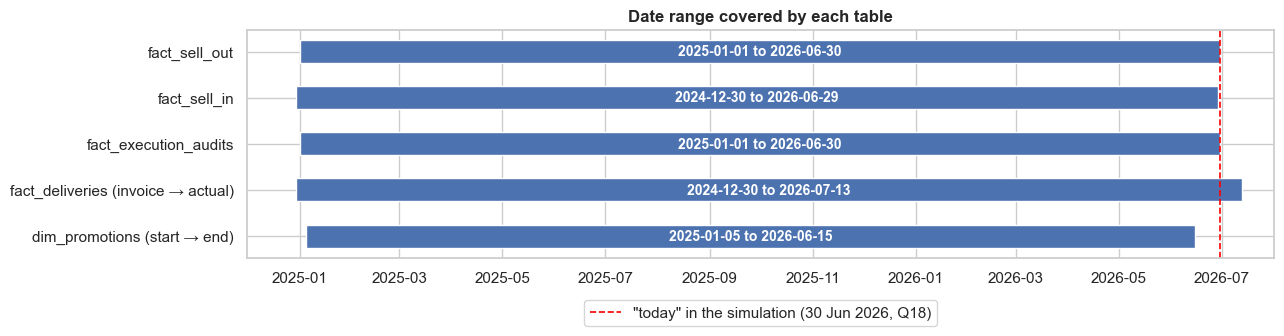

Deliveries that arrive after "today": 3,186 (1.1%), all from invoices dated 2026-06-22 to 2026-06-29


In [9]:
spans = {'fact_sell_out': (sell_out.date.min(), sell_out.date.max()),
         'fact_sell_in': (sell_in.date.min(), sell_in.date.max()),
         'fact_execution_audits': (audits.date.min(), audits.date.max()),
         'fact_deliveries (invoice → actual)': (deliveries.invoice_date.min(), deliveries.actual_delivery.max()),
         'dim_promotions (start → end)': (promos.start_date.min(), promos.end_date.max())}
fig, ax = plt.subplots(figsize=(13, 3.6))
for i, (n, (d0, d1)) in enumerate(spans.items()):
    ax.barh(i, (d1 - d0).days, left=d0, color='#4C72B0', height=0.5)
    ax.text(d0 + (d1 - d0) / 2, i, f'{d0.date()} to {d1.date()}', va='center', ha='center', fontsize=10, color='white', fontweight='bold')
ax.axvline(TODAY, color='red', ls='--', lw=1.2, label='"today" in the simulation (30 Jun 2026, Q18)')
ax.set_yticks(range(len(spans))); ax.set_yticklabels(spans.keys()); ax.invert_yaxis()
ax.set_xlim(pd.Timestamp('2024-12-01'), pd.Timestamp('2026-08-01'))
ax.set_title('Date range covered by each table'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15))
show('03_date_coverage')
after = deliveries.actual_delivery > TODAY
print(f'Deliveries that arrive after "today": {after.sum():,} ({after.mean():.1%}), all from invoices dated '
      f'{deliveries.loc[after, "invoice_date"].min().date()} to {deliveries.loc[after, "invoice_date"].max().date()}')

Sell-out and audits still cover exactly 1 Jan 2025 – 30 Jun 2026, and sell-in still starts on Monday 30 Dec 2024. Two new things:
1. Promotions run from 5 Jan 2025 to 15 Jun 2026, so there are **no planned promos after "today"**. The second-half events of 2025 (Back to School, Fall Cleaning, Holiday Bundle) don't have a 2026 version in the file.
2. **3,186 deliveries (1.1%) arrive after 30 June**, up to 13 July. They come from the last two invoices (22 and 29 June). On "today" the app can only know their *scheduled* dates, so anything showing actual delivery dates has to be cut off at 30 June.

**The analysis window.** Everything above (3.1–3.6) checks structure, keys and formulas, so it uses the full data. From here on, every analysis uses **1 Jan 2025 – 31 May 2026** only. June 2026 is the test month for the OOS model, and patterns like OOS, missingness, refills, promo lift or deliveries vs stock could shape modelling choices, so June has to stay out of them to avoid leakage. For deliveries we keep the ones that arrived by 31 May.

In [10]:
EDA_END = pd.Timestamp('2026-05-31')   # June 2026 = OOS model test month, kept out from here on
sell_out = sell_out[sell_out.date <= EDA_END].reset_index(drop=True)
sell_in = sell_in[sell_in.date <= EDA_END].reset_index(drop=True)                      # last invoice 25 May (covers 25-31 May)
deliveries = deliveries[deliveries.actual_delivery <= EDA_END].reset_index(drop=True)   # deliveries that arrived by 31 May
audits = audits[audits.date <= EDA_END].reset_index(drop=True)
v1 = {n: d[d.date <= EDA_END].reset_index(drop=True) if 'date' in d else d for n, d in v1.items()}
print(f'Analysis window: {sell_out.date.min().date()} to {sell_out.date.max().date()} | sell-out rows {len(sell_out):,} | '
      f'invoice lines {len(sell_in):,} | deliveries {len(deliveries):,} | audit rows {len(audits):,}')

Analysis window: 2025-01-01 to 2026-05-31 | sell-out rows 2,073,975 | invoice lines 263,263 | deliveries 262,929 | audit rows 195,734


### 3.7 The missing days problem (again)
In v1 about 30% of store-days were missing. The note says "OOS fixed from ~30% → 6.8%". We weren't sure what the ~30% refers to: our v1 OOS rate was ~6%, while ~30% was the share of missing store-days. So we measured both again.

In [11]:
store_days = sell_out[['store_id', 'date']].drop_duplicates()
all_days = pd.date_range(sell_out.date.min(), sell_out.date.max(), freq='D')
expected = len(stores) * len(all_days)
print(f'Store-days expected: {expected:,} | recorded: {len(store_days):,} | missing: {1 - len(store_days) / expected:.1%}   (v1: 30.3%)')

assortment = sell_out[['store_id', 'sku_id']].drop_duplicates()
skus_per_store = assortment.groupby('store_id').sku_id.nunique()
rows_per_store_day = sell_out.groupby(['store_id', 'date']).size()
full_days = (rows_per_store_day.values == skus_per_store.reindex(rows_per_store_day.index.get_level_values('store_id')).values).mean()
print(f'Recorded store-days where every SKU of the store is present: {full_days:.1%}')
missing_per_day = len(stores) - store_days.groupby('date').size()
print(f'Stores missing per day: min {missing_per_day.min()} | max {missing_per_day.max()}   (v1: exactly 67 every day)')

Store-days expected: 114,036 | recorded: 104,748 | missing: 8.1%   (v1: 30.3%)


Recorded store-days where every SKU of the store is present: 100.0%
Stores missing per day: min 18 | max 18   (v1: exactly 67 every day)


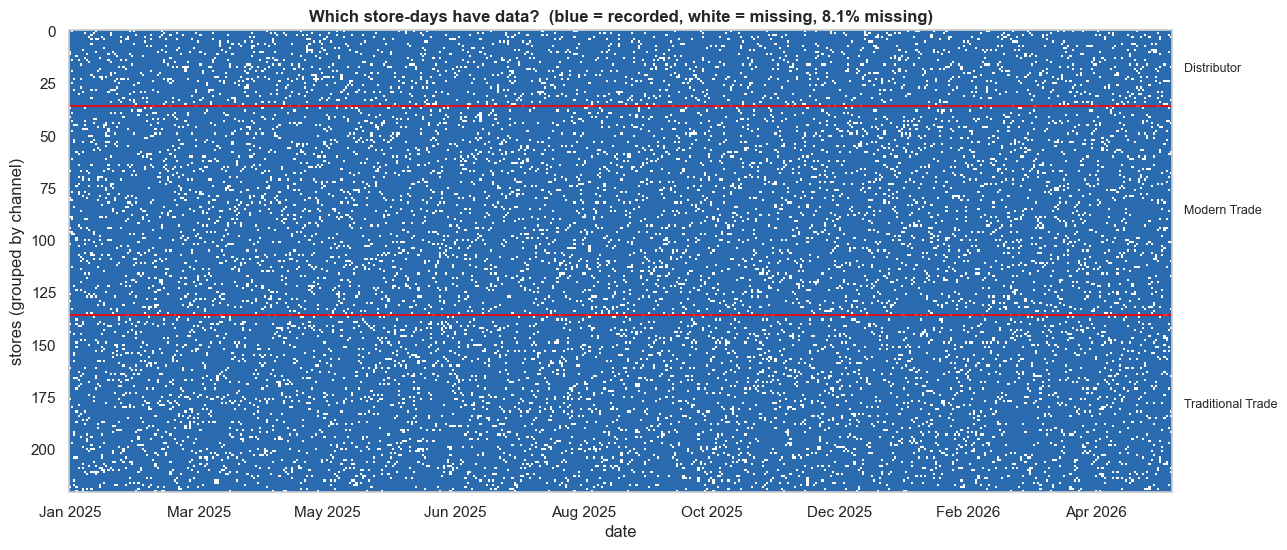

In [12]:
presence = (store_days.assign(v=1).pivot(index='store_id', columns='date', values='v')
            .reindex(columns=all_days).fillna(0))
presence = presence.reindex(stores.sort_values(['channel', 'store_id']).store_id)

fig, ax = plt.subplots(figsize=(15, 6))
ax.imshow(presence.values, aspect='auto', cmap=ListedColormap(['white', '#2b6cb0']), interpolation='nearest')
ax.grid(False)
ax.set_title(f'Which store-days have data?  (blue = recorded, white = missing, {1 - presence.values.mean():.1%} missing)')
ax.set_ylabel('stores (grouped by channel)'); ax.set_xlabel('date')
ticks = np.arange(0, len(all_days), 60)
ax.set_xticks(ticks); ax.set_xticklabels([all_days[i].strftime('%b %Y') for i in ticks])
ch_counts = stores.channel.value_counts().sort_index()
edges = ch_counts.cumsum().values
for e in edges[:-1]:
    ax.axhline(e - 0.5, color='red', lw=1.2)
for ch, s0, e in zip(ch_counts.index, np.r_[0, edges[:-1]], edges):
    ax.text(len(all_days) + 5, (s0 + e) / 2, ch, va='center', fontsize=9)
fig.subplots_adjust(right=0.86)
show('03_missing_store_days_heatmap', tight=False)

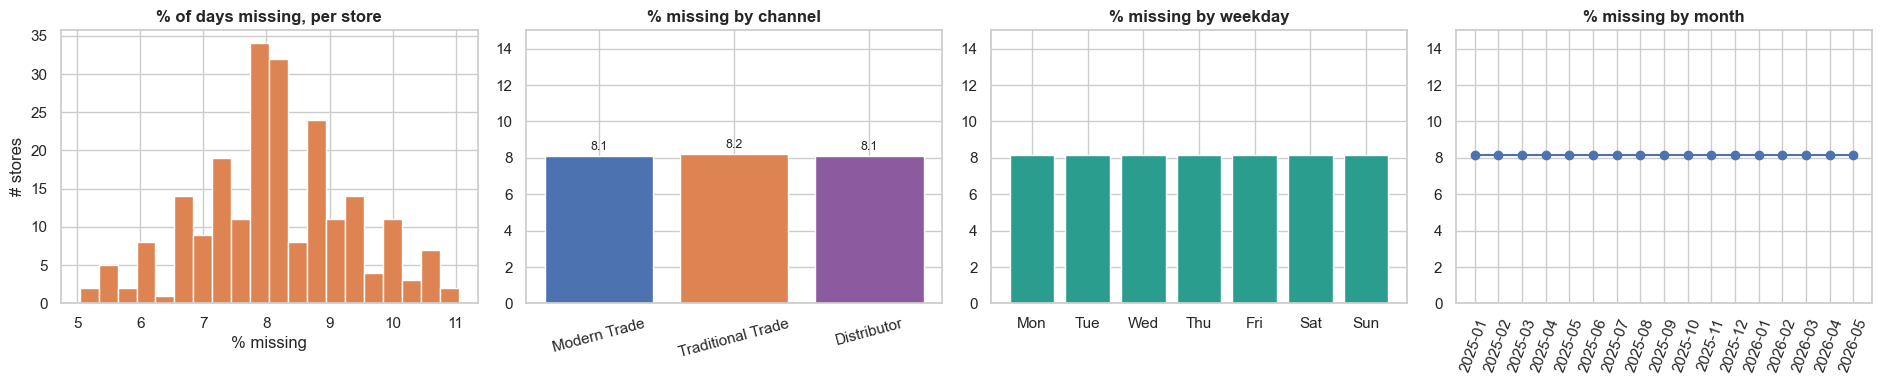

Missing per store: min 5.0% | median 8.1% | max 11.0%
Spread of missing % across stores: 1.21% | what pure chance would give: 1.20%


In [13]:
missing_by_store = 1 - presence.mean(axis=1)
daily_presence = presence.mean(axis=0)
dow_missing = 1 - daily_presence.groupby(all_days.dayofweek).mean()
month_missing = 1 - daily_presence.groupby(all_days.to_period('M')).mean()
ch_missing = missing_by_store.groupby(stores.set_index('store_id').channel).mean().reindex(CH_ORDER)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
axes[0].hist(missing_by_store * 100, bins=20, color='#DD8452'); axes[0].set_title('% of days missing, per store')
axes[0].set_xlabel('% missing'); axes[0].set_ylabel('# stores')
axes[1].bar(ch_missing.index, ch_missing.values * 100, color=[CH_COL[c] for c in ch_missing.index])
axes[1].set_title('% missing by channel'); axes[1].set_ylim(0, 15); axes[1].tick_params(axis='x', rotation=15); label_bars(axes[1])
axes[2].bar(DAYS, dow_missing.values * 100, color='#2A9D8F'); axes[2].set_title('% missing by weekday'); axes[2].set_ylim(0, 15)
axes[3].plot(month_missing.index.astype(str), month_missing.values * 100, marker='o')
axes[3].set_title('% missing by month'); axes[3].set_ylim(0, 15); axes[3].tick_params(axis='x', rotation=70)
show('03_missing_patterns')
p_miss = 1 - presence.values.mean()
print(f'Missing per store: min {missing_by_store.min():.1%} | median {missing_by_store.median():.1%} | max {missing_by_store.max():.1%}')
print(f'Spread of missing % across stores: {missing_by_store.std():.2%} | what pure chance would give: {np.sqrt(p_miss * (1 - p_miss) / len(all_days)):.2%}')

**What we found**
1. Missing store-days dropped from **30.3% to 8.1%**. So the client did fix the big gap problem, and we think this is the "~30%" in the note (the v1 OOS rate was ~6%, never 30%).
2. The *shape* of the gaps is the same as in v1: always a whole store-day, never partial, and **exactly 18 stores are missing every single day** (v1: exactly 67). So it's still "drop a random set of stores each day".
3. There's no pattern by channel (8.1–8.2%), weekday or month, and the spread across stores (1.21 points) is exactly what pure chance gives (1.20). So the gaps are still **missing completely at random**, and averages over reported days are still unbiased.

### 3.8 Internal consistency: does the stock math still add up?
Same idea as v1, on the reported rows:

$$\text{stock}_{today} = \text{stock}_{yesterday} - \text{units sold}_{today} + \text{delivered}_{today}$$

Negative deliveries would be impossible. We split by days since the previous recorded row: if sales happened on the missing days, stock would drop by more than the recorded sales right after a gap.

In [14]:
so = sell_out.sort_values(['store_id', 'sku_id', 'date']).reset_index(drop=True)
g = so.groupby(['store_id', 'sku_id'])
so['gap_days'] = g.date.diff().dt.days
so['prev_inv'] = g.inventory_level.shift()
so['delivered'] = so.inventory_level - (so.prev_inv - so.units_sold_daily)   # units that must have arrived

gap_check = (so.dropna(subset=['gap_days'])
               .assign(days_since_last_record=lambda d: d.gap_days.clip(upper=4).astype(int).astype(str).replace({'4': '4+'}))
               .groupby('days_since_last_record')
               .agg(rows=('delivered', 'size'),
                    stock_math_exact=('delivered', lambda x: (x == 0).mean()),
                    delivery_seen=('delivered', lambda x: (x > 0).mean()),
                    stock_dropped_more_than_sales=('delivered', lambda x: (x < 0).mean())))
display(gap_check.round(3))
print('Rows with negative deliveries (impossible):', int((so.delivered < 0).sum()))

# does fact_deliveries record a delivery on the days a store didn't report?
sd = presence.rename_axis(columns='date').stack().rename('reported').reset_index()
dlv_days = (deliveries[['store_id', 'actual_delivery']].drop_duplicates()
            .rename(columns={'actual_delivery': 'date'}).assign(delivery_recorded=True))
sd = sd.merge(dlv_days, on=['store_id', 'date'], how='left')
sd['delivery_recorded'] = sd.delivery_recorded.eq(True)
print(f"Store-days with at least one delivery in fact_deliveries: missing store-days {sd.loc[sd.reported == 0, 'delivery_recorded'].mean():.1%} "
      f"| reported store-days {sd.loc[sd.reported == 1, 'delivery_recorded'].mean():.1%}")
del sd, dlv_days

,rows,stock_math_exact,delivery_seen,stock_dropped_more_than_sales
days_since_last_record,,,,
1,1902356,0.932,0.068,0.0
2,153180,0.933,0.067,0.0
3,12825,0.932,0.068,0.0
4+,1239,0.928,0.072,0.0


Rows with negative deliveries (impossible): 0
Store-days with at least one delivery in fact_deliveries: missing store-days 75.3% | reported store-days 76.0%


Same result as v1 on the reported rows: the stock math is **exact** (zero impossible rows). After a gap of 2, 3 or 4+ days, the stock never drops by more than the sales recorded on the next reported day, and refills show up at the same ~7% rate with or without a gap. So in `fact_sell_out`, **the inventory looks frozen across missing days**: the next reported stock picks up exactly where the last one left off.

That doesn't mean nothing happened on those days:
1. **Sales are unknown, not zero.** The store simply didn't report them (Dr. Masse, Q11: not reported, not zero sales).
2. `fact_deliveries` records at least one delivery on **75.3%** of missing store-days, about the same rate as on reported days (76.0%). This fits 3.9: the delivery table isn't linked to the sell-out stock at all.

So the data only suggests that the sell-out inventory is frozen across missing days in the simulation. In this EDA we carry the last reported stock forward (which is how the sell-out inventory behaves) and use averages per *reported* day for sales. How to fill gap-day sales is a separate question for the missing-data notebook; with 8% gaps instead of 30%, it also matters much less now.

### 3.9 Do the new deliveries explain the stock refills?
This was the check we were most excited about. In v1 (and in our imputation work) the biggest blocker for the OOS model was that **we couldn't know when the next delivery lands**. We even listed "planned delivery dates" as our main data ask. `fact_deliveries` now has scheduled and actual delivery dates. So the first question: when the stock jumps up in sell-out (a refill), is there a delivery in `fact_deliveries` on that day, with the same number of units?

,stock_refills_per_store_sku,deliveries_per_store_sku,avg_refill_units,avg_delivery_units,refill_units_÷_sellout,delivered_units_÷_sellout
store_id,,,,,,
Modern Trade,33.74,73.96,88.02,45.34,0.98,1.10
Traditional Trade,29.36,36.96,48.68,21.67,0.97,0.54
Distributor,34.34,73.99,74.71,39.00,0.98,1.10


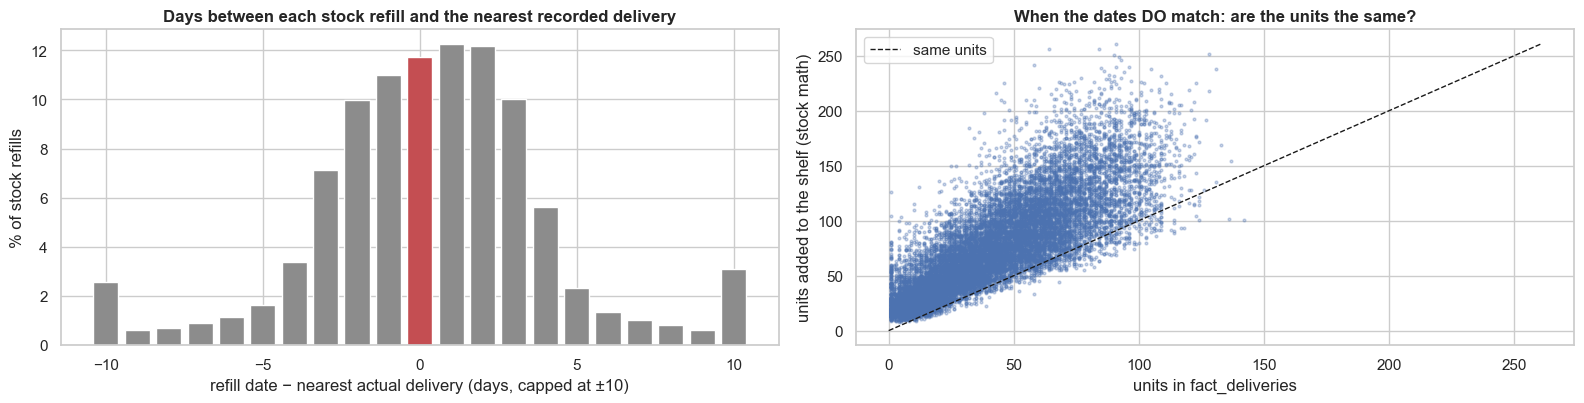

Stock refills with a recorded delivery on the same day: 11.7% (if the two were unrelated we would expect about 11.6% just by chance)
...and of those, same number of units: 0.6%


In [15]:
refills = so.loc[so.delivered > 0, ['store_id', 'sku_id', 'date', 'delivered', 'prev_inv']].sort_values('date')
dlv = deliveries[['store_id', 'sku_id', 'actual_delivery', 'units_delivered']].sort_values('actual_delivery')
near = pd.merge_asof(refills, dlv, left_on='date', right_on='actual_delivery', by=['store_id', 'sku_id'], direction='nearest')
near['offset'] = (near.date - near.actual_delivery).dt.days

pairs_ch = assortment.store_id.map(ch_of).value_counts()
so_ch = so.store_id.map(ch_of)
refill_vs_dlv = pd.DataFrame({
    'stock_refills_per_store_sku': refills.store_id.map(ch_of).value_counts() / pairs_ch,
    'deliveries_per_store_sku': deliveries.store_id.map(ch_of).value_counts() / pairs_ch,
    'avg_refill_units': refills.groupby(refills.store_id.map(ch_of)).delivered.mean(),
    'avg_delivery_units': deliveries.groupby(deliveries.store_id.map(ch_of)).units_delivered.mean(),
    'refill_units_÷_sellout': refills.groupby(refills.store_id.map(ch_of)).delivered.sum() / so.groupby(so_ch).units_sold_daily.sum(),
    'delivered_units_÷_sellout': deliveries.groupby(deliveries.store_id.map(ch_of)).units_delivered.sum() / so.groupby(so_ch).units_sold_daily.sum(),
}).reindex(CH_ORDER).round(2)
display(refill_vs_dlv)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
off = near.offset.clip(-10, 10).value_counts(normalize=True).sort_index() * 100
axes[0].bar(off.index, off.values, color=['#C44E52' if i == 0 else '#8C8C8C' for i in off.index])
axes[0].set_title('Days between each stock refill and the nearest recorded delivery'); axes[0].set_xlabel('refill date − nearest actual delivery (days, capped at ±10)')
axes[0].set_ylabel('% of stock refills')
same = near[near.offset == 0]
axes[1].scatter(same.units_delivered, same.delivered, s=4, alpha=0.3, color='#4C72B0')
lim = max(same.units_delivered.max(), same.delivered.max())
axes[1].plot([0, lim], [0, lim], 'k--', lw=1, label='same units')
axes[1].set_xlabel('units in fact_deliveries'); axes[1].set_ylabel('units added to the shelf (stock math)'); axes[1].legend()
axes[1].set_title('When the dates DO match: are the units the same?')
show('03_refills_vs_deliveries')
chance = len(deliveries) / (len(assortment) * len(all_days))
print(f'Stock refills with a recorded delivery on the same day: {(near.offset == 0).mean():.1%} '
      f'(if the two were unrelated we would expect about {chance:.1%} just by chance)')
print(f'...and of those, same number of units: {(same.delivered == same.units_delivered).mean():.1%}')

**What we found**
Unfortunately, no. The new delivery table **does not explain the stock refills** in sell-out:
1. Only **11.7%** of refills have a recorded delivery on the same day, which is exactly what pure chance would give (11.6%). In the histogram, day 0 is no taller than ±1 or ±2. If deliveries caused the refills, almost all of them would sit at 0.
2. When the dates *do* match, the units almost never do (0.6%). Shelf refills are about **twice as big** as deliveries.
3. The counts don't match either: over the 17 months a Modern Trade store-SKU gets **74 weekly deliveries**, but its shelf is refilled only **~34 times**.
4. The totals tell the story. Refilled units ≈ 98% of sell-out (the stock simulation balances itself), while delivered units are **110%** of sell-out for MT and Distributors and **54%** for Traditional Trade. Those are exactly the sell-in ratios from v1. So `fact_deliveries` was generated from **sell-in**, separately from the stock in sell-out.

Why this matters: in our imputation write-up, "planned delivery dates" were the one input we expected to fix the precision problem. These dates can't do that, because they aren't the dates the shelf actually gets refilled. It's our top question for Dr. Masse (section 10).

### 3.10 Outliers
Same 1.5 × IQR rule as v1, on the main numeric columns (including the new ones):

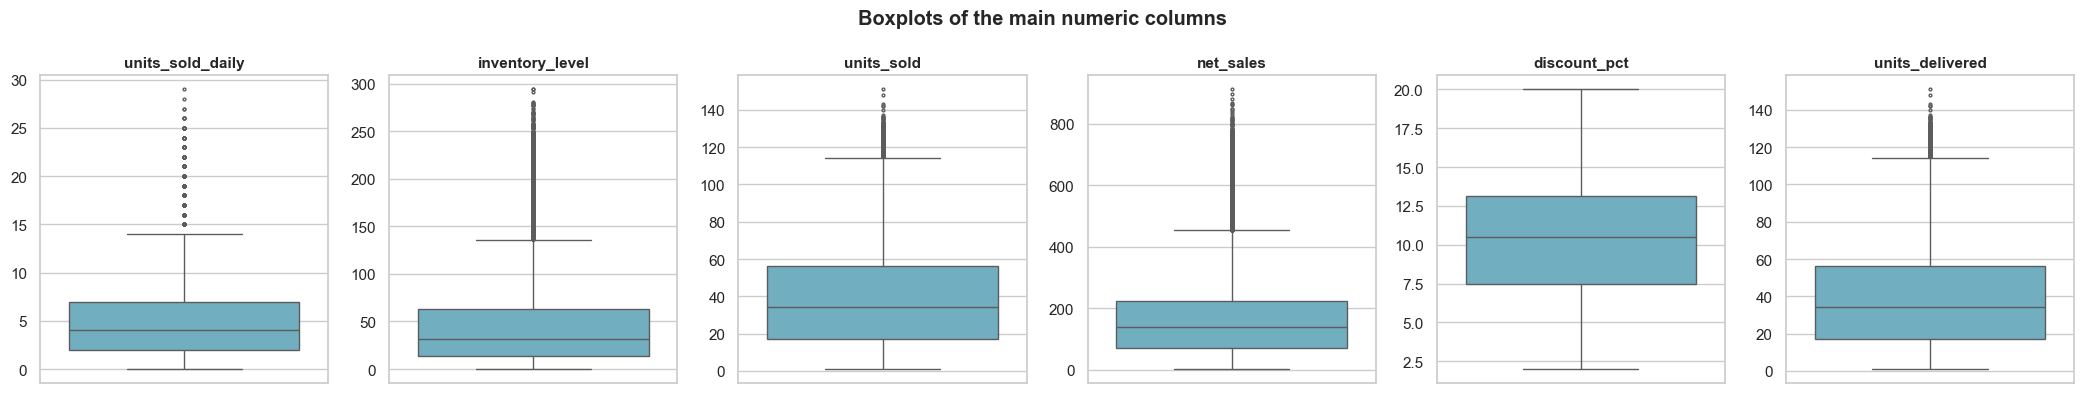

,column,min,median,max,upper_fence,outlier_%
0,fact_sell_out.units_sold_daily,0.00,4.00,32.00,14.500,2.59
1,fact_sell_out.inventory_level,0.00,32.00,305.00,136.500,3.83
2,fact_sell_in.units_sold,1.00,34.00,151.00,114.500,0.23
3,fact_sell_in.net_sales,2.29,139.91,932.92,455.170,2.65
4,fact_sell_in.discount_pct,2.00,10.48,20.00,21.565,0.00
5,fact_deliveries.units_delivered,1.00,34.00,151.00,114.500,0.21


Where do the "outlier" sales days (> 14.5 units) come from? {'Tier 1': 98.7, 'Tier 2': 1.3}


In [16]:
num_cols = [('fact_sell_out', 'units_sold_daily'), ('fact_sell_out', 'inventory_level'), ('fact_sell_in', 'units_sold'),
            ('fact_sell_in', 'net_sales'), ('fact_sell_in', 'discount_pct'), ('fact_deliveries', 'units_delivered')]
rows = []
fig, axes = plt.subplots(1, 6, figsize=(21, 4))
for ax, (t, c) in zip(axes, num_cols):
    x = tables[t][c]
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    rows.append({'column': f'{t}.{c}', 'min': x.min(), 'median': x.median(), 'max': x.max(),
                 'upper_fence': q3 + 1.5 * iqr, 'outlier_%': round(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100, 2)})
    sns.boxplot(y=x.sample(200_000, random_state=0) if len(x) > 200_000 else x, ax=ax, color='#64B5CD', fliersize=2)
    ax.set_title(c, fontsize=11); ax.set_ylabel('')
plt.suptitle('Boxplots of the main numeric columns', fontweight='bold'); show('03_outliers')
display(pd.DataFrame(rows))

fence = rows[0]['upper_fence']
high = sell_out[sell_out.units_sold_daily > fence].merge(stores[['store_id', 'segment_tier']], on='store_id')
print(f'Where do the "outlier" sales days (> {fence:.1f} units) come from?',
      (high.segment_tier.value_counts(normalize=True) * 100).round(1).to_dict())
del high

Same as v1: only 0–4% of values are flagged, and **98.7%** of the "outlier" sales days come from Tier 1 stores. They're big stores, not errors, so we keep them. The new columns (discount, delivered units) have almost no outliers.

### 3.11 Checking the client's change list
Putting 3.2–3.10 together against the note Dr. Masse sent:

| Client said | What we found | Verified? |
|---|---|---|
| `dim_products`: added `consumer_price` | Yes. It's 1.30–1.40× the list price (Q5 said 20–40% higher) | Yes |
| `fact_sell_out`: added `consumer_price_actual`, `promo_id`, `promo_discount_pct` | Yes, and all of it matches `dim_promotions` | Yes |
| "OOS fixed from ~30% → 6.8%" | OOS is 6.85%. Missing store-days went from 30.3% to 8.1% | Yes (we think "~30%" means the missing days) |
| `fact_sell_in`: added `gross_sales` | Yes; gross = units × list price exactly | Yes |
| `discount_pct` now volume-correlated | Across accounts yes: bigger stores get bigger discounts (8.4). Within a store, a bigger order doesn't get a bigger discount | Partly |
| `fact_sell_in`: added `promo_id` | Yes, blanket per channel × category | Yes |
| New `dim_promotions` | 37 promos of 6 types (4.6) | Yes |
| New `fact_deliveries` | One per invoice line, but not connected to the stock refills, and the "Early" label is wrong | Partly |
| *(not in the note)* | The whole sell-out simulation was regenerated: only 15% of shared rows have the same units | New finding |

### 3.12 Data quality summary

| Check | Result | What we'll do |
|---|---|---|
| Nulls, duplicates, keys | Clean; the only nulls mean "no promo" | Nothing |
| Referential integrity | All IDs and promo links match; promos are blanket | Use `dim_promotions` as a calendar |
| Sales and price arithmetic | Exact | Nothing |
| `fill_rate_pct` | Off on 4.9% of rows (rounding on short shipments) | Compute fill rate from units |
| `delivery_status` | "Early" = one day late | Use the dates; ask Dr. Masse |
| Date range | Ends 30 Jun 2026; 1.1% of deliveries land in July | Cut actual delivery dates at "today" |
| Missing store-days | 8.1% (was 30.3%), whole days, random | Same handling as before, much smaller impact |
| Stock math | Exact on reported days; sell-out stock looks frozen across missing days, although deliveries are recorded on ~75% of them | Carry stock forward; treat gap-day sales as unknown |
| June 2026 | Test month for the OOS model | Left out of every analysis from 3.7 on |
| Deliveries vs stock refills | Not related | Don't use deliveries to explain stock; ask Dr. Masse |
| Data regenerated | Only 15% of shared rows match v1 | Re-check every v1 number |
| Outliers | Real Tier 1 volume | Keep them |

## 4. Univariate analysis
As in v1, we first join store and product info onto sell-out once. One thing is different: v1 had no prices in sell-out, so we valued sales at list price. Now we have the **price the consumer actually paid**, so `sales_value` = units × `consumer_price_actual`. (We keep `list_value` = units × list price for anything about Marvel's own revenue, since list price is the trade price, Q5.)

In [17]:
sof = (so[['date', 'store_id', 'sku_id', 'units_sold_daily', 'inventory_level', 'is_out_of_stock',
           'consumer_price_actual', 'promo_id', 'promo_discount_pct']]
       .merge(stores[['store_id', 'channel', 'region', 'state', 'segment_tier']], on='store_id')
       .merge(products[['sku_id', 'product_name', 'category', 'brand', 'is_msl', 'list_price', 'consumer_price']], on='sku_id'))
sof['on_promo'] = sof.promo_id.notna()
sof['sales_value'] = sof.units_sold_daily * sof.consumer_price_actual
sof['list_value'] = sof.units_sold_daily * sof.list_price
si = (sell_in.merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
             .merge(products[['sku_id', 'category', 'list_price', 'unit_cost']], on='sku_id'))
si['on_promo'] = si.promo_id.notna()
au = audits.merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
dv = (deliveries.merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
                .merge(products[['sku_id', 'category']], on='sku_id'))
dv['lead_scheduled'] = (dv.scheduled_delivery - dv.invoice_date).dt.days
dv['days_vs_schedule'] = (dv.actual_delivery - dv.scheduled_delivery).dt.days
print(sof.shape, si.shape, au.shape, dv.shape)

(2073975, 22) (263263, 16) (195734, 10) (262929, 18)


### 4.1 Stores and products
`dim_stores` didn't change, so this is a quick reminder of who the stores are (details in v1, section 4.1). The product table is the same 23 SKUs with the same cost and list price, plus a new `consumer_price`.

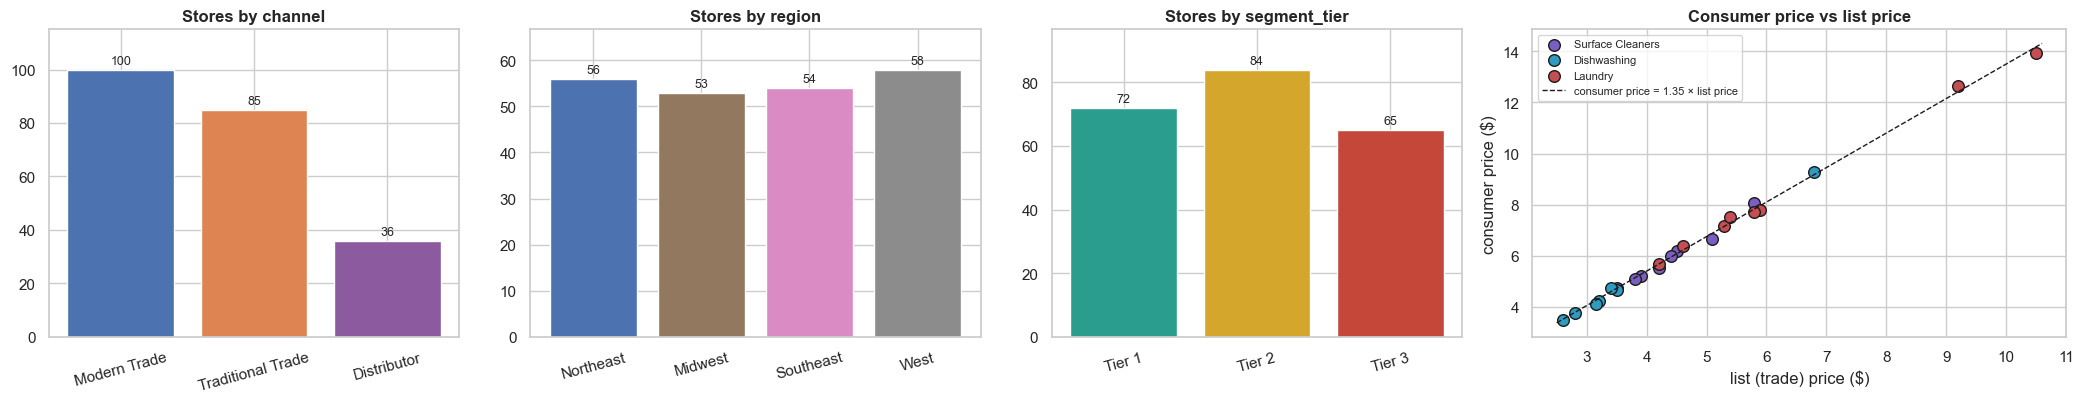

segment_tier,Tier 1,Tier 2,Tier 3
channel,,,
Modern Trade,41,35,24
Traditional Trade,16,39,30
Distributor,15,10,11


,sku_id,product_name,category,is_msl,unit_cost,list_price,consumer_price,consumer_over_list,margin_on_list_pct
0,SKU-1001,Marvel Power Clean Lemon 1L,Surface Cleaners,True,2.10,4.50,6.17,1.37,53.3
1,SKU-1002,Marvel Power Clean Original 1L,Surface Cleaners,True,2.05,4.40,5.98,1.36,53.4
2,SKU-1003,Marvel Power Clean Lavender 750ml,Surface Cleaners,False,1.85,3.90,5.22,1.34,52.6
3,SKU-1004,Marvel Heavy-Duty Degreaser 1L,Surface Cleaners,True,2.80,5.80,8.07,1.39,51.7
4,SKU-1005,Marvel Heavy-Duty Degreaser 500ml,Surface Cleaners,False,1.65,3.50,4.72,1.35,52.9
5,SKU-1006,Marvel Glass & Surface Spray 32oz,Surface Cleaners,True,1.95,4.20,5.52,1.31,53.6
6,SKU-1007,Marvel Bathroom Foam Cleaner 20oz,Surface Cleaners,False,1.75,3.80,5.08,1.34,53.9
7,SKU-1008,Marvel Multi-Surface Wipes 75ct,Surface Cleaners,True,2.45,5.10,6.66,1.31,52.0
8,SKU-1009,Marvel Dish Soap Citrus 28oz,Dishwashing,True,1.50,3.20,4.22,1.32,53.1
9,SKU-1010,Marvel Dish Soap Original 28oz,Dishwashing,True,1.48,3.15,4.10,1.30,53.0


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2), gridspec_kw={'width_ratios': [1, 1.1, 1, 1.3]})
for ax, col, order, pal in zip(axes[:3], ['channel', 'region', 'segment_tier'], [CH_ORDER, REGION_ORDER, TIER_ORDER], [CH_COL, REG_COL, TIER_COL]):
    cnt = stores[col].value_counts().reindex(order)
    ax.bar(cnt.index, cnt.values, color=[pal[x] for x in cnt.index])
    label_bars(ax, '{:.0f}'); ax.set_title(f'Stores by {col}'); ax.tick_params(axis='x', rotation=15); ax.set_ylim(0, cnt.max() * 1.15)
for cat in CAT_ORDER:
    sub = products[products.category == cat]
    axes[3].scatter(sub.list_price, sub.consumer_price, s=70, color=CAT_COL[cat], label=cat, edgecolor='k')
x = np.linspace(2.5, 10.6, 10)
axes[3].plot(x, 1.35 * x, 'k--', lw=1, label='consumer price = 1.35 × list price')
axes[3].set_xlabel('list (trade) price ($)'); axes[3].set_ylabel('consumer price ($)'); axes[3].set_title('Consumer price vs list price'); axes[3].legend(fontsize=8)
show('04_stores_products')
display(pd.crosstab(stores.channel, stores.segment_tier).reindex(CH_ORDER)[TIER_ORDER])
display(products.assign(consumer_over_list=lambda d: (d.consumer_price / d.list_price).round(2),
                        margin_on_list_pct=lambda d: ((d.list_price - d.unit_cost) / d.list_price * 100).round(1))
                [['sku_id', 'product_name', 'category', 'is_msl', 'unit_cost', 'list_price', 'consumer_price', 'consumer_over_list', 'margin_on_list_pct']])

**Notes**
1. Same 221 stores as v1: 100 Modern Trade, 85 Traditional Trade, 36 Distributors. Modern Trade is mostly Tier 1; Traditional Trade is mostly Tier 2 and 3.
2. The new **consumer price is 1.30–1.40× the list price** for every SKU, which fits Q5 ("typically 20–40% higher"). So now we have two prices: what Marvel charges the store (list) and what the shopper pays (consumer).
3. Unit cost and list price didn't change, so the margin on list price is still 51–54% everywhere.

### 4.2 Daily sales (sell-out)

,count,mean,std,min,25%,50%,75%,max,zero_sales_share
v1,1565789.0,4.73,3.87,0.0,2.0,4.0,7.0,32.0,0.117
v2,2073975.0,5.03,4.06,0.0,2.0,4.0,7.0,32.0,0.116


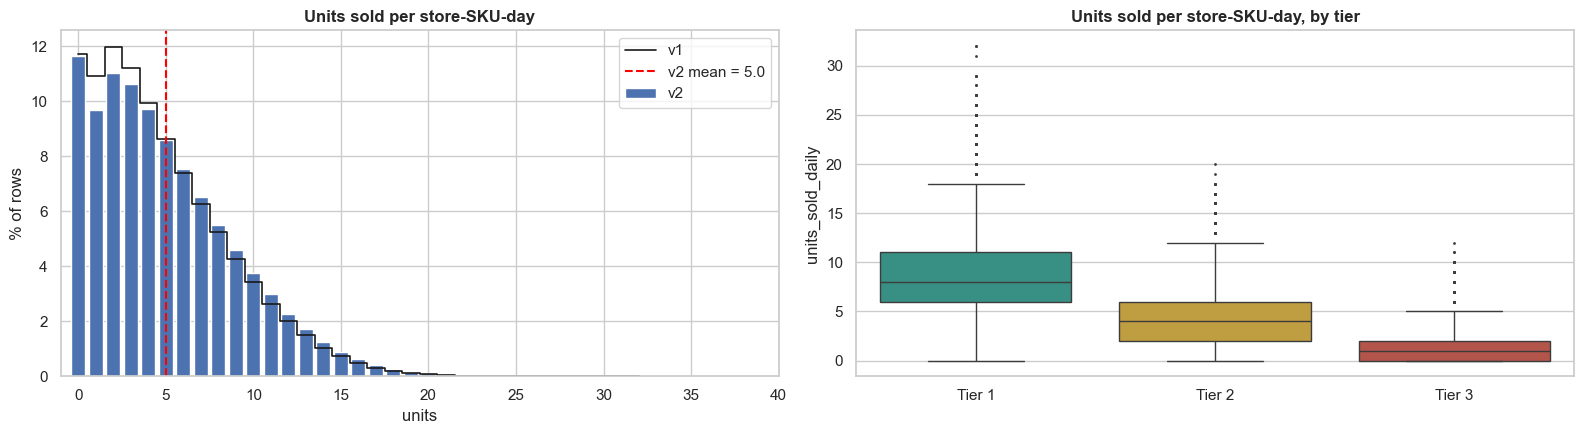

In [19]:
u, u1 = sof.units_sold_daily, v1['fact_sell_out'].units_sold_daily
display(pd.DataFrame({'v1': u1.describe(), 'v2': u.describe()}).T.round(2).assign(zero_sales_share=[(u1 == 0).mean().round(3), (u == 0).mean().round(3)]))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
vc = u.value_counts(normalize=True).sort_index() * 100
vc1 = u1.value_counts(normalize=True).sort_index() * 100
axes[0].bar(vc.index, vc.values, color='#4C72B0', label='v2')
axes[0].step(vc1.index, vc1.values, where='mid', color='k', lw=1.2, label='v1')
axes[0].axvline(u.mean(), color='red', ls='--', label=f'v2 mean = {u.mean():.1f}')
axes[0].set_title('Units sold per store-SKU-day'); axes[0].set_xlabel('units'); axes[0].set_ylabel('% of rows'); axes[0].legend(); axes[0].set_xlim(-1, 40)
samp = sof.sample(300_000, random_state=1)
sns.boxplot(data=samp, x='segment_tier', y='units_sold_daily', order=TIER_ORDER, hue='segment_tier', palette=TIER_COL, legend=False, ax=axes[1], fliersize=1)
axes[1].set_title('Units sold per store-SKU-day, by tier'); axes[1].set_xlabel('')
show('04_daily_sales')

**Notes:** Daily sales look almost the same as in v1: median 4 units, max 32, about 12% zero-sales days, and still right-skewed count data. The mean went up slightly (4.73 → 5.03). Tier is still the big split.

### 4.3 Stock levels

,count,mean,std,min,25%,50%,75%,max
v1,1565789.0,45.7,42.8,0.0,14.0,32.0,65.0,315.0
v2,2073975.0,44.4,40.8,0.0,14.0,33.0,64.0,305.0


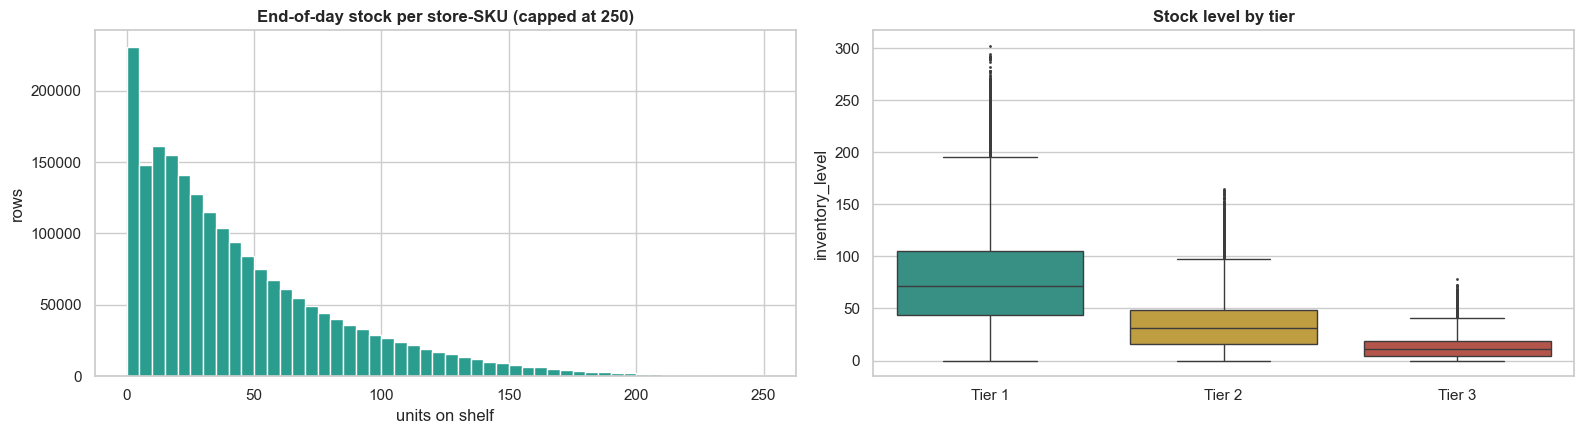

In [20]:
inv, inv1 = sof.inventory_level, v1['fact_sell_out'].inventory_level
display(pd.DataFrame({'v1': inv1.describe(), 'v2': inv.describe()}).T.round(1))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(inv.clip(upper=250), bins=50, color='#2A9D8F')
axes[0].set_title('End-of-day stock per store-SKU (capped at 250)'); axes[0].set_xlabel('units on shelf'); axes[0].set_ylabel('rows')
sns.boxplot(data=samp, x='segment_tier', y='inventory_level', order=TIER_ORDER, hue='segment_tier', palette=TIER_COL, legend=False, ax=axes[1], fliersize=1)
axes[1].set_title('Stock level by tier'); axes[1].set_xlabel('')
show('04_stock_levels')

**Notes:** Also very close to v1 (median 33 units, max 305), with the same spike at 0 for the OOS days. Tier 3 stores keep only about 13 units of a SKU on the shelf on average, which already hints at why they run out so often (8.1, 8.2).

### 4.4 Prices and promotions in sell-out (new)
v1 had no price column in sell-out at all. Now every row has the price the consumer paid and, if a promo was running, the promo and its discount.

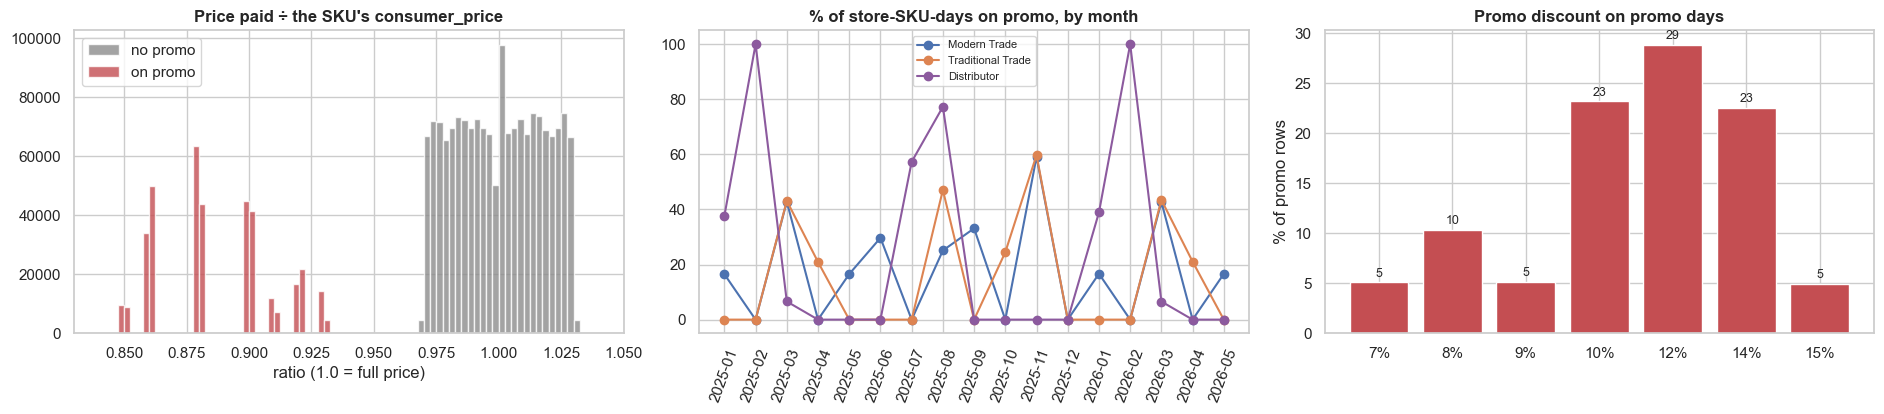

Store-SKU-days on promo: 18.0% | everyday price range: 0.969 to 1.031


In [21]:
sof['price_vs_consumer_price'] = sof.consumer_price_actual / sof.consumer_price
fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
for flag, col, lbl in [(False, '#8C8C8C', 'no promo'), (True, '#C44E52', 'on promo')]:
    axes[0].hist(sof.loc[sof.on_promo == flag, 'price_vs_consumer_price'], bins=np.arange(0.84, 1.04, 0.0025), color=col, alpha=0.8, label=lbl)
axes[0].set_title('Price paid ÷ the SKU\'s consumer_price'); axes[0].set_xlabel('ratio (1.0 = full price)'); axes[0].legend()
promo_share = sof.groupby([sof.date.dt.to_period('M'), 'channel']).on_promo.mean().unstack()[CH_ORDER] * 100
for ch in CH_ORDER:
    axes[1].plot(promo_share.index.astype(str), promo_share[ch], marker='o', color=CH_COL[ch], label=ch)
axes[1].set_title('% of store-SKU-days on promo, by month'); axes[1].tick_params(axis='x', rotation=70); axes[1].legend(fontsize=8)
dist = sof.loc[sof.on_promo, 'promo_discount_pct'].value_counts(normalize=True).sort_index() * 100
axes[2].bar(dist.index.astype(int).astype(str) + '%', dist.values, color='#C44E52'); label_bars(axes[2], '{:.0f}')
axes[2].set_title('Promo discount on promo days'); axes[2].set_ylabel('% of promo rows')
show('04_prices_promos_sellout')
print(f"Store-SKU-days on promo: {sof.on_promo.mean():.1%} | everyday price range: "
      f"{sof.loc[~sof.on_promo, 'price_vs_consumer_price'].min():.3f} to {sof.loc[~sof.on_promo, 'price_vs_consumer_price'].max():.3f}")

**Notes:**
1. **18.0%** of store-SKU-days are on promo.
2. On normal days the price paid moves evenly within **±3%** of the consumer price (the grey block). On promo days it drops by exactly the promo discount, so the red bars sit at a few fixed levels (7–15% off).
3. Promos are very uneven over time. Distributors are on promo for **all of February** in both years (the Q1 volume deal), and Modern and Traditional Trade peak in March (Spring Clean Blitz, ~43% of days) and November (Holiday Bundle, ~59%).

This is the first time we have real price variation in sell-out. Section 8.5 checks whether sales actually respond to it.

### 4.5 Sell-in (invoices)
`discount_pct` is now its own column (in v1 we had to back it out from net sales ÷ list price).

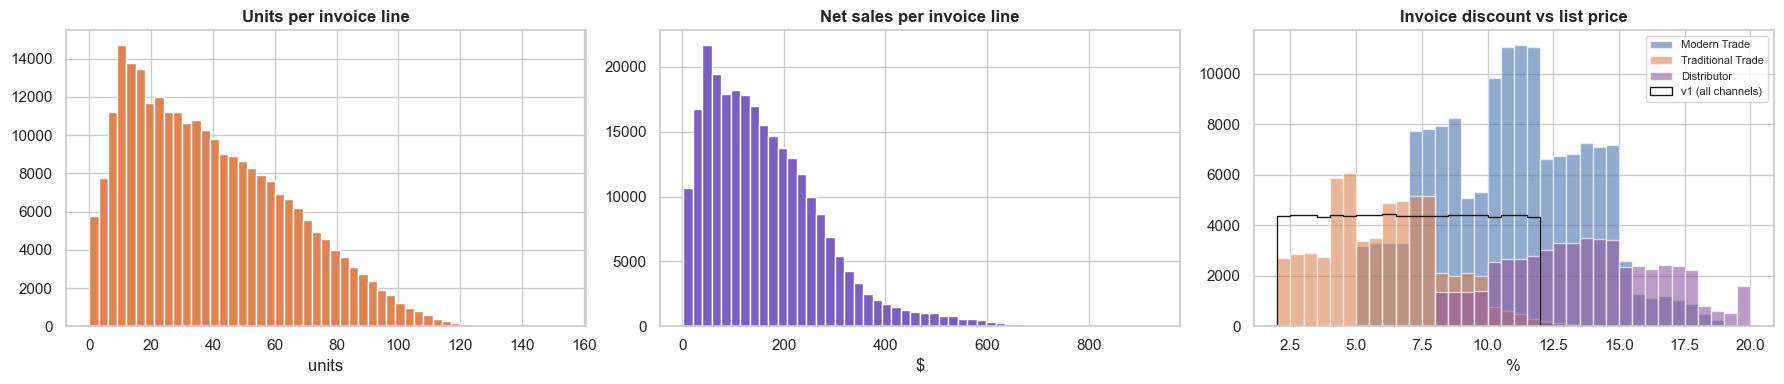

,units_sold,net_sales,discount_pct,promo_share
channel,,,,
Modern Trade,45.75,192.75,10.85,0.176
Traditional Trade,21.87,96.99,6.05,0.154
Distributor,39.37,159.62,13.71,0.243


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(si.units_sold, bins=range(0, 155, 3), color='#DD8452'); axes[0].set_title('Units per invoice line'); axes[0].set_xlabel('units')
axes[1].hist(si.net_sales, bins=50, color='#7A5FC0'); axes[1].set_title('Net sales per invoice line'); axes[1].set_xlabel('$')
for ch in CH_ORDER:
    axes[2].hist(si.loc[si.channel == ch, 'discount_pct'], bins=np.arange(2, 20.5, 0.5), color=CH_COL[ch], alpha=0.6, label=ch)
v1_disc = (1 - v1['fact_sell_in'].net_sales / (v1['fact_sell_in'].units_sold * v1['fact_sell_in'].sku_id.map(products.set_index('sku_id').list_price))) * 100
axes[2].hist(v1_disc, bins=np.arange(2, 20.5, 0.5), histtype='step', color='k', lw=1.2, label='v1 (all channels)', weights=np.full(len(v1_disc), len(si) / len(v1_disc) / 3))
axes[2].set_title('Invoice discount vs list price'); axes[2].set_xlabel('%'); axes[2].legend(fontsize=8)
show('04_sell_in')
display(si.groupby('channel')[['units_sold', 'net_sales', 'discount_pct']].mean().reindex(CH_ORDER).round(2)
          .assign(promo_share=si.groupby('channel').on_promo.mean().round(3)))

**Notes:** A typical invoice line is now ~35 units and ~$142 net (v1: ~23 units and ~$98). The big change is the discount. In v1 it was a flat random 2–12% in every channel (black line); in v2 each channel has its own level: **Traditional Trade ~6%, Modern Trade ~11%, Distributors ~14%**, with a range up to 20%. Promotions are on 15–24% of invoice lines, depending on the channel.

### 4.6 The promotions calendar (new)

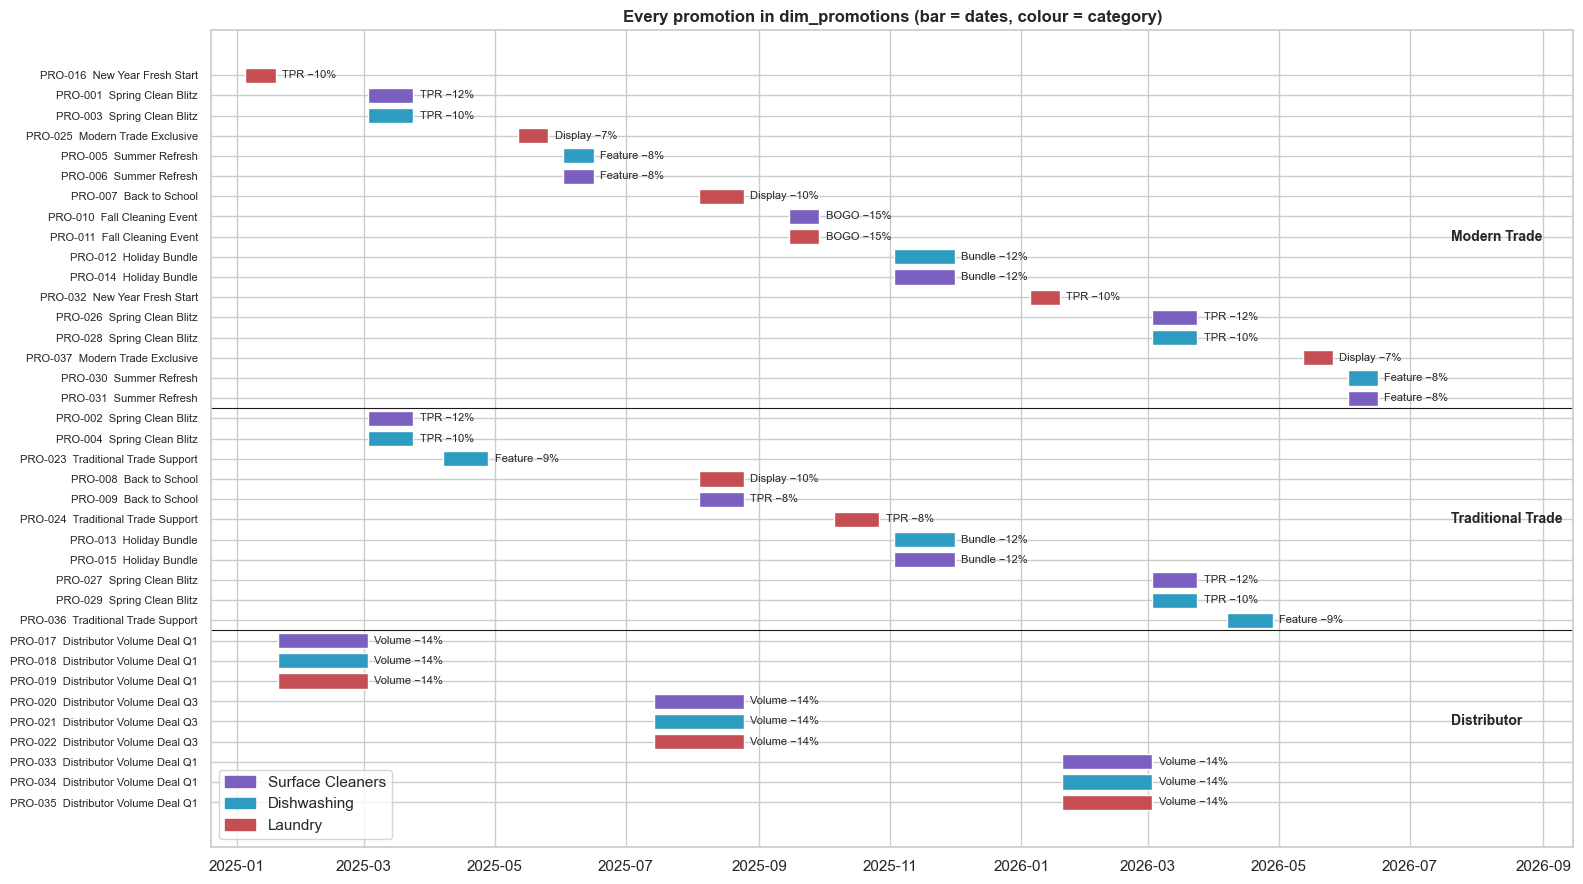

channel,Modern Trade,Traditional Trade,Distributor,discount_range,min_volume
promo_type,,,,,
BOGO,2,0,0,15–15%,80–80
Bundle,2,2,0,12–12%,50–50
Display,3,1,0,7–10%,60–60
Feature,4,2,0,8–9%,20–40
TPR,6,6,0,8–12%,20–50
Volume,0,0,9,14–14%,200–200


In [23]:
p = promos.assign(ch=pd.Categorical(promos.channel, CH_ORDER)).sort_values(['ch', 'start_date']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(16, 9))
for i, r in p.iterrows():
    ax.barh(i, (r.end_date - r.start_date).days + 1, left=r.start_date, color=CAT_COL[r.category], height=0.75)
    ax.text(r.end_date + pd.Timedelta(days=4), i, f'{r.promo_type} −{r.discount_pct:.0f}%', va='center', fontsize=8)
ax.set_yticks(range(len(p))); ax.set_yticklabels(p.promo_id + '  ' + p.promo_name, fontsize=8); ax.invert_yaxis()
for b in p.index[p.ch != p.ch.shift()][1:]:
    ax.axhline(b - 0.5, color='k', lw=0.8)
for ch, grp in p.groupby('ch', observed=True):
    ax.text(pd.Timestamp('2026-07-20'), grp.index.to_numpy().mean(), ch, va='center', fontsize=10, fontweight='bold')
ax.set_xlim(pd.Timestamp('2024-12-20'), pd.Timestamp('2026-09-15'))
ax.legend(handles=[Patch(color=CAT_COL[c], label=c) for c in CAT_ORDER], loc='lower left')
ax.set_title('Every promotion in dim_promotions (bar = dates, colour = category)')
show('04_promo_calendar')
display(pd.crosstab(promos.promo_type, promos.channel)[CH_ORDER].assign(discount_range=promos.groupby('promo_type').discount_pct.agg(lambda s: f'{s.min():.0f}–{s.max():.0f}%'),
                                                                     min_volume=promos.groupby('promo_type').min_volume_units.agg(lambda s: f'{s.min()}–{s.max()}')))

**Notes:**
1. 37 promotions of 6 types. **Distributors only get "Volume" deals** (14% off, minimum 200 units), while Modern Trade gets the widest mix (TPR, Feature, Display, BOGO, Bundle).
2. The calendar repeats each year: New Year Fresh Start in January, Spring Clean Blitz in March, Summer Refresh in June, and so on. The second-half events (Back to School, Fall Cleaning, Holiday Bundle, the Q3 distributor deal) appear only once, because the data stops in June 2026.
3. Promos are timed with the seasons (spring cleaning in March, holidays in November), so we have to separate promo lift from seasonality (6.2 and 8.5).

### 4.7 Deliveries (new)

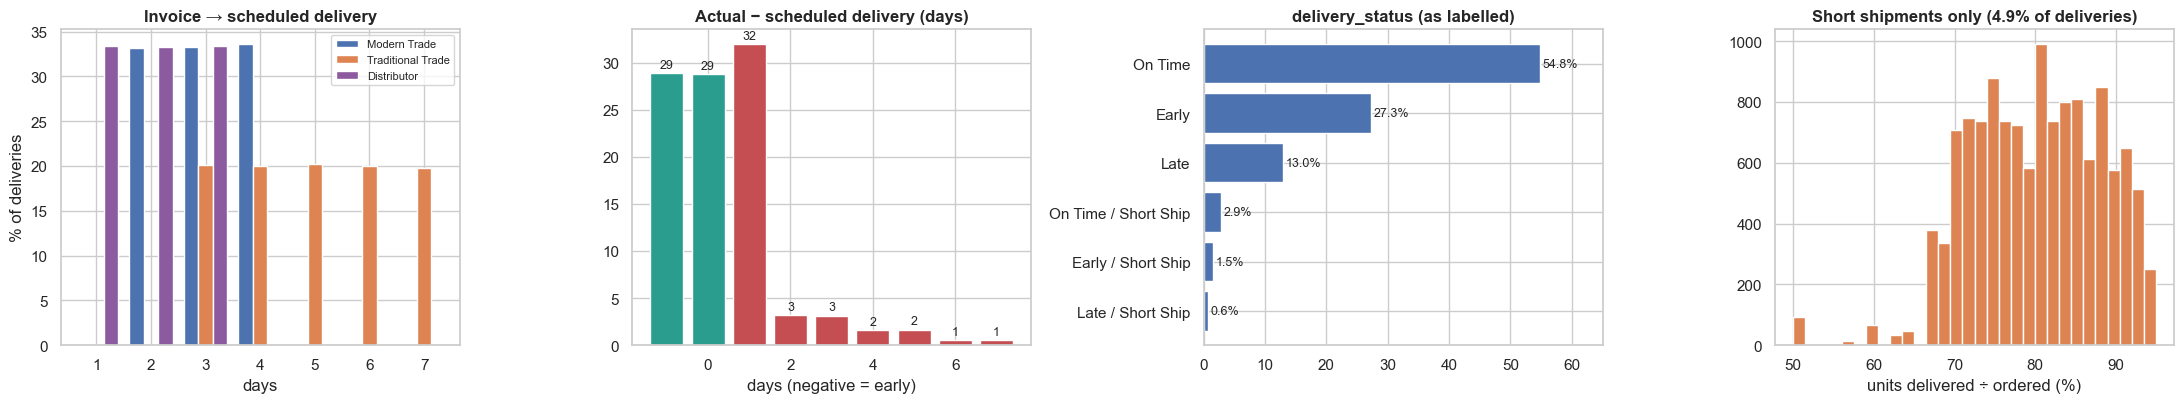

Overall fill rate (units delivered ÷ ordered): 99.1%


In [24]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.2))
lead = dv.groupby(['lead_scheduled', 'channel']).size().unstack()[CH_ORDER].fillna(0)
(lead / lead.sum() * 100).plot.bar(ax=axes[0], color=[CH_COL[c] for c in CH_ORDER], rot=0, width=0.8)
axes[0].set_title('Invoice → scheduled delivery'); axes[0].set_xlabel('days'); axes[0].set_ylabel('% of deliveries'); axes[0].legend(fontsize=8)
dvs = dv.days_vs_schedule.value_counts(normalize=True).sort_index() * 100
axes[1].bar(dvs.index, dvs.values, color=['#2A9D8F' if d <= 0 else '#C44E52' for d in dvs.index]); label_bars(axes[1], '{:.0f}')
axes[1].set_title('Actual − scheduled delivery (days)'); axes[1].set_xlabel('days (negative = early)')
st_share = dv.delivery_status.value_counts(normalize=True).sort_values() * 100
axes[2].barh(st_share.index, st_share.values, color='#4C72B0'); label_bars(axes[2], '{:.1f}%')
axes[2].set_title('delivery_status (as labelled)'); axes[2].set_xlim(0, 65)
short = dv[dv.units_delivered < dv.units_ordered]
axes[3].hist(short.units_delivered / short.units_ordered * 100, bins=30, color='#DD8452')
axes[3].set_title(f'Short shipments only ({len(short) / len(dv):.1%} of deliveries)'); axes[3].set_xlabel('units delivered ÷ ordered (%)')
show('04_deliveries')
print(f"Overall fill rate (units delivered ÷ ordered): {dv.units_delivered.sum() / dv.units_ordered.sum():.1%}")

**Notes:**
1. Each channel has a fixed planned lead time after the Monday invoice, spread evenly: **Distributors 1–3 days, Modern Trade 2–4, Traditional Trade 3–7**.
2. By the dates, **29% arrive a day early, 29% on the day, 32% one day late**, and ~10% are 2–7 days late. (The labels say 27% "Early", see 3.5.)
3. Only **4.9%** of deliveries are short, and when they are, usually 70–95% of the units still arrive. The overall fill rate is **99.1%**, so short shipments are not a big source of lost units.

### 4.8 Audit metrics
`fact_execution_audits` is byte-for-byte the same file as v1, so shelf share, planogram and secondary display look exactly as in v1 section 4.6 (shelf share ~35% with one hump per tier, 83% of audited SKUs planogram-compliant, 44% with a secondary display). We don't repeat those charts here. What *can* change is how audits relate to the new sales data, which we check in 5.5 and 8.7.

## 5. Bivariate and multivariate analysis

### 5.1 Store performance by channel, tier and region
Each dot is one store. Top row: average units per SKU per recorded day (as in v1). Bottom row is new, because OOS behaves very differently in v2: the store's OOS rate.

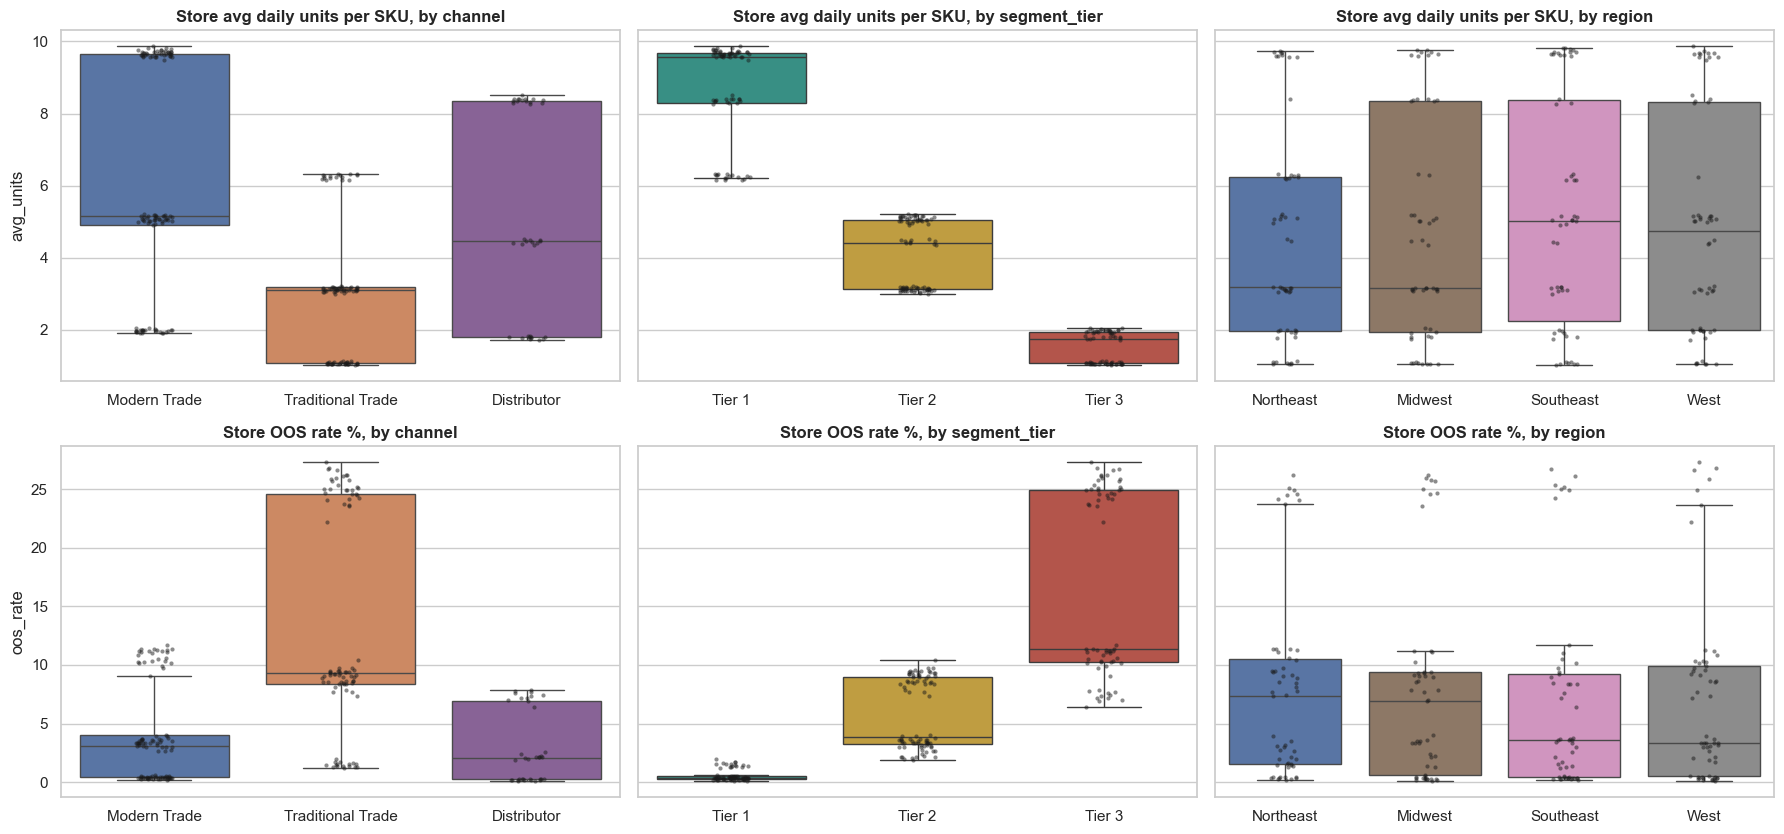

avg_units                                   oos_rate                               
channel      Distributor Modern Trade Traditional Trade Distributor Modern Trade Traditional Trade
segment_tier                                                                                      
Tier 1              8.37         9.67              6.25        0.22         0.39              1.47
Tier 2              4.45         5.07              3.12        2.16         3.35              9.08
Tier 3              1.79         1.98              1.07        7.38        10.95             25.02

In [25]:
store_perf = (sof.groupby('store_id').agg(avg_units=('units_sold_daily', 'mean'), sales_value=('sales_value', 'sum'),
                                         oos_rate=('is_out_of_stock', 'mean'))
                 .join(stores.set_index('store_id')).reset_index())
store_perf['oos_rate'] *= 100
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5), sharey='row')
for j, (col, order, pal) in enumerate(zip(['channel', 'segment_tier', 'region'], [CH_ORDER, TIER_ORDER, REGION_ORDER], [CH_COL, TIER_COL, REG_COL])):
    for i, (metric, lbl) in enumerate([('avg_units', 'avg daily units per SKU'), ('oos_rate', 'OOS rate %')]):
        ax = axes[i, j]
        sns.boxplot(data=store_perf, x=col, y=metric, order=order, hue=col, palette=pal, legend=False, ax=ax, showfliers=False)
        sns.stripplot(data=store_perf, x=col, y=metric, order=order, color='k', size=3, alpha=0.5, ax=ax)
        ax.set_title(f'Store {lbl}, by {col}'); ax.set_xlabel('')
show('05_store_performance')
store_perf.pivot_table(index='segment_tier', columns='channel', values=['avg_units', 'oos_rate'], aggfunc='median').round(2)

**Notes:**
1. Sales look like v1: tier is the strongest split (the median Tier 1 store sells ~9.6 units per SKU per day vs ~1.8 for Tier 3), and stores still stack up at a few levels, one per tier × channel.
2. **OOS is the big change.** In v1 every store sat around 6%. Now the medians range from **~0.2% (Tier 1 Distributors) to ~25% (Tier 3 Traditional Trade)**. The bottom row is basically the top row upside down: the smaller the store, the more it runs out.
3. Region still barely matters; the dots look the same in all four regions.

### 5.2 Where the money comes from
Now valued at what consumers actually paid.

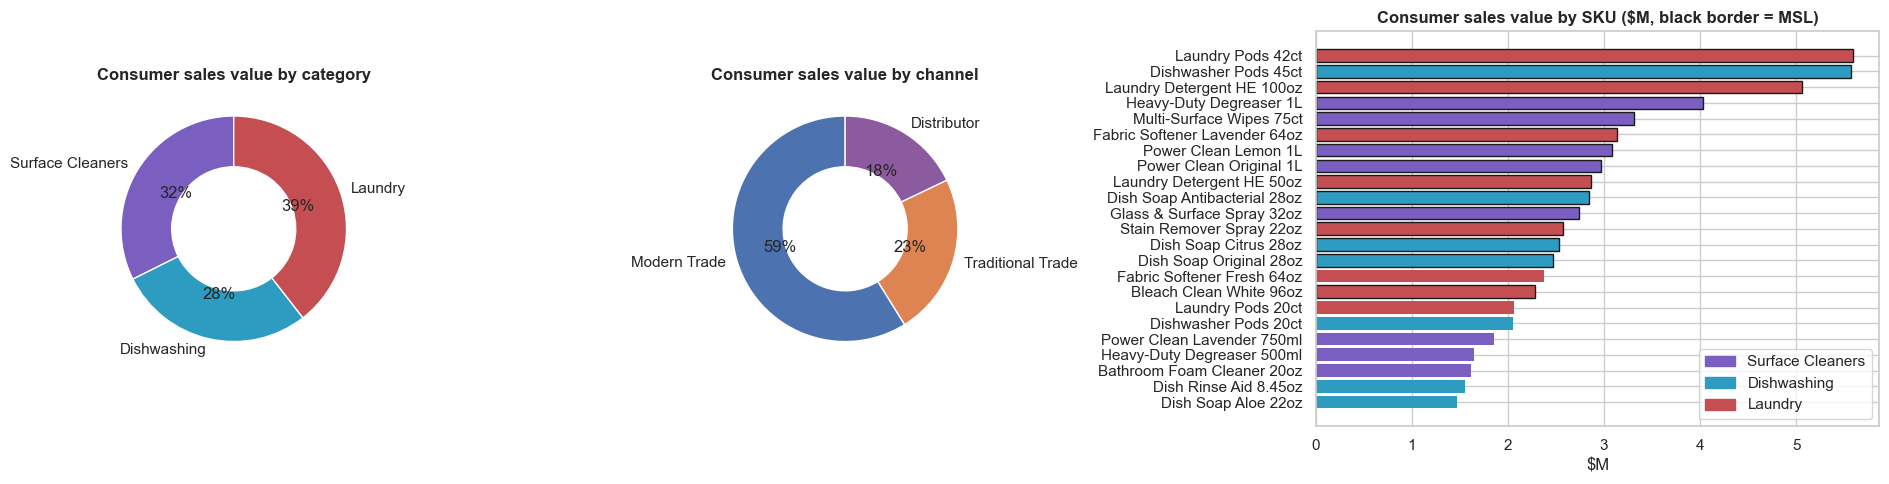

Total consumer sales value: $65.7M | MSL SKUs: 78% | sold on promo: 19% of value, 21% of units


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={'width_ratios': [1, 1, 2]})
for ax, col, order, pal in zip(axes[:2], ['category', 'channel'], [CAT_ORDER, CH_ORDER], [CAT_COL, CH_COL]):
    share = sof.groupby(col).sales_value.sum().reindex(order)
    ax.pie(share, labels=share.index, autopct='%1.0f%%', colors=[pal[x] for x in share.index],
           wedgeprops=dict(width=0.45, edgecolor='w'), startangle=90)
    ax.set_title(f'Consumer sales value by {col}')
sku_val = sof.groupby(['sku_id', 'product_name', 'category', 'is_msl']).sales_value.sum().reset_index().sort_values('sales_value')
axes[2].barh(sku_val.product_name.str.replace('Marvel ', ''), sku_val.sales_value / 1e6,
             color=[CAT_COL[c] for c in sku_val.category], edgecolor=['k' if m else 'none' for m in sku_val.is_msl])
axes[2].set_title('Consumer sales value by SKU ($M, black border = MSL)'); axes[2].set_xlabel('$M')
axes[2].legend(handles=[Patch(color=CAT_COL[c], label=c) for c in CAT_ORDER], loc='lower right')
show('05_sales_value')
msl_share = sof.groupby('is_msl').sales_value.sum()
print(f"Total consumer sales value: ${sof.sales_value.sum() / 1e6:.1f}M | MSL SKUs: {msl_share[True] / msl_share.sum():.0%} "
      f"| sold on promo: {sof.loc[sof.on_promo, 'sales_value'].sum() / sof.sales_value.sum():.0%} of value, {sof.loc[sof.on_promo, 'units_sold_daily'].sum() / sof.units_sold_daily.sum():.0%} of units")

**Notes:** Consumer sales value is **$65.7M** over the 17 months (Jan 2025 – May 2026). The mix is close to v1: Laundry is the biggest category (39%), Modern Trade brings in 59%, and the 15 MSL SKUs make up 78% of value. The top SKUs are still the big packs (Laundry Pods 42ct, Dishwasher Pods 45ct, Laundry Detergent HE 100oz). What's new: **19% of value (21% of units) is sold on promotion**, so promos are a real part of the business now.

### 5.3 How concentrated are sales? (Pareto)
In v1 this was a bar chart with a second y-axis. Here we plot only the cumulative curve (one axis is easier to read): x = share of stores (or SKUs), biggest first; y = share of sales value.

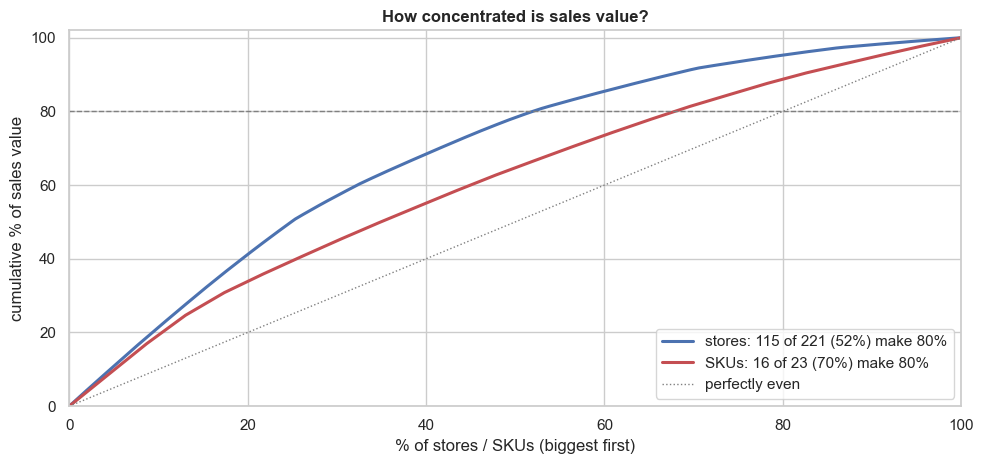

In [27]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for key_col, label, color in [('store_id', 'stores', '#4C72B0'), ('sku_id', 'SKUs', '#C44E52')]:
    s = sof.groupby(key_col).sales_value.sum().sort_values(ascending=False)
    cum = s.cumsum() / s.sum() * 100
    n80 = int((cum < 80).sum() + 1)
    x = np.arange(1, len(s) + 1) / len(s) * 100
    ax.plot(np.r_[0, x], np.r_[0, cum.values], color=color, lw=2.2, label=f'{label}: {n80} of {len(s)} ({n80 / len(s):.0%}) make 80%')
ax.plot([0, 100], [0, 100], color='grey', ls=':', lw=1, label='perfectly even')
ax.axhline(80, color='grey', ls='--', lw=1)
ax.set_xlabel('% of stores / SKUs (biggest first)'); ax.set_ylabel('cumulative % of sales value'); ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_title('How concentrated is sales value?'); ax.legend(loc='lower right')
show('05_pareto')

**Notes:** Still no 80/20: it takes **115 of 221 stores (52%)** and 16 of the 23 SKUs to make 80% of the value (v1: 121 stores and 16 SKUs). So the store visit ranking can't just focus on a few big stores, especially since the stock-outs are in the small ones (5.1).

### 5.4 Geography

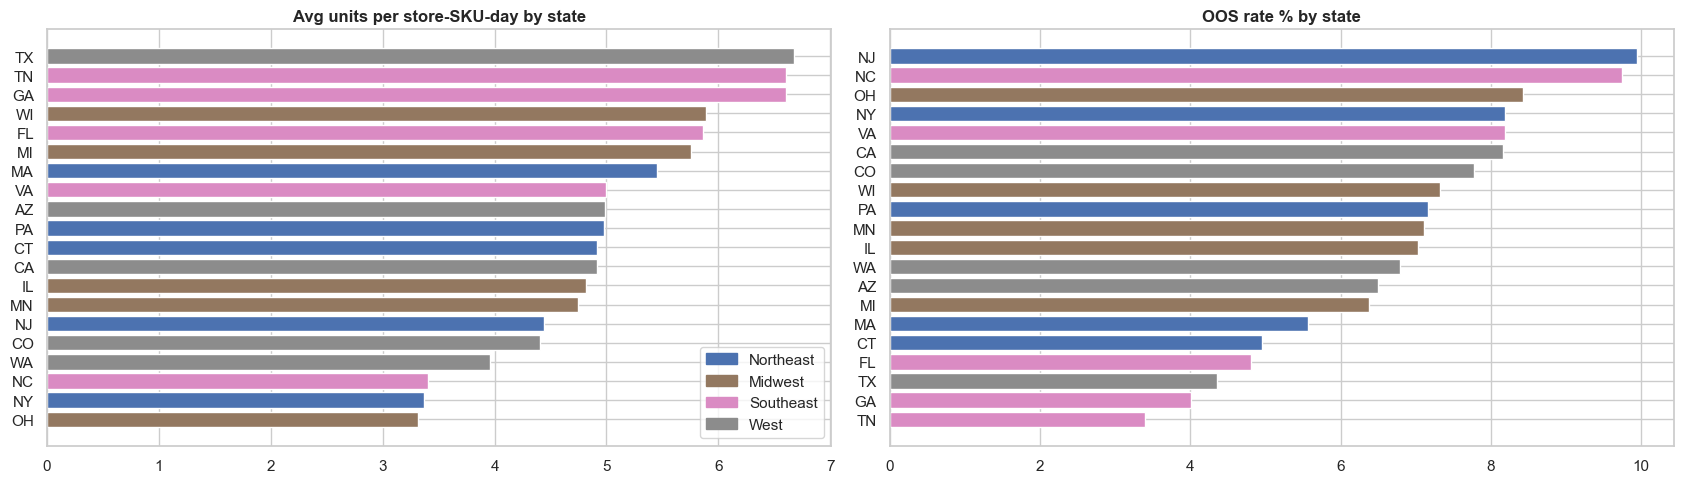

Correlation across states, OOS rate vs share of Tier 3 stores: 0.55


In [28]:
st = (sof.groupby(['state', 'region']).agg(avg_units=('units_sold_daily', 'mean'), oos_rate=('is_out_of_stock', 'mean')).reset_index()
         .merge(stores.groupby('state').segment_tier.apply(lambda s: (s == 'Tier 3').mean() * 100).rename('tier3_share'), on='state'))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, col, title, mult in [(axes[0], 'avg_units', 'Avg units per store-SKU-day by state', 1),
                             (axes[1], 'oos_rate', 'OOS rate % by state', 100)]:
    d = st.sort_values(col)
    ax.barh(d.state, d[col] * mult, color=[REG_COL[r] for r in d.region])
    ax.set_title(title)
axes[0].legend(handles=[Patch(color=REG_COL[r], label=r) for r in REGION_ORDER], loc='lower right')
show('05_geography')
print('Correlation across states, OOS rate vs share of Tier 3 stores:', round(st.oos_rate.corr(st.tier3_share), 2))

**Notes:** Units by state look like v1. OOS by state now varies more, but it follows how many Tier 3 stores each state has (correlation 0.55), not anything regional. So a map would mostly show the tier mix again.

### 5.5 Correlations (store-SKU level)
Same idea as v1 (one row per store-SKU pair), with the new variables added: how often the pair is on promo, the average invoice discount, and delivery delay and fill rate.

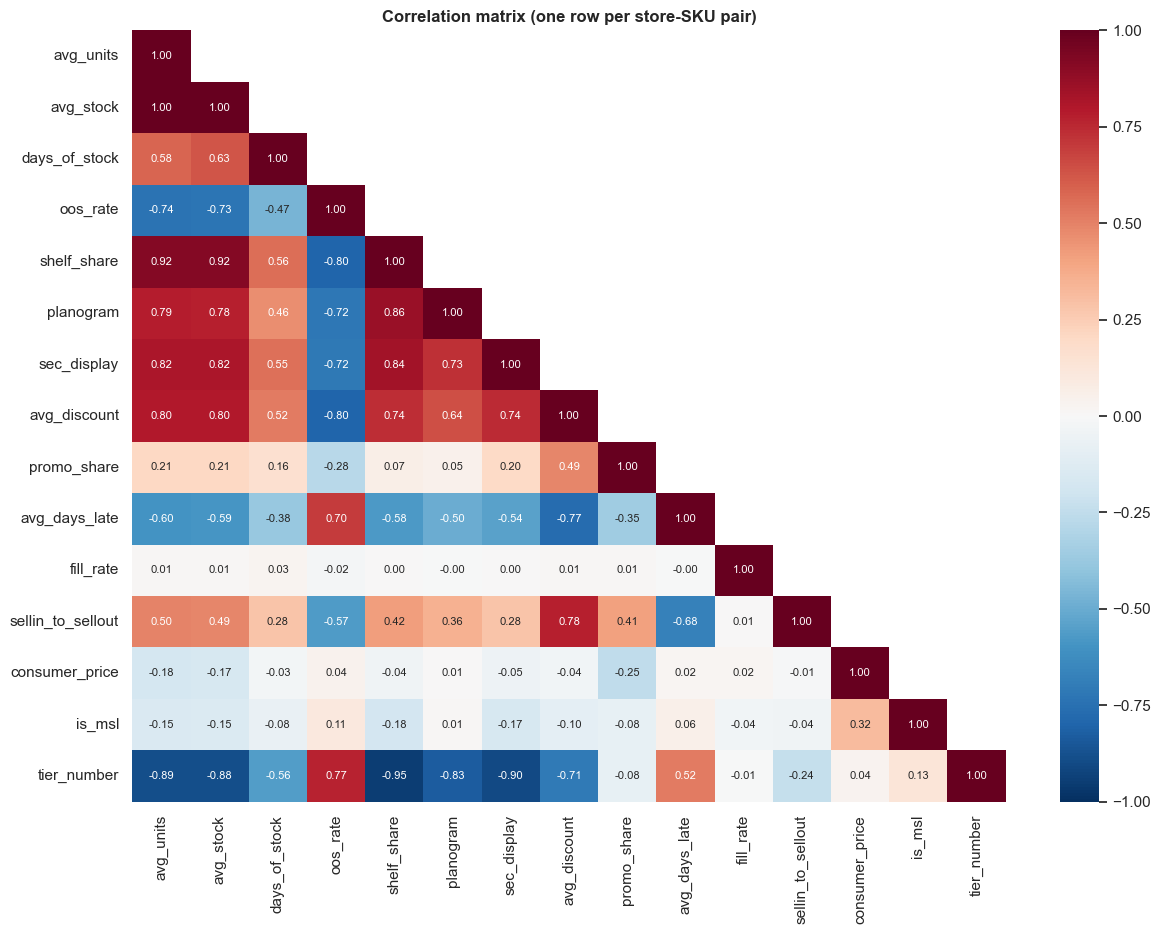

In [29]:
k = ['store_id', 'sku_id']
pair = (so.assign(on_promo=so.promo_id.notna())
          .groupby(k).agg(avg_units=('units_sold_daily', 'mean'), avg_stock=('inventory_level', 'mean'),
                          oos_rate=('is_out_of_stock', 'mean'), total_units=('units_sold_daily', 'sum'), promo_share=('on_promo', 'mean'))
          .join(si.groupby(k).agg(avg_discount=('discount_pct', 'mean'), sellin_units=('units_sold', 'sum')))
          .join(audits.groupby(k).agg(shelf_share=('shelf_share_pct', 'mean'), planogram=('planogram_compliance', 'mean'),
                                      sec_display=('secondary_display', 'mean')))
          .join(dv.groupby(k).agg(avg_days_late=('delay_days', 'mean'), fill_rate=('fill_rate_pct', 'mean')))
          .reset_index().merge(stores[['store_id', 'segment_tier']], on='store_id')
          .merge(products[['sku_id', 'consumer_price', 'is_msl']], on='sku_id'))
pair['days_of_stock'] = pair.avg_stock / pair.avg_units
pair['sellin_to_sellout'] = pair.sellin_units / pair.total_units
pair['tier_number'] = pair.segment_tier.str[-1].astype(int)
pair['is_msl'] = pair.is_msl.astype(int)
cols = ['avg_units', 'avg_stock', 'days_of_stock', 'oos_rate', 'shelf_share', 'planogram', 'sec_display', 'avg_discount',
        'promo_share', 'avg_days_late', 'fill_rate', 'sellin_to_sellout', 'consumer_price', 'is_msl', 'tier_number']
corr = pair[cols].corr()
fig, ax = plt.subplots(figsize=(12.5, 9.5))
heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), 1), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlation matrix (one row per store-SKU pair)')
show('05_correlations')

**Notes**
1. **OOS is now strongly tied to store size:** `tier_number` correlates **+0.77** with the OOS rate (v1: +0.27), and average sales −0.74. Bigger store-SKUs run out much less.
2. **Discount is no longer "related to nothing"** (v1: ~0.0). The average invoice discount correlates +0.80 with sales volume and −0.71 with tier number, so bigger accounts get bigger discounts.
3. `avg_days_late` looks strongly linked to OOS (+0.70), but it's also linked to tier (+0.52). In 8.6 we check whether that link is real or just tier.
4. Fill rate is related to nothing, and the execution metrics (shelf share, planogram, display) still move with tier, as in v1.

## 6. Time series analysis
Missing days are down to ~8% but still random, so we keep the v1 approach: **average units per recorded store-SKU-day**, not raw totals.

### 6.1 Overall trend

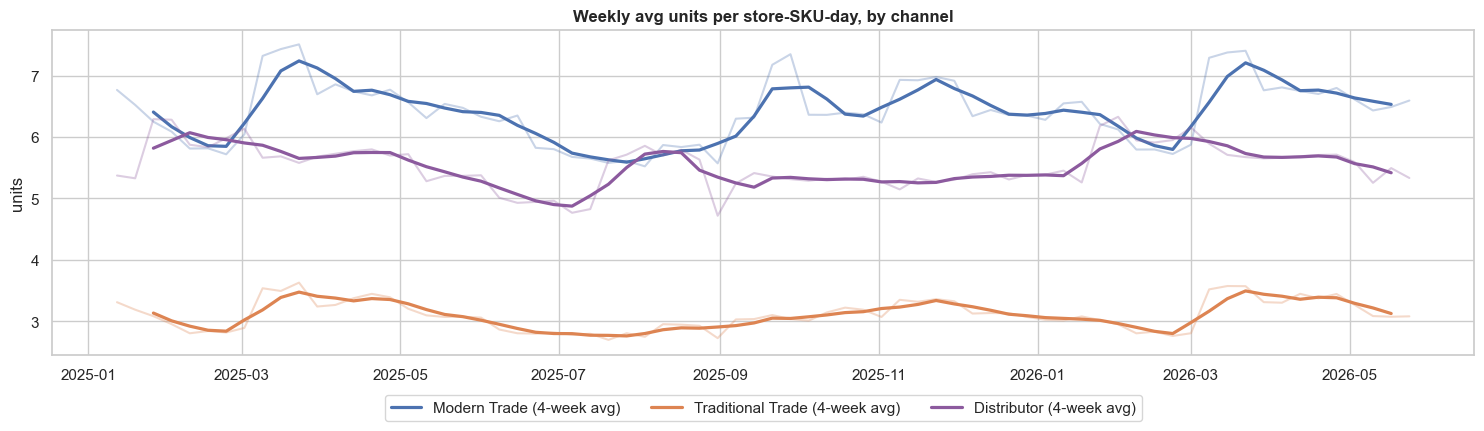

In [30]:
wk = sof.groupby([pd.Grouper(key='date', freq='W'), 'channel']).units_sold_daily.mean().unstack()[CH_ORDER].iloc[1:-1]
fig, ax = plt.subplots(figsize=(15, 4.5))
for ch in CH_ORDER:
    ax.plot(wk.index, wk[ch], color=CH_COL[ch], alpha=0.3)
    ax.plot(wk.index, wk[ch].rolling(4, center=True).mean(), color=CH_COL[ch], lw=2.3, label=f'{ch} (4-week avg)')
ax.set_title('Weekly avg units per store-SKU-day, by channel'); ax.set_ylabel('units')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
show('06_weekly_trend')

**Notes:** Still no long-term growth: 2026 repeats 2025. Compared to v1 the lines are bumpier. Modern Trade jumps in **March** and again in **September–November**, lining up with the Spring Clean Blitz, the Fall Cleaning Event and the Holiday Bundle. Distributors get bumps in **February** and **July–August**, their volume deals. So the promotions are now visible in the overall trend.

### 6.2 Monthly seasonality by category
New problem in v2: promotions are timed with the seasons (e.g. "Spring Clean Blitz" in March), so a seasonal peak could partly be promo lift. To separate the two we computed the index twice: on all days, and on **non-promo days only**. Because promos cover whole channels, the non-promo days in a promo month come from other channels, so we first divide each store-SKU's sales by its own average (otherwise the mix of channels would distort the index).

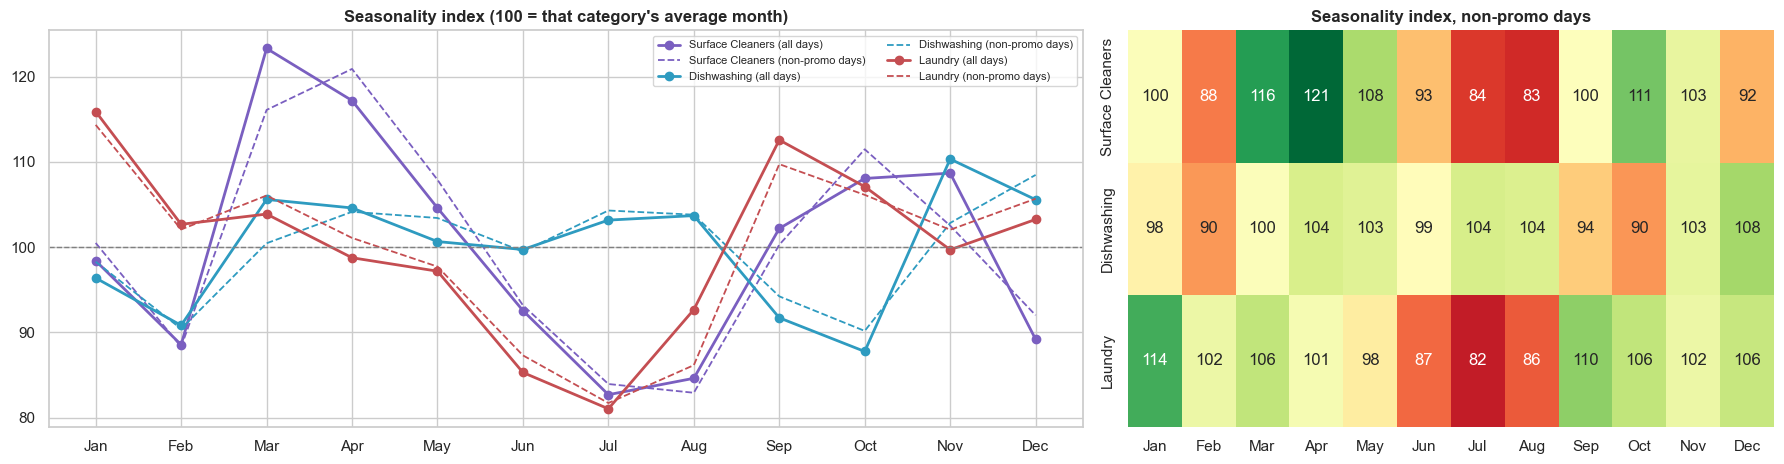

In [31]:
sof['rel_units'] = sof.units_sold_daily / sof.groupby(['store_id', 'sku_id']).units_sold_daily.transform('mean')
def season_index(frame):
    m = frame.groupby([frame.date.dt.month, 'category']).rel_units.mean().unstack()[CAT_ORDER]
    return m / m.mean() * 100
cat_index, cat_index_np = season_index(sof), season_index(sof[~sof.on_promo])
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
for c in CAT_ORDER:
    axes[0].plot(range(1, 13), cat_index[c], marker='o', color=CAT_COL[c], label=f'{c} (all days)', lw=2)
    axes[0].plot(range(1, 13), cat_index_np[c], ls='--', color=CAT_COL[c], lw=1.3, label=f'{c} (non-promo days)')
axes[0].axhline(100, color='grey', ls='--', lw=1)
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(MONTHS)
axes[0].set_title("Seasonality index (100 = that category's average month)"); axes[0].legend(fontsize=8, ncol=2)
heatmap(cat_index_np.T.set_axis(MONTHS, axis=1), annot=True, fmt='.0f', cmap='RdYlGn', center=100, ax=axes[1], cbar=False)
axes[1].set_title('Seasonality index, non-promo days'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
show('06_seasonality')

**Notes:** The v1 seasonality is still there, and it's mostly *not* promo-driven (the dashed non-promo lines stay close to the solid ones):
1. **Surface Cleaners** peak in March–April (116–121 on non-promo days) and dip in July–August (~83). The Spring Clean Blitz adds a few points on top in March (123 on all days vs 116 without promos).
2. **Laundry** is high in January (114) and September (110), and lowest in July (82).
3. **Dishwashing** is the steadiest (90–108), with a high in December. The Holiday Bundle adds about 7 points in November (110 vs 103).

So for the perfect order we need **both** a month factor and a promo factor.

### 6.3 Seasonal decomposition (daily)

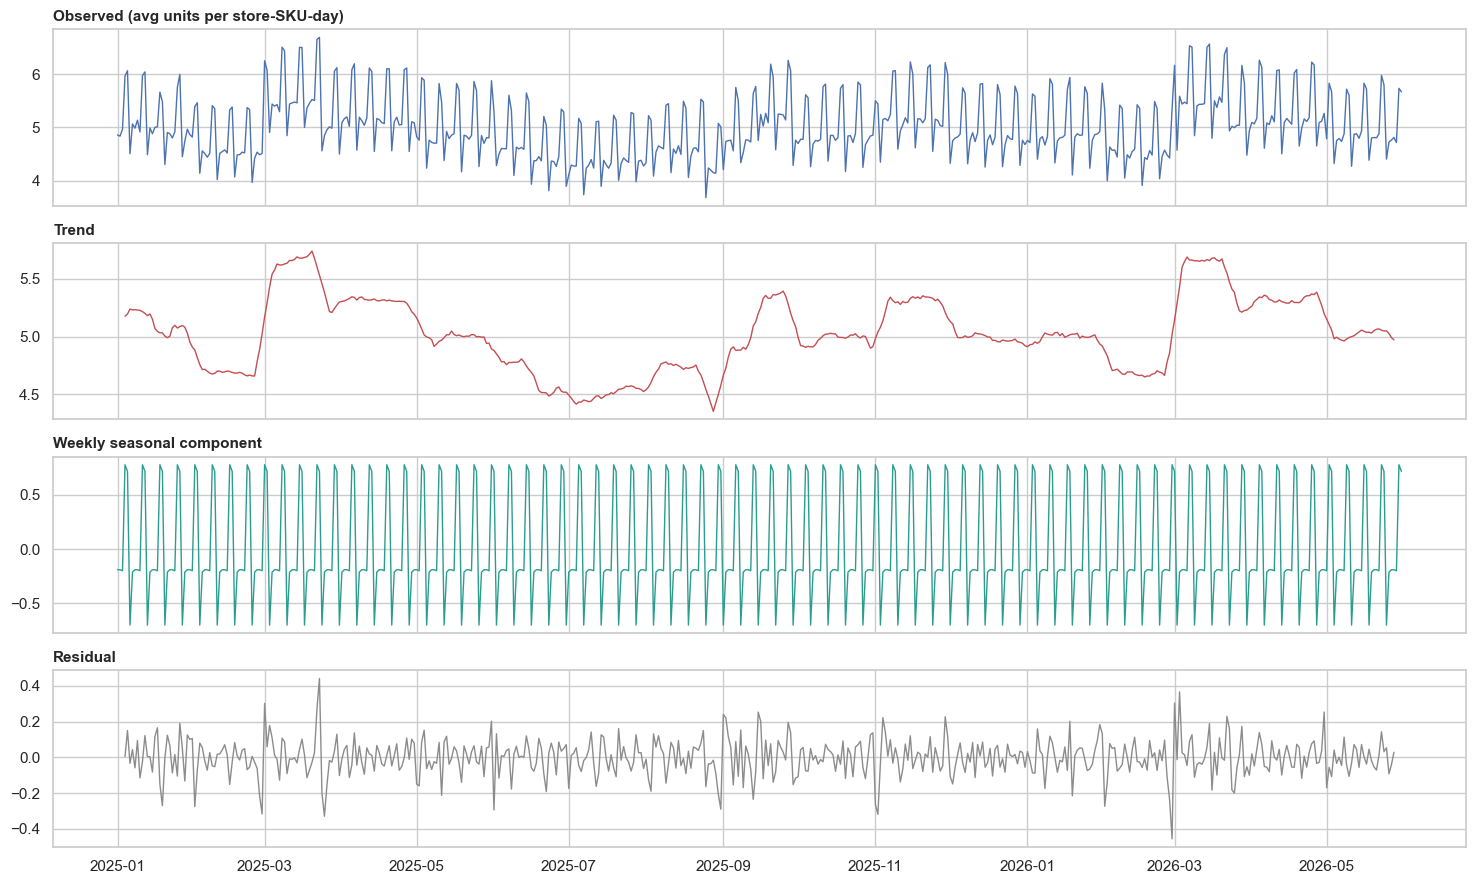

Avg day-to-day change (weekday-adjusted): on the 1st of a month 0.35 units | on all other days 0.09 units   (v1 found jumps on the 1st)


In [32]:
daily = sof.groupby('date').units_sold_daily.mean().asfreq('D')
dec = seasonal_decompose(daily, model='additive', period=7)
fig, axes = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
for ax, series, title, color in zip(axes, [dec.observed, dec.trend, dec.seasonal, dec.resid],
                                    ['Observed (avg units per store-SKU-day)', 'Trend', 'Weekly seasonal component', 'Residual'],
                                    ['#4C72B0', '#C44E52', '#2A9D8F', '#8C8C8C']):
    ax.plot(series.index, series.values, color=color, lw=1)
    ax.set_title(title, fontsize=11, loc='left')
show('06_decomposition')
step = (dec.observed - dec.seasonal).diff().abs()      # day-to-day change after removing the weekday effect
print(f"Avg day-to-day change (weekday-adjusted): on the 1st of a month {step[step.index.day == 1].mean():.2f} units "
      f"| on all other days {step[step.index.day != 1].mean():.2f} units   (v1 found jumps on the 1st)")

**Notes:** Same as v1: the trend has the yearly wave, the weekly pattern is clean, and the residual is small. The trend still moves in **steps on the 1st of each month**: the weekday-adjusted daily average changes by 0.35 units on the 1st vs 0.09 on other days. So the simulation still uses one multiplier per month, and a month factor plus a weekday factor should capture most of the seasonality.

### 6.4 Day-of-week effect

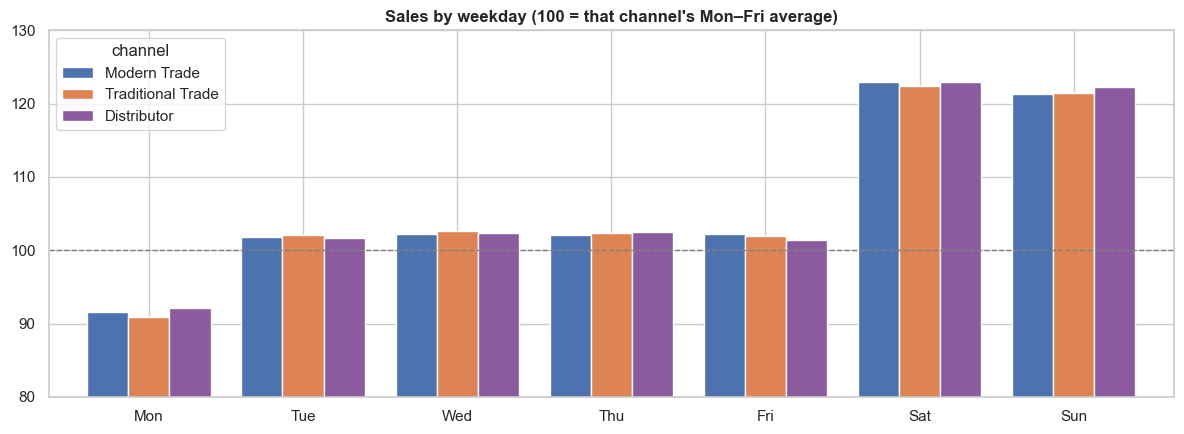

Weekend vs weekday: +22%   (v1: +23%)


In [33]:
dow_ch = sof.groupby(['channel', sof.date.dt.dayofweek]).units_sold_daily.mean().unstack(0)[CH_ORDER]
dow_idx = dow_ch / dow_ch.iloc[:5].mean() * 100
fig, ax = plt.subplots(figsize=(12, 4.5))
dow_idx.set_axis(DAYS).plot.bar(ax=ax, color=[CH_COL[c] for c in CH_ORDER], rot=0, width=0.8)
ax.axhline(100, color='grey', ls='--', lw=1); ax.set_ylim(80, 130)
ax.set_title("Sales by weekday (100 = that channel's Mon–Fri average)"); ax.set_xlabel('')
show('06_weekday')
dow_all = sof.groupby(sof.date.dt.dayofweek).units_sold_daily.mean()
print(f"Weekend vs weekday: {dow_all[[5, 6]].mean() / dow_all[:5].mean() - 1:+.0%}   (v1: +23%)")

**Notes:** Weekends still sell about **22% more** than weekdays (v1: +23%), in every channel, and Monday is still the slowest day.

### 6.5 Year-over-year (Jan–May 2025 vs 2026)

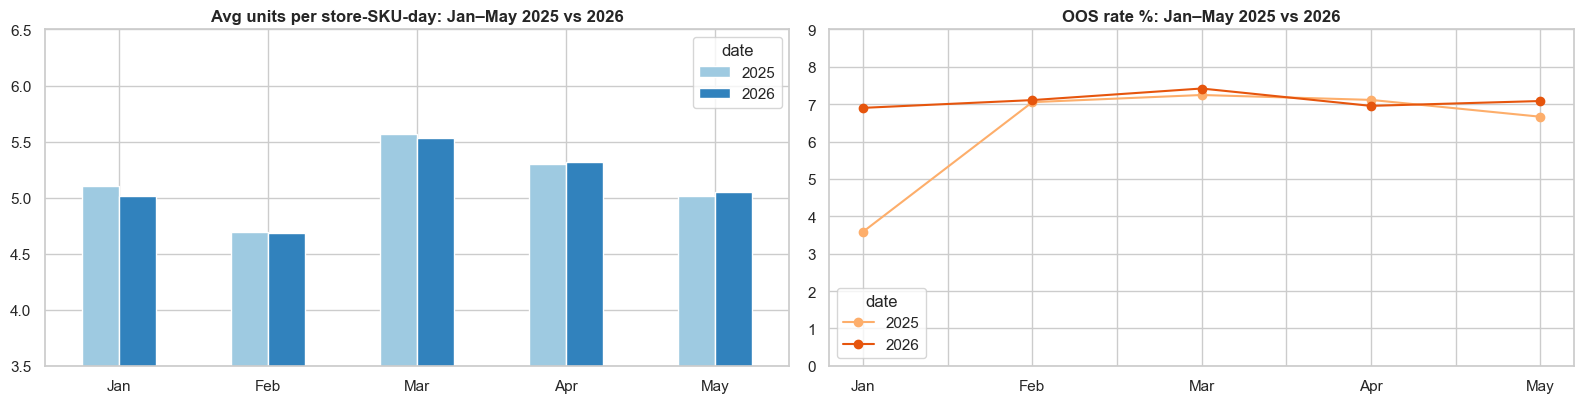

units         oos      
date  2025  2026  2025  2026
date                        
1     5.10  5.02  3.59  6.90
2     4.69  4.68  7.05  7.11
3     5.57  5.53  7.25  7.42
4     5.30  5.32  7.11  6.96
5     5.02  5.05  6.67  7.08

In [34]:
h1 = sof[sof.date.dt.month <= 5]
yoy = h1.groupby([h1.date.dt.month, h1.date.dt.year]).agg(units=('units_sold_daily', 'mean'), oos=('is_out_of_stock', 'mean')).unstack()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
yoy['units'].set_axis(MONTHS[:5]).plot.bar(ax=axes[0], rot=0, color=['#9ecae1', '#3182bd'])
axes[0].set_title('Avg units per store-SKU-day: Jan–May 2025 vs 2026'); axes[0].set_xlabel(''); axes[0].set_ylim(3.5, 6.5)
(yoy['oos'] * 100).set_axis(MONTHS[:5]).plot(ax=axes[1], marker='o', color=['#fdae6b', '#e6550d'])
axes[1].set_title('OOS rate %: Jan–May 2025 vs 2026'); axes[1].set_ylim(0, 9); axes[1].set_xlabel('')
show('06_yoy')
display((yoy * [1, 1, 100, 100]).round(2))

**Notes:** The two years are again almost identical month by month, so there's no growth built in. **January 2025 is still a warm-up month**: OOS is 3.6% vs 6.9% in January 2026. We keep dropping it when training the model.

## 7. The brief's KPIs (baseline values)
In v1 we had to invent our own KPI definitions and asked Dr. Masse to confirm them. He answered (Q10, Q13, Q15, Q17), so this section uses the **official** definitions.

### 7.1 Definitions we used (from the Q&A)

| KPI | Official definition (Q10) | How we computed it |
|---|---|---|
| OOS rate % | OOS store-SKU-days ÷ all store-SKU-days | reported days only (missing days are random, so this is unbiased) |
| MSL compliance % | stores where **every** MSL SKU has stock > 0 ÷ stores | per store-day, then averaged over days |
| Sell-in vs sell-out gap % | (sell-in units − sell-out units) ÷ sell-out units | both over the **same window** (Q13); we use whole invoice weeks |
| Shelf share % | average `shelf_share_pct` | audits |
| Planogram compliance % | compliant audit rows ÷ audit rows | audits (a different thing from MSL, Q15) |

Distributors are wholesale accounts (Q17), so we show them on their own row and also give a **Retail (MT + TT)** total.

### 7.2 KPI scorecard

In [35]:
msl_ids = set(products.loc[products.is_msl, 'sku_id'])
def msl_store_days(frame):
    m = frame[frame.sku_id.isin(msl_ids)].groupby(['store_id', 'date']).inventory_level.min().gt(0)
    return m.rename('msl_compliant').reset_index().merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
msl_sd = msl_store_days(sof)

def kpi_table(key, S, I, A, M):
    return pd.DataFrame({
        'OOS rate %': S.groupby(key(S)).is_out_of_stock.mean() * 100,
        'MSL compliance %': M.groupby(key(M)).msl_compliant.mean() * 100,
        'Sell-in vs sell-out gap %': (I.groupby(key(I)).units_sold.sum() / S.groupby(key(S)).units_sold_daily.sum() - 1) * 100,
        'Shelf share %': A.groupby(key(A)).shelf_share_pct.mean(),
        'Planogram compliance %': A.groupby(key(A)).planogram_compliance.mean() * 100})

def scorecard(S, I, A, M):
    retail = lambda d: d[d.channel != 'Distributor']
    return pd.concat([kpi_table(lambda d: d.channel, S, I, A, M).reindex(CH_ORDER),
                      kpi_table(lambda d: np.repeat('Retail (MT + TT)', len(d)), *(retail(d) for d in (S, I, A, M))),
                      kpi_table(lambda d: np.repeat('All accounts', len(d)), S, I, A, M)])

score_v2 = scorecard(sof, si, au, msl_sd)
display(score_v2.round(1))

# the same scorecard on the v1 data, to see what moved
so1 = v1['fact_sell_out'].assign(channel=lambda d: d.store_id.map(ch_of))
si1 = v1['fact_sell_in'].assign(channel=lambda d: d.store_id.map(ch_of))
score_v1 = scorecard(so1, si1, au, msl_store_days(so1))
compare = pd.concat({'v1': score_v1.loc[['Retail (MT + TT)', 'All accounts']], 'v2': score_v2.loc[['Retail (MT + TT)', 'All accounts']]})
display(compare.round(1))
del so1, si1

,OOS rate %,MSL compliance %,Sell-in vs sell-out gap %,Shelf share %,Planogram compliance %
Modern Trade,3.6,64.3,11.3,38.8,88.8
Traditional Trade,12.6,28.2,-44.8,30.5,75.7
Distributor,2.7,70.2,11.1,33.8,80.7
Retail (MT + TT),7.7,47.7,-4.6,35.5,83.6
All accounts,6.8,51.4,-1.7,35.2,83.1


OOS rate %  MSL compliance %  Sell-in vs sell-out gap %  Shelf share %  Planogram compliance %
v1 Retail (MT + TT)         6.0              39.7                       -6.0           35.5                    83.6
   All accounts             6.0              40.0                       -3.2           35.2                    83.1
v2 Retail (MT + TT)         7.7              47.7                       -4.6           35.5                    83.6
   All accounts             6.8              51.4                       -1.7           35.2                    83.1

**Notes**
1. **OOS rate** is now very different by channel: **3.6% Modern Trade, 12.6% Traditional Trade, 2.7% Distributors** (v1: ~6% everywhere). Overall it rose from 6.0% to 6.8%.
2. **MSL compliance went up** (40% → 51%), even though OOS went up. That makes sense once OOS is concentrated: when stock-outs pile up in a few small stores, more of the other stores have all their MSL SKUs in stock on the same day. Traditional Trade is the problem, at 28%.
3. **Sell-in gap:** +11% for Modern Trade and Distributors and **−45% for Traditional Trade**, the same pattern as v1. Overall it's −1.7%, but that average hides two opposite stories, so the dashboard should never show only the total.
4. **Shelf share** and **planogram** are identical to v1, because the audits didn't change.

### 7.3 KPI trends over time
In v1 the monthly sell-in gap swung between −13% and +13% just because some months have five Mondays (invoice days). Following Q13, here we bucket **both** sell-in and sell-out by invoice week (Monday to Sunday) and assign each week to the month it starts in, so every month compares the same days.

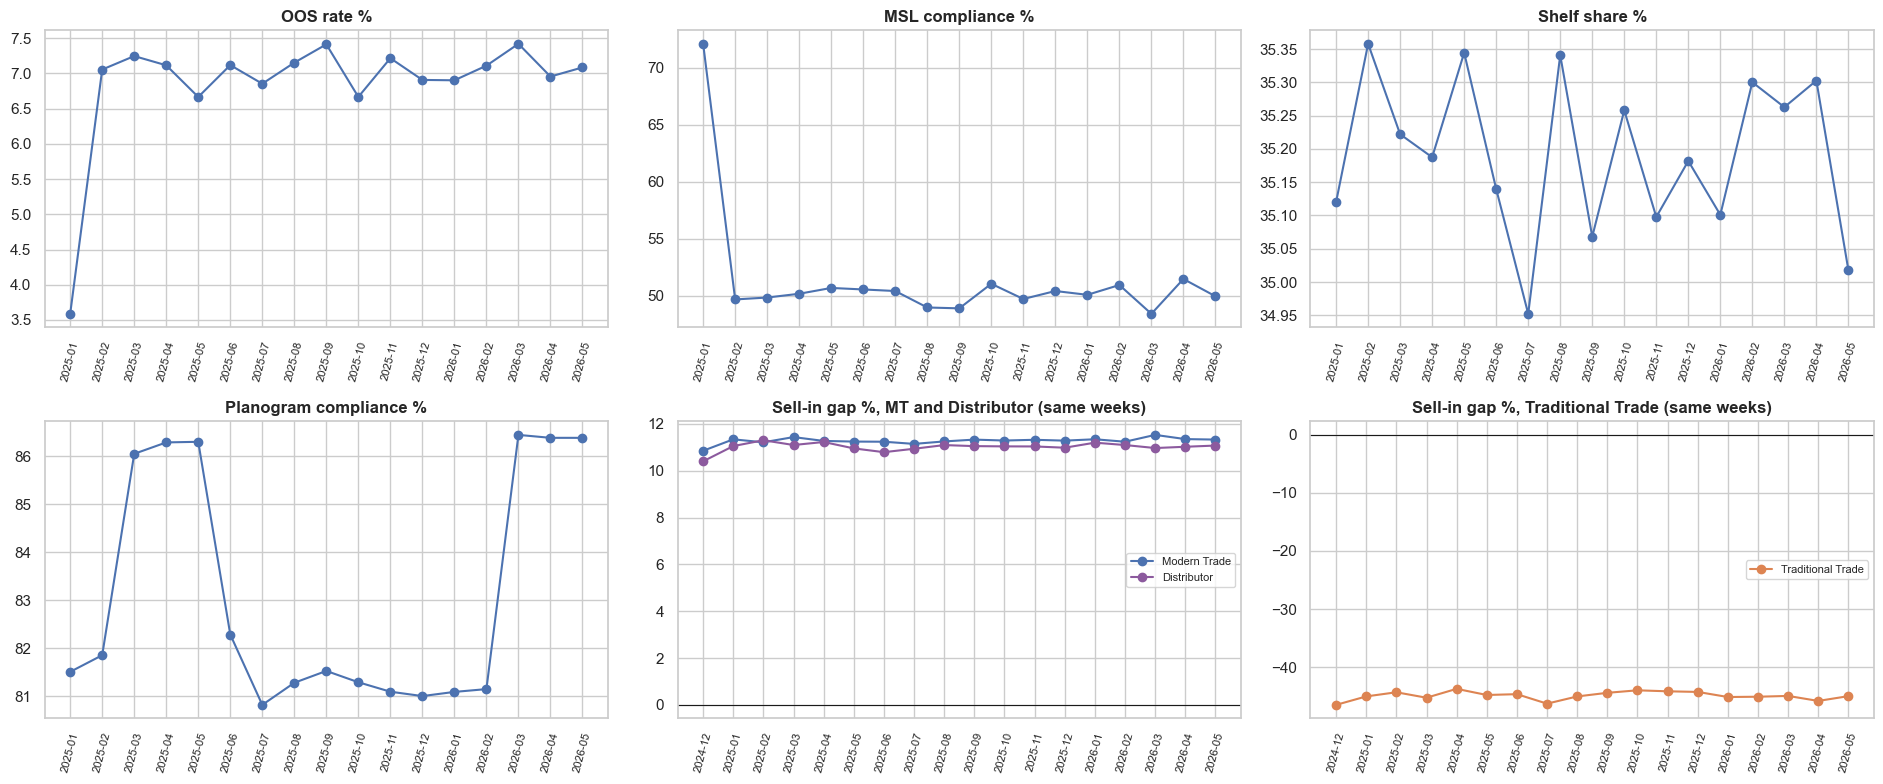

channel,Modern Trade,Traditional Trade,Distributor
mean,11.3,-44.9,11.0
min,10.9,-46.5,10.4
max,11.5,-43.7,11.3


In [36]:
month = lambda d: d.date.dt.to_period('M')
sof['week'] = sof.date - pd.to_timedelta(sof.date.dt.dayofweek, unit='D')     # the Monday that opens the week
wk_out = sof.groupby(['channel', 'week']).units_sold_daily.sum()
wk_in = si.groupby(['channel', 'date']).units_sold.sum().rename_axis(['channel', 'week'])
wk_both = pd.concat([wk_out.rename('sell_out'), wk_in.rename('sell_in')], axis=1).fillna(0).reset_index()
wk_both['month'] = wk_both.week.dt.to_period('M')
gap_m = wk_both.groupby(['month', 'channel'])[['sell_in', 'sell_out']].sum()
gap_m = (gap_m.sell_in / gap_m.sell_out - 1).unstack()[CH_ORDER] * 100

monthly = pd.DataFrame({
    'OOS rate %': sof.groupby(month(sof)).is_out_of_stock.mean() * 100,
    'MSL compliance %': msl_sd.groupby(month(msl_sd)).msl_compliant.mean() * 100,
    'Shelf share %': au.groupby(month(au)).shelf_share_pct.mean(),
    'Planogram compliance %': au.groupby(month(au)).planogram_compliance.mean() * 100}).dropna()

fig, axes = plt.subplots(2, 3, figsize=(19, 8))
for ax, col in zip(axes.flat, ['OOS rate %', 'MSL compliance %', 'Shelf share %', 'Planogram compliance %']):
    ax.plot(monthly.index.astype(str), monthly[col], marker='o', color='#4C72B0')
    ax.set_title(col); ax.tick_params(axis='x', rotation=75, labelsize=8)
for ax, chs, title in [(axes[1, 1], ['Modern Trade', 'Distributor'], 'Sell-in gap %, MT and Distributor (same weeks)'),
                       (axes[1, 2], ['Traditional Trade'], 'Sell-in gap %, Traditional Trade (same weeks)')]:
    for ch in chs:
        ax.plot(gap_m.index.astype(str), gap_m[ch], marker='o', color=CH_COL[ch], label=ch)
    ax.axhline(0, color='k', lw=0.8); ax.set_title(title); ax.tick_params(axis='x', rotation=75, labelsize=8); ax.legend(fontsize=8)
show('07_kpi_trends')
display(gap_m.describe().loc[['mean', 'min', 'max']].round(1))

**Notes**
1. OOS (~7%) and MSL compliance (~50%) are flat apart from the January 2025 warm-up spike, and shelf share barely moves (35.0–35.4%). Planogram has the same spring bump as in v1 (it's the same audit file).
2. With both sides bucketed into the same invoice weeks, the monthly sell-in gap is **stable**: Modern Trade +10.9% to +11.5%, Distributors +10.4% to +11.3%, Traditional Trade −46.5% to −43.7%. The v1 swings (−13% to +13%) really were the 5-Monday effect, and this fixes them.
3. But even with matched windows, **Traditional Trade stays around −45%**. Q13 expected this gap to shrink once the windows match, and it doesn't. We dig into why in 8.3.

### 7.4 KPIs by region and channel

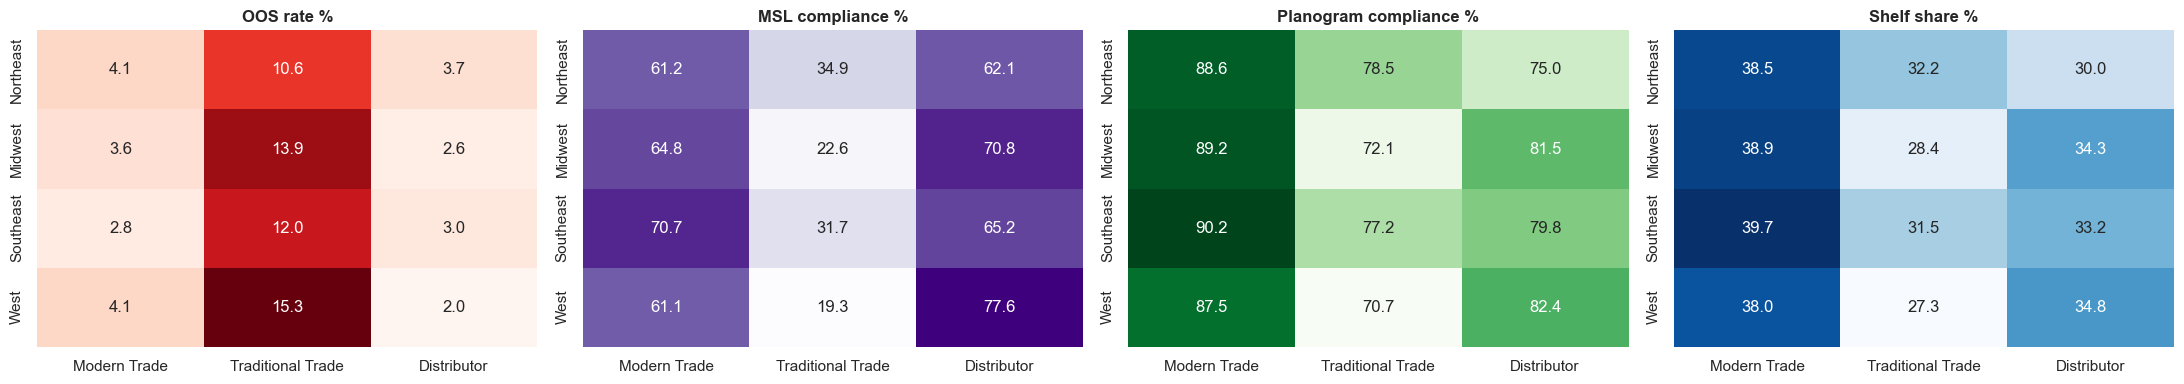

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, (title, frame, col, mult, cmap) in zip(axes, [
        ('OOS rate %', sof, 'is_out_of_stock', 100, 'Reds'),
        ('MSL compliance %', msl_sd, 'msl_compliant', 100, 'Purples'),
        ('Planogram compliance %', au, 'planogram_compliance', 100, 'Greens'),
        ('Shelf share %', au, 'shelf_share_pct', 1, 'Blues')]):
    hm = frame.pivot_table(index='region', columns='channel', values=col, aggfunc='mean').reindex(REGION_ORDER)[CH_ORDER] * mult
    heatmap(hm, annot=True, fmt='.1f', cmap=cmap, ax=ax, cbar=False)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')
show('07_kpis_region_channel')

**Notes:** Region still makes little difference; the channel does. Traditional Trade is the weakest cell in every region and on every KPI, especially in the **West** (OOS 15.3%, MSL compliance only 19.3%, shelf share 27.3%) and the **Midwest**. Modern Trade is consistently good everywhere.

### 7.5 Checking the client's numbers: the "62%" and Q7
In v1 we couldn't reproduce the brief's 62%. In Q7 Dr. Masse gave more detail: Traditional Trade Tier 3 is ~45% planogram-compliant, Traditional Trade Tier 2 ~65%, Modern Trade Tier 1 85–90%. The audits didn't change, but now we know *which* numbers to look for:

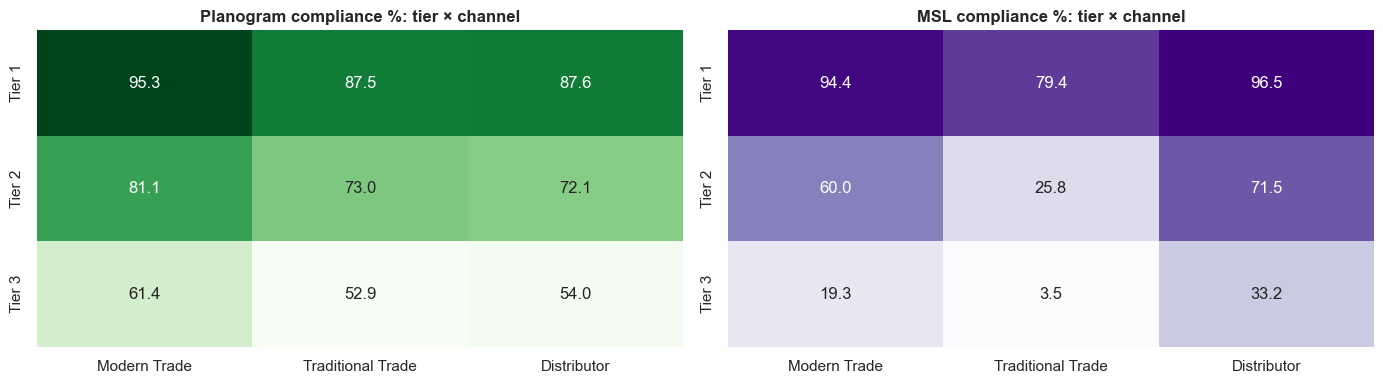

,client says (Q7),audits show
"Traditional Trade, Tier 3",~45%,52.9
"Traditional Trade, Tier 2",~65%,73.0
"Modern Trade, Tier 1",85–90%,95.3


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plano = au.pivot_table(index='segment_tier', columns='channel', values='planogram_compliance', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER] * 100
heatmap(plano, annot=True, fmt='.1f', cmap='Greens', ax=axes[0], cbar=False); axes[0].set_title('Planogram compliance %: tier × channel'); axes[0].set_xlabel(''); axes[0].set_ylabel('')
msl_tc = msl_sd.pivot_table(index='segment_tier', columns='channel', values='msl_compliant', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER] * 100
heatmap(msl_tc, annot=True, fmt='.1f', cmap='Purples', ax=axes[1], cbar=False); axes[1].set_title('MSL compliance %: tier × channel'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
show('07_q7_check')
q7 = pd.DataFrame({'client says (Q7)': ['~45%', '~65%', '85–90%'],
                   'audits show': [plano.loc['Tier 3', 'Traditional Trade'], plano.loc['Tier 2', 'Traditional Trade'], plano.loc['Tier 1', 'Modern Trade']]},
                  index=['Traditional Trade, Tier 3', 'Traditional Trade, Tier 2', 'Modern Trade, Tier 1'])
q7.round(1)

**Notes:** The client's story is right in direction (Traditional Trade Tier 3 is the weakest, Modern Trade Tier 1 the strongest), but the audits show **higher** numbers than Q7 for all three groups: 52.9% vs ~45%, 73.0% vs ~65%, and 95.3% vs 85–90%. The audits didn't change, so the Q7 figures must come from somewhere else (maybe another definition, or the real business). We still can't reproduce the 62% either (overall planogram compliance is 83.1%, MSL compliance 51.4%).

The MSL heatmap is the most striking chart in this section: **Traditional Trade Tier 3 stores have all their MSL SKUs in stock on only 3.5% of days.** That's where the field reps need to go first.

## 8. Deep dives

### 8.1 Out-of-stocks
OOS is still problem number one in the brief, and it's the table that changed the most.

Overall OOS rate: 6.85% of store-SKU-days   (v1: 5.98%)


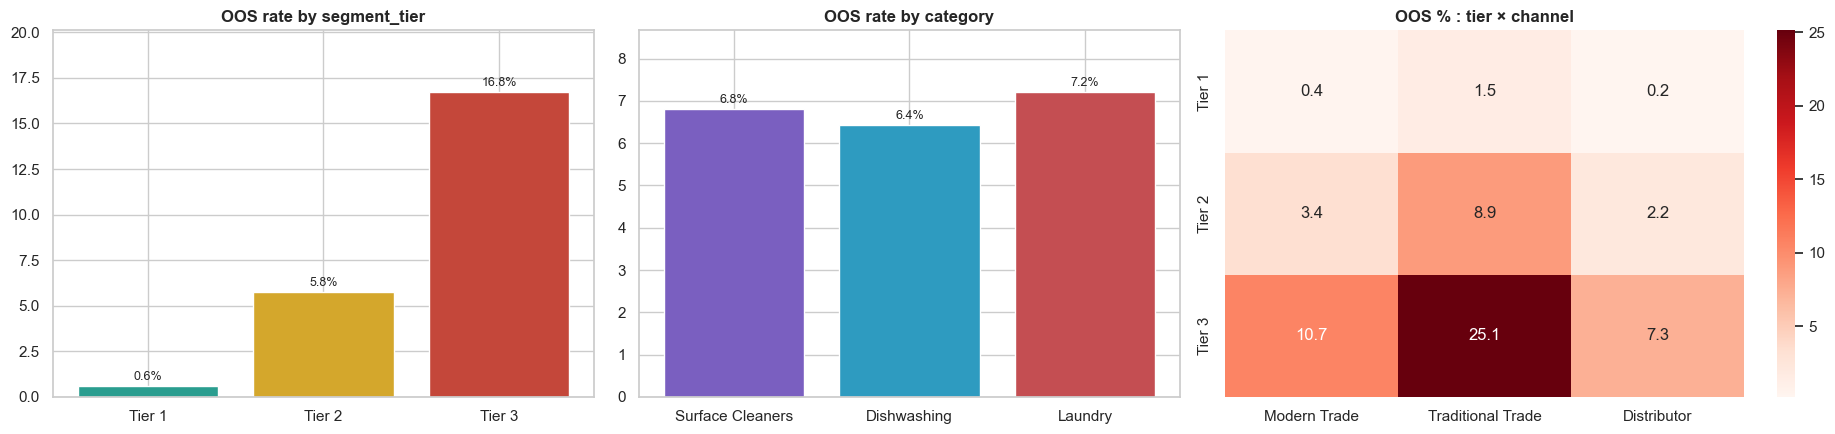

In [39]:
print(f"Overall OOS rate: {sof.is_out_of_stock.mean():.2%} of store-SKU-days   (v1: {v1['fact_sell_out'].is_out_of_stock.mean():.2%})")
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.2]})
for ax, col, order, pal in [(axes[0], 'segment_tier', TIER_ORDER, TIER_COL), (axes[1], 'category', CAT_ORDER, CAT_COL)]:
    r = sof.groupby(col).is_out_of_stock.mean().reindex(order) * 100
    ax.bar(r.index, r.values, color=[pal[x] for x in r.index]); label_bars(ax, '{:.1f}%')
    ax.set_title(f'OOS rate by {col}'); ax.set_ylim(0, r.max() * 1.2)
hm = sof.pivot_table(index='segment_tier', columns='channel', values='is_out_of_stock', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER] * 100
heatmap(hm, annot=True, fmt='.1f', cmap='Reds', ax=axes[2]); axes[2].set_title('OOS % : tier × channel'); axes[2].set_xlabel(''); axes[2].set_ylabel('')
show('08_oos_by_dimension')

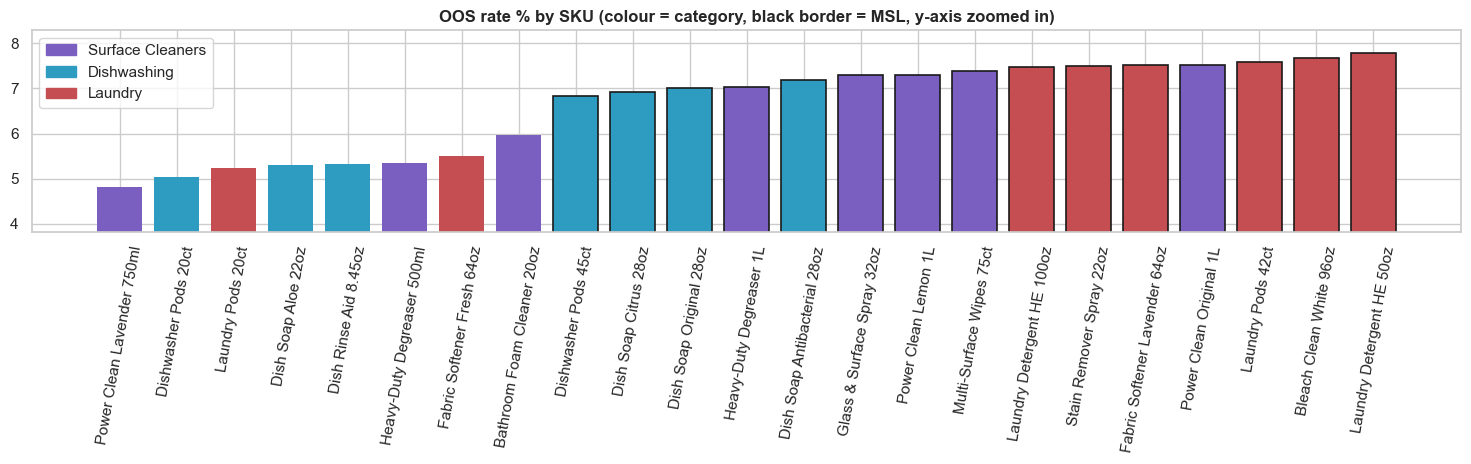

In [40]:
by_sku = (sof.groupby(['sku_id', 'product_name', 'category', 'is_msl']).is_out_of_stock.mean() * 100).reset_index().sort_values('is_out_of_stock')
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.bar(by_sku.product_name.str.replace('Marvel ', ''), by_sku.is_out_of_stock, color=[CAT_COL[c] for c in by_sku.category],
       edgecolor=['k' if m else 'none' for m in by_sku.is_msl], linewidth=1.2)
ax.set_ylim(by_sku.is_out_of_stock.min() - 1, by_sku.is_out_of_stock.max() + 0.5); ax.tick_params(axis='x', rotation=80)
ax.set_title('OOS rate % by SKU (colour = category, black border = MSL, y-axis zoomed in)')
ax.legend(handles=[Patch(color=CAT_COL[c], label=c) for c in CAT_ORDER], loc='upper left')
show('08_oos_by_sku')

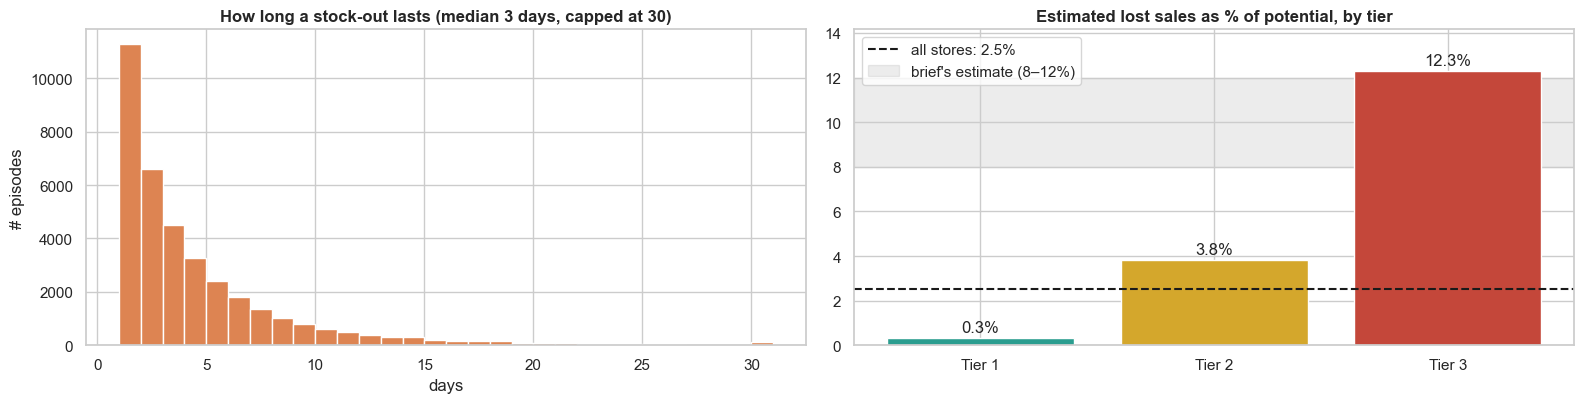

36,565 OOS episodes | 90% last 9 days or less | estimated lost sales $1,292,943 at list price


In [41]:
is_oos = so.is_out_of_stock
new_episode = is_oos & ~so.groupby(['store_id', 'sku_id']).is_out_of_stock.shift(fill_value=False)
so['episode'] = new_episode.groupby([so.store_id, so.sku_id]).cumsum()
ep = so[is_oos].groupby(['store_id', 'sku_id', 'episode']).date.agg(['min', 'max'])
ep_len = (ep['max'] - ep['min']).dt.days + 1

# rough lost sales (same method as v1): on OOS days, assume the store would have sold its normal in-stock daily average.
# valued at list price, like the brief's "units at risk × list price"
normal_daily = so[~so.is_out_of_stock].groupby(['store_id', 'sku_id']).units_sold_daily.mean().rename('normal_daily')
ls = sof[['store_id', 'sku_id', 'is_out_of_stock', 'units_sold_daily', 'list_price', 'segment_tier']].merge(normal_daily, on=['store_id', 'sku_id'])
ls['lost_value'] = np.where(ls.is_out_of_stock, (ls.normal_daily - ls.units_sold_daily).clip(lower=0), 0) * ls.list_price
ls['actual_value'] = ls.units_sold_daily * ls.list_price
lost_tier = ls.groupby('segment_tier')[['lost_value', 'actual_value']].sum().reindex(TIER_ORDER)
lost_pct = lost_tier.lost_value / (lost_tier.lost_value + lost_tier.actual_value) * 100
total_lost = ls.lost_value.sum() / (ls.lost_value.sum() + ls.actual_value.sum())

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
axes[0].hist(ep_len.clip(upper=30), bins=range(1, 32), color='#DD8452')
axes[0].set_title(f'How long a stock-out lasts (median {ep_len.median():.0f} days, capped at 30)'); axes[0].set_xlabel('days'); axes[0].set_ylabel('# episodes')
bars = axes[1].bar(lost_pct.index, lost_pct.values, color=[TIER_COL[t] for t in lost_pct.index])
axes[1].bar_label(bars, labels=[f'{v:.1f}%' for v in lost_pct.values], padding=2)
axes[1].axhline(total_lost * 100, color='k', ls='--', label=f'all stores: {total_lost:.1%}')
axes[1].axhspan(8, 12, color='grey', alpha=0.15, label="brief's estimate (8–12%)", zorder=0)
axes[1].set_title('Estimated lost sales as % of potential, by tier'); axes[1].legend(loc='upper left'); axes[1].set_ylim(0, max(13, lost_pct.max() * 1.15))
show('08_oos_duration_lost_sales')
print(f"{len(ep_len):,} OOS episodes | 90% last {ep_len.quantile(.9):.0f} days or less | estimated lost sales ${ls.lost_value.sum():,.0f} at list price")
del ls; _ = gc.collect()

**What we found**
1. OOS is **6.85%** of store-SKU-days (v1: 5.98%), but it's no longer flat. **Tier drives almost everything**: Tier 1 is out of stock only **0.6%** of the time, Tier 2 **5.8%** and Tier 3 **16.8%**. Traditional Trade Tier 3 is at **25.1%**, so a quarter of the time a given SKU is missing from those shelves.
2. Category barely matters, and the range by SKU is still narrow (~4.8% to ~7.8%). MSL SKUs look worse than optional ones, but only because Tier 3 stores carry fewer optional SKUs; within each tier, MSL and optional SKUs run out equally often.
3. A stock-out still usually lasts **about 3 days**, and 90% are over within 9 days.
4. Lost sales with the same simple method as v1 come to **2.5% of potential** overall (v1: ~4–5%), about $1.29M at list price. By tier it's 0.3% for Tier 1, 3.8% for Tier 2 and **12.3% for Tier 3**. So the brief's "8–12%" now describes the small stores, not Marvel as a whole.

### 8.2 Stock and replenishment
Same example as v1 (STR-0001, a Modern Trade Tier 3 store, and Power Clean Lemon 1L), so the two versions can be compared side by side. New: the purple triangles are the deliveries recorded in `fact_deliveries` for the same store and SKU.

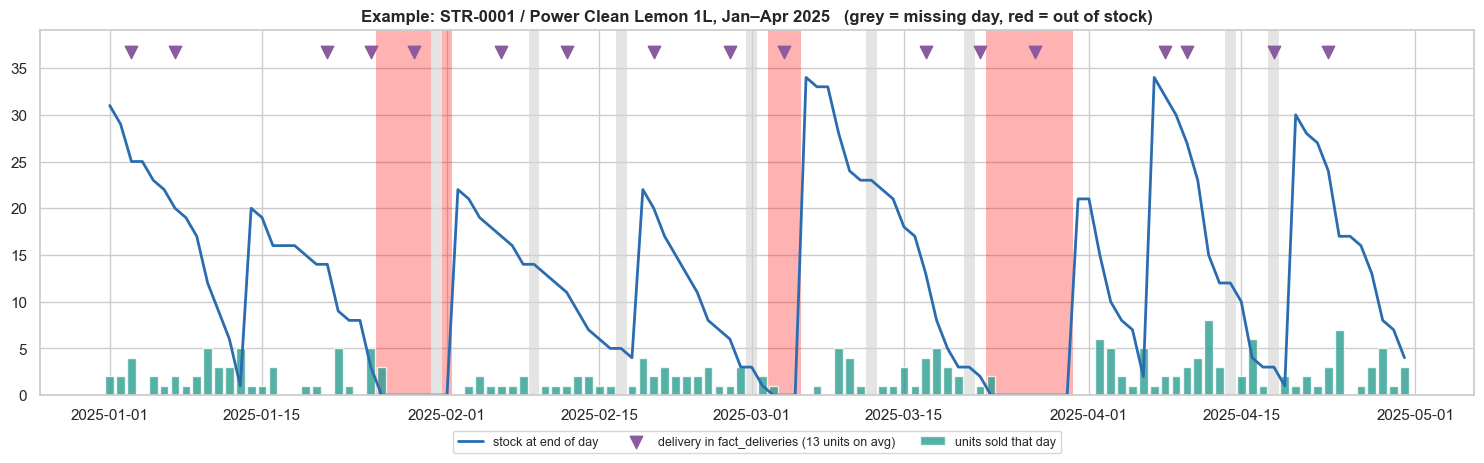

In [42]:
ex = so[(so.store_id == 'STR-0001') & (so.sku_id == 'SKU-1001') & (so.date < '2025-05-01')]
full = ex.set_index('date').reindex(pd.date_range('2025-01-01', '2025-04-30'))
d_ex = deliveries[(deliveries.store_id == 'STR-0001') & (deliveries.sku_id == 'SKU-1001') & (deliveries.actual_delivery <= '2025-04-30')]
half = pd.Timedelta(hours=12)
fig, ax = plt.subplots(figsize=(15, 4.8))
for d in full.index[full.inventory_level.isna()]:
    ax.axvspan(d - half, d + half, color='lightgrey', alpha=0.6, lw=0)
for d in ex.date[ex.is_out_of_stock]:
    ax.axvspan(d - half, d + half, color='red', alpha=0.3, lw=0)
ax.plot(full.index, full.inventory_level.ffill(), color='#2b6cb0', lw=2, label='stock at end of day')
ax.bar(ex.date, ex.units_sold_daily, color='#2A9D8F', alpha=0.8, label='units sold that day')
top = full.inventory_level.max() * 1.15
ax.scatter(d_ex.actual_delivery, np.full(len(d_ex), top * 0.94), marker='v', s=80, color='#8C5A9E', zorder=5,
           label=f'delivery in fact_deliveries ({d_ex.units_delivered.mean():.0f} units on avg)')
ax.set_title('Example: STR-0001 / Power Clean Lemon 1L, Jan–Apr 2025   (grey = missing day, red = out of stock)')
ax.set_ylim(0, top); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=9)
show('08_example_timeline')

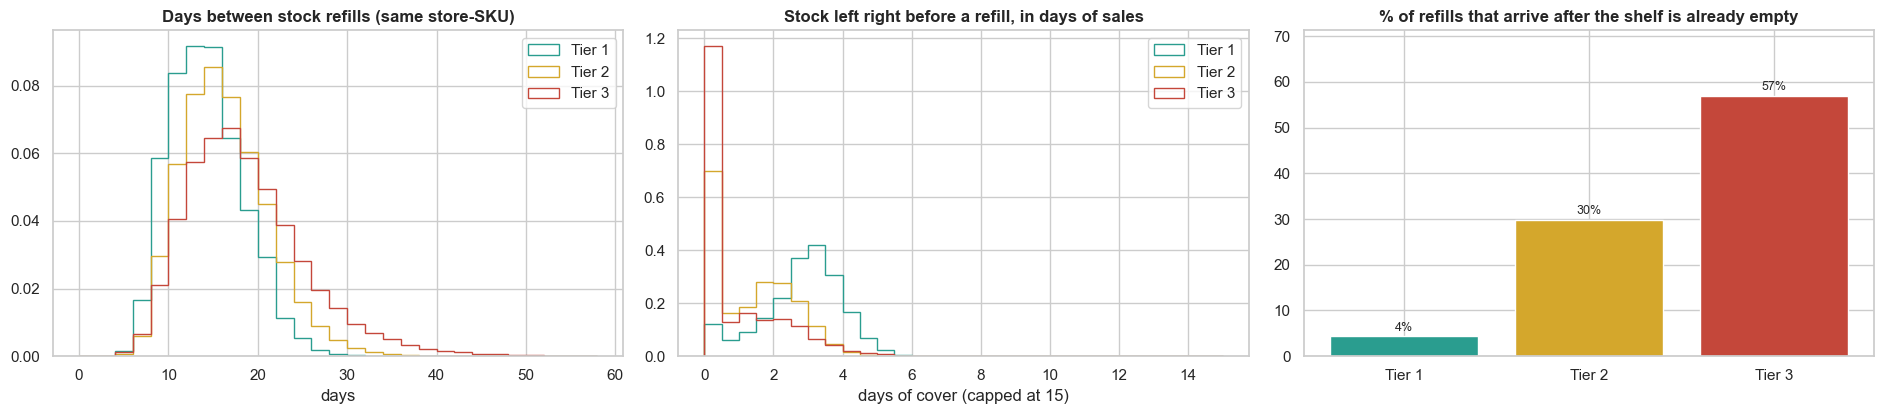

,refills,median_days_between,median_cover_before,median_cover_after,avg_units_per_day,median_refill_units
tier,,,,,,
Tier 1,56525,13.0,3.0,15.2,8.7,104.0
Tier 2,52717,15.0,1.4,15.6,4.1,57.0
Tier 3,31632,17.0,0.0,17.1,1.6,24.0


In [43]:
avg_u = so.groupby(['store_id', 'sku_id']).units_sold_daily.mean().rename('avg_units')
rf = refills.merge(avg_u, on=['store_id', 'sku_id']).sort_values(['store_id', 'sku_id', 'date'])
rf['tier'] = rf.store_id.map(stores.set_index('store_id').segment_tier)
rf['days_between'] = rf.groupby(['store_id', 'sku_id']).date.diff().dt.days
rf['cover_before'] = rf.prev_inv / rf.avg_units                      # stock left, in days of normal sales
rf['cover_after'] = (rf.prev_inv + rf.delivered) / rf.avg_units

fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
for t in TIER_ORDER:
    sub = rf[rf.tier == t]
    axes[0].hist(sub.days_between.dropna(), bins=range(0, 60, 2), histtype='step', lw=2, color=TIER_COL[t], label=t, density=True)
    axes[1].hist(sub.cover_before.clip(upper=15), bins=np.arange(0, 15.5, 0.5), histtype='step', lw=2, color=TIER_COL[t], label=t, density=True)
axes[0].set_title('Days between stock refills (same store-SKU)'); axes[0].set_xlabel('days'); axes[0].legend()
axes[1].set_title('Stock left right before a refill, in days of sales'); axes[1].set_xlabel('days of cover (capped at 15)'); axes[1].legend()
empty = rf.groupby('tier').prev_inv.apply(lambda s: (s == 0).mean() * 100).reindex(TIER_ORDER)
axes[2].bar(empty.index, empty.values, color=[TIER_COL[t] for t in empty.index]); label_bars(axes[2], '{:.0f}%')
axes[2].set_title('% of refills that arrive after the shelf is already empty'); axes[2].set_ylim(0, empty.max() * 1.25)
show('08_replenishment')
display(rf.groupby('tier').agg(refills=('date', 'size'), median_days_between=('days_between', 'median'),
                               median_cover_before=('cover_before', 'median'), median_cover_after=('cover_after', 'median'),
                               avg_units_per_day=('avg_units', 'mean'), median_refill_units=('delivered', 'median')).reindex(TIER_ORDER).round(1))

**What we found**
1. The example looks like v1: stock runs down, sits at zero for a while (red), then jumps back up. But look at the purple triangles: according to `fact_deliveries`, about 13 units arrived **every week**, including during the 9-day stock-out at the end of March. The shelf ignores them. This is 3.9 again, in one picture.
2. The real refill cycle (from the stock math) is very regular. Shelves get refilled to about **15–17 days of sales**, every **13 (Tier 1), 15 (Tier 2) and 17 (Tier 3) days** (medians).
3. That explains the tier gap in OOS. Tier 1 refills arrive with ~3 days of stock still on the shelf. **Tier 3 refills usually arrive after it's gone: 57% come when the shelf is already empty** (Tier 2: 30%, Tier 1: 4%). Small stores get about as many days of cover as the time until their next refill, so any slow refill means an empty shelf.

This gives us a concrete story for Dr. Masse: Tier 3 stores need more frequent refills or a bigger safety stock.

### 8.3 Sell-in vs sell-out

Sell-in weekdays: {'Monday': 263263} | distinct invoice dates: 74


,mean,min,50%,max
channel,,,,
Modern Trade,74.0,74.0,74.0,74.0
Traditional Trade,37.1,24.0,37.0,53.0
Distributor,74.0,74.0,74.0,74.0


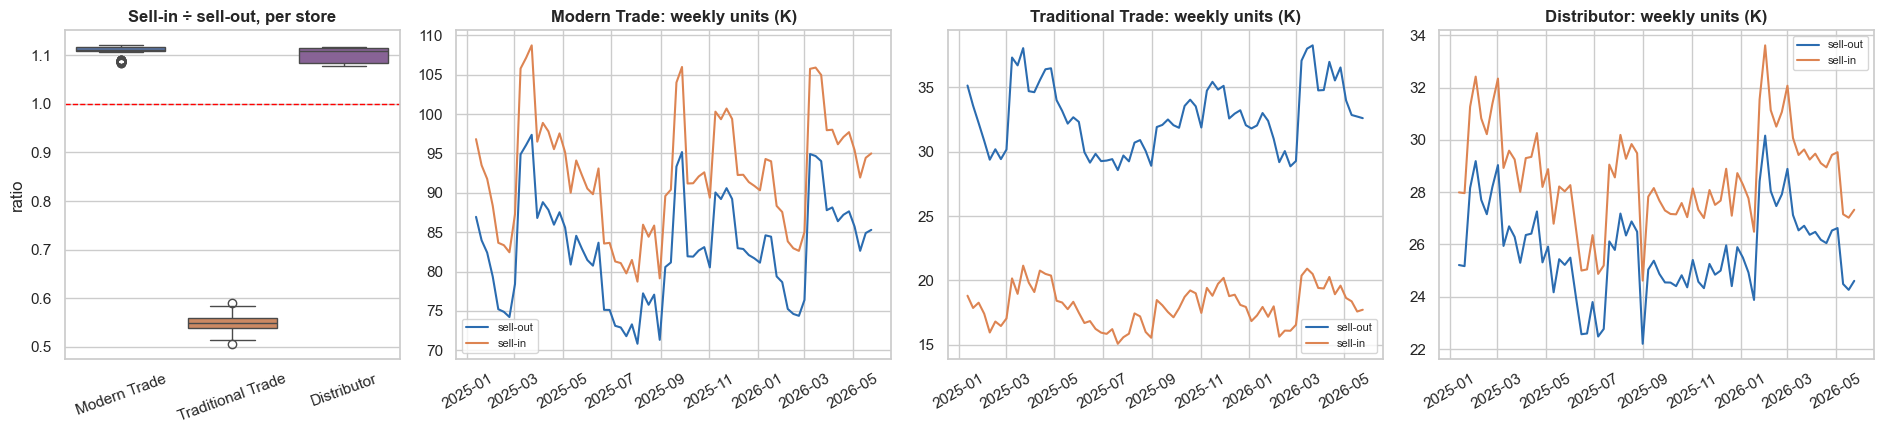

In [44]:
print('Sell-in weekdays:', sell_in.date.dt.day_name().value_counts().to_dict(), '| distinct invoice dates:', sell_in.date.nunique())
weeks = si.groupby(['channel', 'store_id', 'sku_id']).date.nunique().rename('weeks_invoiced').reset_index()
display(weeks.groupby('channel').weeks_invoiced.describe()[['mean', 'min', '50%', 'max']].reindex(CH_ORDER).round(1))

store_ratio = ((si.groupby('store_id').units_sold.sum() / sof.groupby('store_id').units_sold_daily.sum())
               .rename('ratio').reset_index().merge(stores[['store_id', 'channel']], on='store_id'))
wk_in2 = si.groupby(['channel', pd.Grouper(key='date', freq='W-SUN')]).units_sold.sum()
wk_out2 = sof.groupby(['channel', pd.Grouper(key='date', freq='W-SUN')]).units_sold_daily.sum()
fig = plt.figure(figsize=(19, 4.5))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1.3, 1.3, 1.3])
ax0 = fig.add_subplot(gs[0])
sns.boxplot(data=store_ratio, x='channel', y='ratio', order=CH_ORDER, hue='channel', palette=CH_COL, legend=False, ax=ax0)
ax0.axhline(1, color='red', ls='--', lw=1); ax0.set_title('Sell-in ÷ sell-out, per store'); ax0.set_xlabel(''); ax0.tick_params(axis='x', rotation=20)
for i, ch in enumerate(CH_ORDER):
    ax = fig.add_subplot(gs[i + 1])
    a, b = wk_in2[ch].iloc[1:-1], wk_out2[ch].iloc[1:-1]
    ax.plot(b.index, b.values / 1e3, label='sell-out', color='#2b6cb0'); ax.plot(a.index, a.values / 1e3, label='sell-in', color='#DD8452')
    ax.set_title(f'{ch}: weekly units (K)'); ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=30)
show('08_sellin_vs_sellout')

Two follow-ups. **First**, Q13 says the Traditional Trade gap should shrink once both sides use the same window, because one TT invoice covers two weeks. We computed the gap with 1-week, 2-week and monthly windows. **Second**, in our imputation work we found that in v1 each Monday invoice tracked the *next* 7 days of sell-out almost perfectly. If that's still true, any sell-in or delivery quantity would leak the future into the OOS model. So we compared each invoice with the sell-out right before and right after it.

,corr with previous 14 days,corr with previous 7 days,corr with next 7 days,corr with next 14 days,invoice ÷ next 7 days,invoice ÷ next 14 days
Modern Trade,0.872,0.843,0.997,0.958,1.113,0.557
Traditional Trade,0.834,0.801,0.997,0.947,1.104,0.552
Distributor,0.887,0.859,0.997,0.962,1.111,0.556


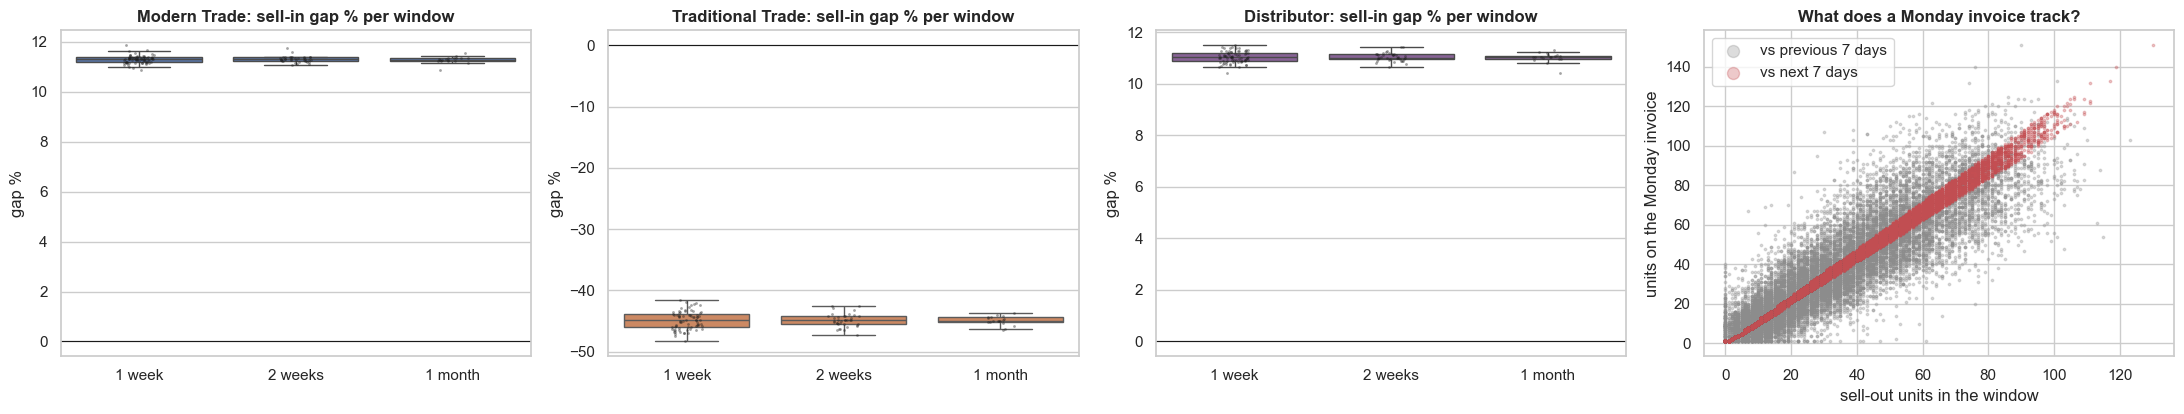

mean   min   max
channel           window                   
Modern Trade      1 month  11.3  10.9  11.5
                  1 week   11.3  10.9  11.9
                  2 weeks  11.3  11.1  11.7
Traditional Trade 1 month -44.9 -46.5 -43.7
                  1 week  -44.8 -48.3 -41.6
                  2 weeks -44.8 -47.3 -42.5
Distributor       1 month  11.0  10.4  11.3
                  1 week   11.0  10.4  11.5
                  2 weeks  11.0  10.7  11.4

In [45]:
wb = wk_both.copy()                                            # sell-in and sell-out per channel and invoice week (from 7.3)
wb['two_weeks'] = (wb.week - wb.week.min()).dt.days // 14
win_gap = {}
for name, col in [('1 week', 'week'), ('2 weeks', 'two_weeks'), ('1 month', 'month')]:
    g2 = wb.groupby(['channel', col])[['sell_in', 'sell_out']].sum()
    win_gap[name] = ((g2.sell_in / g2.sell_out - 1) * 100).rename('gap').reset_index().assign(window=name)
win_gap = pd.concat(win_gap.values())

units_w = so.pivot(index=['store_id', 'sku_id'], columns='date', values='units_sold_daily').reindex(columns=all_days)
cs = np.hstack([np.zeros((len(units_w), 1)), units_w.fillna(0).to_numpy().cumsum(axis=1)])   # cs[:, j] = units sold before day j
row_of = pd.Series(np.arange(len(units_w)), index=units_w.index)
inv_ = si[(si.date >= all_days[0] + pd.Timedelta(days=14)) & (si.date <= all_days[-1] - pd.Timedelta(days=13))].copy()
r = row_of.reindex(pd.MultiIndex.from_frame(inv_[['store_id', 'sku_id']])).to_numpy()
c = (inv_.date - all_days[0]).dt.days.to_numpy()
WINDOWS = {'previous 14 days': (-14, 0), 'previous 7 days': (-7, 0), 'next 7 days': (0, 7), 'next 14 days': (0, 14)}
for name, (a, b) in WINDOWS.items():
    inv_[name] = cs[r, c + b] - cs[r, c + a]                    # sell-out on days [invoice + a, invoice + b)
track = pd.DataFrame({ch: {**{f'corr with {n}': np.corrcoef(d.units_sold, d[n])[0, 1] for n in WINDOWS},
                           'invoice ÷ next 7 days': d.units_sold.sum() / d['next 7 days'].sum(),
                           'invoice ÷ next 14 days': d.units_sold.sum() / d['next 14 days'].sum()}
                      for ch, d in inv_.groupby('channel')}).T.reindex(CH_ORDER).round(3)
display(track)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.3))
for ax, ch in zip(axes[:3], CH_ORDER):
    sub = win_gap[win_gap.channel == ch]
    sns.boxplot(data=sub, x='window', y='gap', ax=ax, color=CH_COL[ch], showfliers=False)
    sns.stripplot(data=sub, x='window', y='gap', ax=ax, color='k', size=2, alpha=0.4)
    ax.axhline(0, color='k', lw=0.8); ax.set_title(f'{ch}: sell-in gap % per window'); ax.set_xlabel(''); ax.set_ylabel('gap %')
smp = inv_.sample(15_000, random_state=0)
axes[3].scatter(smp['previous 7 days'], smp.units_sold, s=3, alpha=0.3, color='#8C8C8C', label='vs previous 7 days')
axes[3].scatter(smp['next 7 days'], smp.units_sold, s=3, alpha=0.3, color='#C44E52', label='vs next 7 days')
axes[3].set_xlabel('sell-out units in the window'); axes[3].set_ylabel('units on the Monday invoice')
axes[3].set_title('What does a Monday invoice track?'); axes[3].legend(markerscale=5)
show('08_sellin_windows_leak')
display(win_gap.groupby(['channel', 'window']).gap.agg(['mean', 'min', 'max']).round(1).reindex(CH_ORDER, level=0))

**What we found**
1. Same structure as v1: every invoice is on a **Monday**. Modern Trade and Distributors are invoiced every week (74 weeks), Traditional Trade about every second week (37 on average, between 24 and 53).
2. The gap is still basically one number per channel: **+11% for MT and Distributors, −45% for Traditional Trade**, with a tiny spread between stores.
3. **Q13's fix doesn't close the Traditional Trade gap.** With 1-week, 2-week or monthly windows, TT stays at **about −45%** (−44.8% to −44.9% on average). If one invoice really covered two weeks of sales, the 2-week and monthly gaps would be close to 0.
4. The scatter shows why. **Each Monday invoice equals the next 7 days of sell-out × ~1.11** (correlation 0.997 in every channel), and follows the previous week much less (0.80–0.86). A Traditional Trade invoice also covers only the **next 7 days**, so the week in between is never invoiced. That's exactly where −45% comes from (1.10 × ½ − 1 ≈ −0.45).
5. As in our imputation work, sell-in **leaks the future**: an invoice "knows" next week's sales. Every delivery's `units_ordered` is the invoice quantity, so the same leak is in `fact_deliveries`. That means invoice and delivery *quantities* have to stay out of the OOS model.

### 8.4 Discounts in sell-in
The note says `discount_pct` is "now volume-correlated". In v1 discounts were a flat random number between 2% and 12%. We checked what "volume-correlated" means here: do *bigger accounts* get bigger discounts, or does the *same* store get a bigger discount when it orders more?

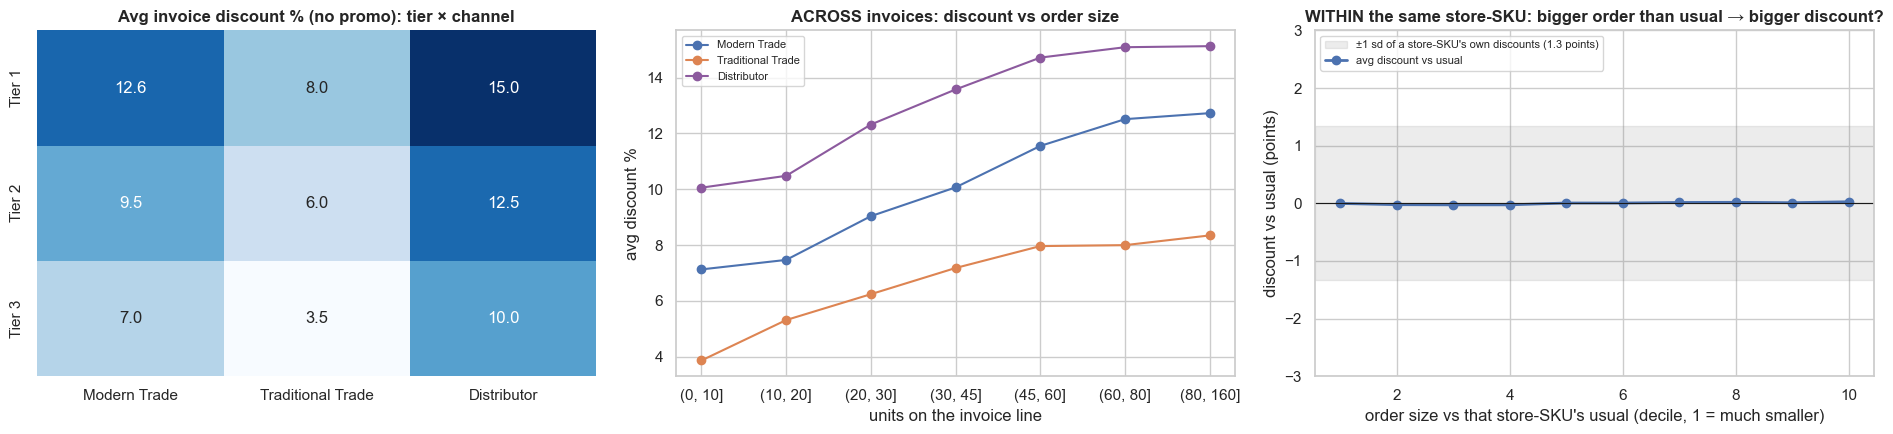

Correlation, discount vs order size: across all invoices 0.678 | within the same store-SKU 0.007
Promo invoices: discount 13.1% vs 10.1% usual for the same store-SKU (+3.0 points), while the promotions themselves offer 11.5% on average
Promo invoices that reach the promo's min_volume_units: 32%


In [46]:
si['log_units'] = np.log(si.units_sold)
npr = si[~si.on_promo].copy()
npr['units_vs_usual'] = npr.log_units - npr.groupby(k).log_units.transform('mean')
npr['disc_vs_usual'] = npr.discount_pct - npr.groupby(k).discount_pct.transform('mean')

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
hm = npr.pivot_table(index='segment_tier', columns='channel', values='discount_pct', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER]
heatmap(hm, annot=True, fmt='.1f', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Avg invoice discount % (no promo): tier × channel'); axes[0].set_xlabel(''); axes[0].set_ylabel('')
npr['units_bin'] = pd.cut(npr.units_sold, [0, 10, 20, 30, 45, 60, 80, 160])
b = npr.groupby(['units_bin', 'channel'], observed=True).discount_pct.mean().unstack()[CH_ORDER]
for ch in CH_ORDER:
    axes[1].plot(b.index.astype(str), b[ch], marker='o', color=CH_COL[ch], label=ch)
axes[1].set_title('ACROSS invoices: discount vs order size'); axes[1].set_xlabel('units on the invoice line'); axes[1].set_ylabel('avg discount %'); axes[1].legend(fontsize=8)
w = npr.groupby(pd.qcut(npr.units_vs_usual, 10, labels=False)).disc_vs_usual.mean()
sd = npr.disc_vs_usual.std()
axes[2].axhspan(-sd, sd, color='grey', alpha=0.15, label=f"±1 sd of a store-SKU's own discounts ({sd:.1f} points)")
axes[2].plot(range(1, 11), w.values, marker='o', color='#4C72B0', lw=2, label='avg discount vs usual')
axes[2].axhline(0, color='k', lw=0.8); axes[2].set_ylim(-3, 3); axes[2].legend(fontsize=8, loc='upper left')
axes[2].set_title('WITHIN the same store-SKU: bigger order than usual → bigger discount?'); axes[2].set_xlabel('order size vs that store-SKU\'s usual (decile, 1 = much smaller)')
axes[2].set_ylabel('discount vs usual (points)')
show('08_discounts')
print('Correlation, discount vs order size: across all invoices', round(np.corrcoef(npr.discount_pct, npr.units_sold)[0, 1], 3),
      '| within the same store-SKU', round(np.corrcoef(npr.disc_vs_usual, npr.units_vs_usual)[0, 1], 3))

usual = npr.groupby(k).discount_pct.mean().rename('usual_disc')
pr_inv = (si[si.on_promo].merge(usual, on=k)
          .merge(promos[['promo_id', 'discount_pct', 'min_volume_units']].rename(columns={'discount_pct': 'promo_disc'}), on='promo_id'))
print(f"Promo invoices: discount {pr_inv.discount_pct.mean():.1f}% vs {pr_inv.usual_disc.mean():.1f}% usual for the same store-SKU "
      f"(+{(pr_inv.discount_pct - pr_inv.usual_disc).mean():.1f} points), while the promotions themselves offer {pr_inv.promo_disc.mean():.1f}% on average")
print(f"Promo invoices that reach the promo's min_volume_units: {(pr_inv.units_sold >= pr_inv.min_volume_units).mean():.0%}")

**What we found**
1. Outside promos, the discount depends on **who the account is**: it steps down with tier in every channel (Modern Trade 12.6% → 9.5% → 7.0%, Traditional Trade 8.0% → 6.0% → 3.5%, Distributors 15.0% → 12.5% → 10.0%). Those round numbers look like a fixed rate per channel × tier, plus some noise.
2. That's why discount and order size are correlated across invoices (**0.68**): big accounts place big orders *and* get big discounts.
3. But **within the same store-SKU**, a bigger order than usual doesn't come with a bigger discount (correlation **0.007**; the line stays flat inside the grey band of normal variation). So "volume-correlated" means a **volume tier per account**, not a volume discount per order.
4. Promo invoices carry about **3 points** more discount than the same store-SKU's usual (13.1% vs 10.1%), while the promotions themselves advertise 11.5% on average. And only **32%** of promo invoice lines reach the promo's `min_volume_units`. So either the minimum isn't enforced, or it applies to something else (the whole order, or the whole promo period). Another question for Dr. Masse.

### 8.5 Promotions and price elasticity
Scenario B of the simulator needs a price elasticity, and in Q14 Dr. Masse asked us to estimate it **from the data**. In v1 that was impossible (no prices in sell-out). Now sell-out has two kinds of price variation:
1. **Promotions:** the price drops by 7–15% for a few weeks.
2. **Everyday wiggle:** on non-promo days the price moves up to ±3% around the consumer price.

To measure the promo lift fairly, we compared each store-SKU with **itself in the same month**: average units on promo days vs non-promo days. Same month, so the seasonal step (6.3) cancels out. In-stock days only, because a shelf at zero can't show the extra demand.

,rows,discount_pct,lift_%,implied_elasticity
Bundle,51088,12.00,4.31,-0.33
Display,41561,8.69,11.54,-1.20
Feature,32328,8.51,13.22,-1.40
TPR,119260,10.41,15.38,-1.30
Volume,44759,14.00,20.32,-1.23
BOGO,17514,15.00,24.34,-1.34
Modern Trade,160600,10.69,13.13,-1.09
Traditional Trade,101151,10.24,11.86,-1.04
Distributor,44759,14.00,20.32,-1.23
All promos,306510,11.03,13.82,-1.11


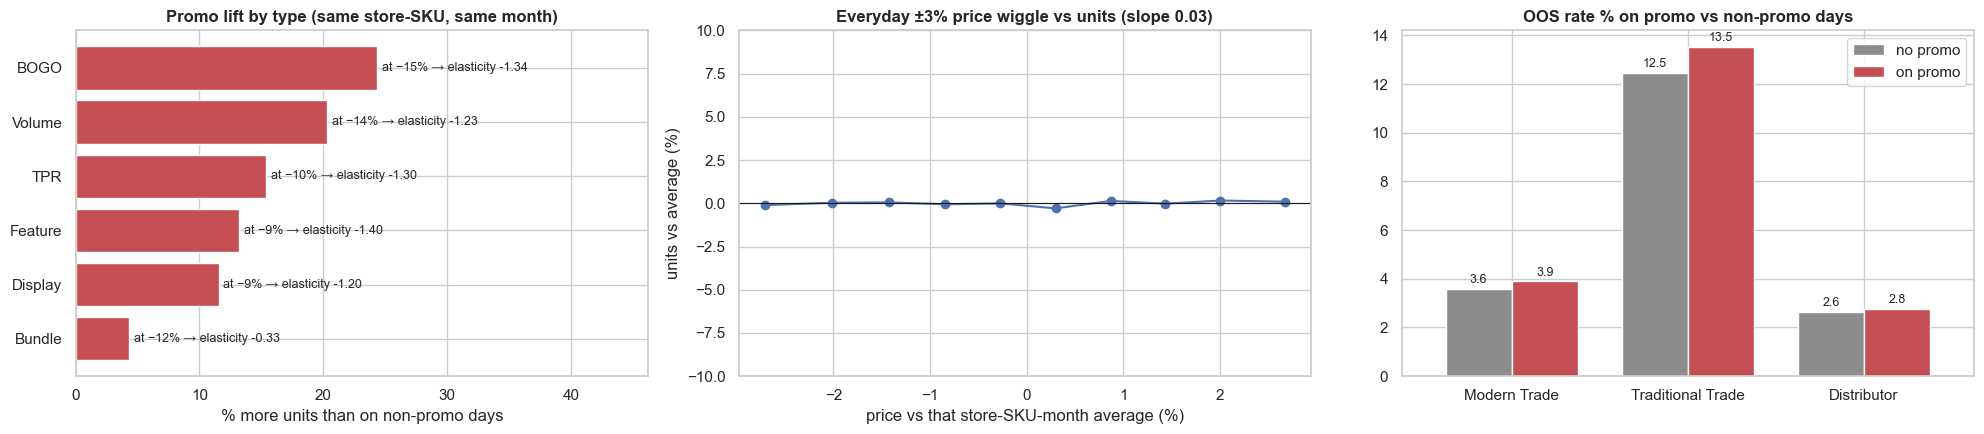

In [47]:
ins = sof.loc[~sof.is_out_of_stock, ['store_id', 'sku_id', 'date', 'channel', 'units_sold_daily', 'consumer_price_actual', 'promo_id', 'promo_discount_pct', 'on_promo']]
ins['ym'] = ins.date.dt.to_period('M')
kk = ['store_id', 'sku_id', 'ym']
base = ins[~ins.on_promo].groupby(kk).units_sold_daily.mean().rename('base_units')
pr_days = ins[ins.on_promo].merge(base, left_on=kk, right_index=True).merge(promos[['promo_id', 'promo_type']], on='promo_id')

def lift_table(by):
    t = pr_days.groupby(by).agg(promo_units=('units_sold_daily', 'sum'), base_units=('base_units', 'sum'), discount_pct=('promo_discount_pct', 'mean'), rows=('date', 'size'))
    t['lift_%'] = (t.promo_units / t.base_units - 1) * 100
    t['implied_elasticity'] = np.log(t.promo_units / t.base_units) / np.log(1 - t.discount_pct / 100)
    return t[['rows', 'discount_pct', 'lift_%', 'implied_elasticity']].round(2)
by_type, by_channel = lift_table('promo_type').sort_values('lift_%'), lift_table('channel').reindex(CH_ORDER)
all_promo = lift_table(np.repeat('All promos', len(pr_days)))
display(pd.concat([by_type, by_channel, all_promo]))

# everyday price wiggle: does a slightly higher price (same store-SKU, same month, no promo) mean fewer units?
npd = ins[~ins.on_promo]
lp = np.log(npd.consumer_price_actual)
price_dev = (lp - lp.groupby([npd.store_id, npd.sku_id, npd.ym]).transform('mean')) * 100
grp_mean = npd.groupby(kk).units_sold_daily.transform('mean')
units_dev = (npd.units_sold_daily / grp_mean.replace(0, np.nan) - 1) * 100
wig = units_dev.groupby(pd.qcut(price_dev, 10, labels=False)).mean()
wig_x = price_dev.groupby(pd.qcut(price_dev, 10, labels=False)).mean()
slope = np.polyfit(price_dev[units_dev.notna()], units_dev.dropna(), 1)[0]

oos_promo = sof.groupby(['channel', 'on_promo']).is_out_of_stock.mean().unstack().reindex(CH_ORDER) * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
axes[0].barh(by_type.index, by_type['lift_%'], color='#C44E52')
for i, (t_, r_) in enumerate(by_type.iterrows()):
    axes[0].text(r_['lift_%'] + 0.4, i, f"at −{r_.discount_pct:.0f}% → elasticity {r_.implied_elasticity:.2f}", va='center', fontsize=9)
axes[0].set_xlim(0, by_type['lift_%'].max() * 1.9); axes[0].set_title('Promo lift by type (same store-SKU, same month)'); axes[0].set_xlabel('% more units than on non-promo days')
axes[1].plot(wig_x, wig, marker='o', color='#4C72B0'); axes[1].axhline(0, color='k', lw=0.8); axes[1].set_ylim(-10, 10)
axes[1].set_title(f'Everyday ±3% price wiggle vs units (slope {slope:.2f})'); axes[1].set_xlabel('price vs that store-SKU-month average (%)'); axes[1].set_ylabel('units vs average (%)')
oos_promo.plot.bar(ax=axes[2], color=['#8C8C8C', '#C44E52'], rot=0, width=0.75); label_bars(axes[2], '{:.1f}')
axes[2].legend(['no promo', 'on promo']); axes[2].set_title('OOS rate % on promo vs non-promo days'); axes[2].set_xlabel('')
show('08_promo_lift_elasticity')

**What we found**
1. **Promotions work.** On average a store-SKU sells **13.8% more** on promo days than on normal days in the same month, at an average discount of 11.0%. BOGO (+24%) and Volume deals (+20%) lift the most; Bundles almost nothing (+4%).
2. Turned into an elasticity (% change in units ÷ % change in price), that's about **−1.1 overall** and **−1.2 to −1.4** for most promo types. TPR, the plain price cut, gives **−1.30**. Bundles are the exception at −0.3.
3. **The everyday ±3% wiggle does nothing**: the slope is 0.03, so units don't react at all. The wiggle is just noise on the price, and only promotions carry a real price signal.
4. OOS is slightly higher on promo days (e.g. Traditional Trade 13.5% vs 12.5%), because demand goes up while the refill rhythm stays the same.

**For Scenario B**, this is what Q14 asked for: an elasticity that comes from the data. We'd use **about −1.1 to −1.3** from the promotions and show that range in the simulator, with two caveats stated clearly. These are temporary price *cuts*, while Scenario B is about price *increases*. And a promo lift can include shoppers stocking up, which a permanent price change wouldn't cause.

### 8.6 Delivery performance
`fact_deliveries` is new, so here is what it says about Marvel's own logistics (we judge "late" from the dates, not the status label, because of 3.5).

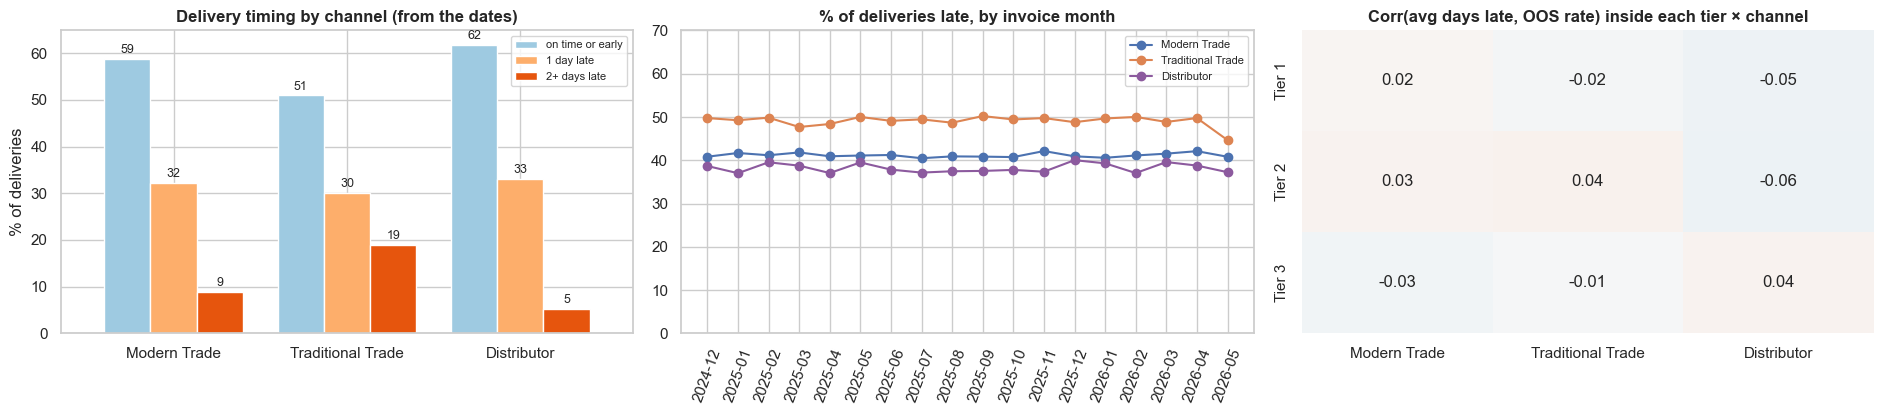

,scheduled_lead_days,avg_days_late,short_shipped_pct,fill_rate_pct
channel,,,,
Modern Trade,3.00,0.62,4.96,99.09
Traditional Trade,4.99,1.00,4.95,99.03
Distributor,2.00,0.50,5.02,99.07


channel,Modern Trade,Traditional Trade,Distributor
segment_tier,,,
Tier 1,0.53,0.72,0.45
Tier 2,0.65,0.97,0.52
Tier 3,0.77,1.20,0.57


Avg days late vs OOS rate across ALL store-SKUs: corr 0.70 | inside each tier × channel: -0.06 to 0.04


In [48]:
dv['timing'] = np.select([dv.days_vs_schedule <= 0, dv.days_vs_schedule == 1], ['on time or early', '1 day late'], '2+ days late')
timing = pd.crosstab(dv.channel, dv.timing, normalize='index').reindex(CH_ORDER)[['on time or early', '1 day late', '2+ days late']] * 100
perf = dv.groupby('channel').agg(scheduled_lead_days=('lead_scheduled', 'mean'), avg_days_late=('delay_days', 'mean'),
                                 short_shipped_pct=('fill_rate_pct', lambda s: (s < 100).mean() * 100)).reindex(CH_ORDER)
perf['fill_rate_pct'] = dv.groupby('channel').units_delivered.sum() / dv.groupby('channel').units_ordered.sum() * 100

fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
timing.plot.bar(ax=axes[0], color=['#9ecae1', '#fdae6b', '#e6550d'], rot=0, width=0.8); label_bars(axes[0], '{:.0f}')
axes[0].set_title('Delivery timing by channel (from the dates)'); axes[0].set_ylabel('% of deliveries'); axes[0].set_xlabel(''); axes[0].legend(fontsize=8)
late_m = dv.groupby([dv.invoice_date.dt.to_period('M'), 'channel']).days_vs_schedule.apply(lambda s: (s > 0).mean() * 100).unstack()[CH_ORDER]
for ch in CH_ORDER:
    axes[1].plot(late_m.index.astype(str), late_m[ch], marker='o', color=CH_COL[ch], label=ch)
axes[1].set_title('% of deliveries late, by invoice month'); axes[1].tick_params(axis='x', rotation=70); axes[1].legend(fontsize=8); axes[1].set_ylim(0, 70)
pc = pair.assign(channel=pair.store_id.map(ch_of))
cc = pc.groupby(['segment_tier', 'channel']).apply(lambda g: g.avg_days_late.corr(g.oos_rate)).unstack().reindex(TIER_ORDER)[CH_ORDER]
heatmap(cc, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[2], cbar=False)
axes[2].set_title('Corr(avg days late, OOS rate) inside each tier × channel'); axes[2].set_xlabel(''); axes[2].set_ylabel('')
show('08_delivery_performance')
display(perf.round(2))
display(pc.pivot_table(index='segment_tier', columns='channel', values='avg_days_late').reindex(TIER_ORDER)[CH_ORDER].round(2))
print(f"Avg days late vs OOS rate across ALL store-SKUs: corr {pair.avg_days_late.corr(pair.oos_rate):.2f} | "
      f"inside each tier × channel: {cc.min().min():.2f} to {cc.max().max():.2f}")

**What we found**
1. Planned lead times are short and fixed per channel (Distributors 2 days on average, Modern Trade 3, Traditional Trade 5), and almost every shipment arrives complete (fill rate ~99%, ~5% short in every channel).
2. Going by the dates, 38–49% of deliveries are at least a day late, and Traditional Trade has it worst (1.0 day late on average vs 0.5–0.6 for the others). Lateness doesn't trend over the 17 months.
3. Across all store-SKUs, later deliveries go with more OOS (correlation 0.70). But **inside each tier × channel the correlation disappears** (between −0.06 and +0.04). Delays are simply set by segment: Traditional Trade Tier 3 averages 1.2 days late, Distributor Tier 1 only 0.45. The same small stores also run out more, which creates the overall correlation. Since deliveries don't refill the shelf (3.9), this makes sense: **in this data, late deliveries don't cause stock-outs**.

So the delivery table is useful for a **logistics view** in the dashboard (on-time % by the dates, fill rate from units, by channel), but it's unlikely to help predict OOS.

### 8.7 Does better execution lead to more sales?
The audits are the same file as v1, but sell-out was regenerated, so we re-ran the v1 test. Q14 also asks specifically for the **sell-out lift associated with `secondary_display`**, so we estimated that directly too.

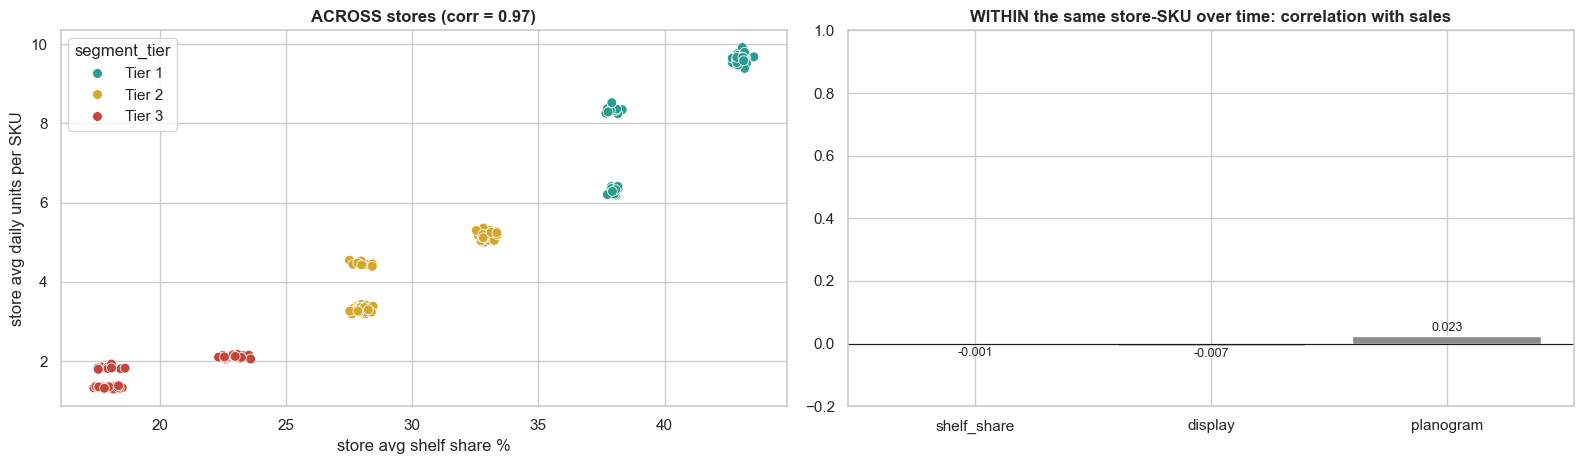

Same store-SKU, months WITH a display vs WITHOUT: -0.2% units (3,920 store-SKUs that had both)
Across store-SKUs in the same channel and tier, more displays vs fewer: -1.0% units on average


In [49]:
tmp = sof.loc[~sof.is_out_of_stock, ['store_id', 'sku_id', 'date', 'units_sold_daily']].assign(month=lambda d: d.date.dt.to_period('M'))
so_m = tmp.groupby(['store_id', 'sku_id', 'month']).units_sold_daily.mean().rename('units')
au_m = (audits.assign(month=audits.date.dt.to_period('M')).groupby(['store_id', 'sku_id', 'month'])
              .agg(shelf_share=('shelf_share_pct', 'mean'), display=('secondary_display', 'mean'), planogram=('planogram_compliance', 'mean')))
m = pd.concat([so_m, au_m], axis=1, join='inner').reset_index()
for c in ['units', 'shelf_share', 'display', 'planogram']:
    m[c + '_vs_usual'] = m[c] - m.groupby(['store_id', 'sku_id'])[c].transform('mean')
within = {c: np.corrcoef(m[c + '_vs_usual'], m['units_vs_usual'])[0, 1] for c in ['shelf_share', 'display', 'planogram']}

store_lvl = m.groupby('store_id')[['units', 'shelf_share']].mean().join(stores.set_index('store_id').segment_tier)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.scatterplot(data=store_lvl, x='shelf_share', y='units', hue='segment_tier', hue_order=TIER_ORDER, palette=TIER_COL, s=50, ax=axes[0])
axes[0].set_title(f"ACROSS stores (corr = {store_lvl[['shelf_share', 'units']].corr().iloc[0, 1]:.2f})")
axes[0].set_xlabel('store avg shelf share %'); axes[0].set_ylabel('store avg daily units per SKU')
axes[1].bar(list(within.keys()), list(within.values()), color='#8C8C8C'); label_bars(axes[1], '{:.3f}')
axes[1].set_ylim(-0.2, 1); axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('WITHIN the same store-SKU over time: correlation with sales')
show('08_execution_vs_sales')

# Q14: sell-out lift associated with secondary_display = TRUE
md = m.assign(has_display=m.display >= 0.5).groupby(['store_id', 'sku_id', 'has_display']).units.mean().unstack().dropna()
lift_same = md[True].sum() / md[False].sum() - 1
cell = pair.assign(channel=pair.store_id.map(ch_of))
cell['high_display'] = cell.sec_display > cell.groupby(['channel', 'segment_tier']).sec_display.transform('median')
across = cell.groupby(['channel', 'segment_tier', 'high_display']).avg_units.mean().unstack()
lift_across = (across[True] / across[False] - 1).mean()
print(f"Same store-SKU, months WITH a display vs WITHOUT: {lift_same:+.1%} units ({len(md):,} store-SKUs that had both)")
print(f"Across store-SKUs in the same channel and tier, more displays vs fewer: {lift_across:+.1%} units on average")
del tmp; _ = gc.collect()

**What we found**
Same answer as v1. Across stores, shelf share and sales are very strongly linked (0.97), but it's one tight cluster of stores per tier × channel. Within the same store-SKU over time the correlations are **zero** (shelf share −0.001, display −0.007, planogram 0.023).

For Q14 we also estimated the secondary-display uplift two ways. Months **with** a display vs **without** for the same store-SKU give **−0.2%**, and store-SKUs with more displays vs fewer in the same channel and tier give **−1.0%**. So the data-derived execution uplift is **about zero**. For Module 3 Scenario A we'll report this honestly: in this dataset, execution commitments don't move sales. If the simulator needs a non-zero value, it has to be a clearly labelled assumption, and we'll ask Dr. Masse which he prefers.

### 8.8 Commercial guardrails
Q5 and Q16 settled the margin formula: **net price = list price × (1 − discount)** and **gross margin = (net price − cost) ÷ net price**. v2 also gives us the actual discount on every invoice, so we can see how the current discounts compare with the caps.

,channel,category,max_discount_pct,min_target_margin,required_exec_tradeoff
0,Modern Trade,Surface Cleaners,12.80,26.62,Secure +10% shelf share or place 1 secondary d...
1,Modern Trade,Dishwashing,11.34,22.26,Commit to featured endcap placement for 4 weeks
2,Modern Trade,Laundry,13.30,25.50,Secure +15% shelf share or place 1 secondary d...
3,Traditional Trade,Surface Cleaners,6.62,31.47,Secure +10% shelf share or place 1 secondary d...
4,Traditional Trade,Dishwashing,7.99,27.52,Achieve 100% MSL compliance + planogram adherence
5,Traditional Trade,Laundry,7.16,27.08,Commit to featured endcap placement for 4 weeks
6,Distributor,Surface Cleaners,17.80,23.45,Achieve 100% MSL compliance + planogram adherence
7,Distributor,Dishwashing,15.07,21.97,Secure +15% shelf share or place 1 secondary d...
8,Distributor,Laundry,16.34,17.41,Commit to featured endcap placement for 4 weeks


max_discount_allowed  avg_invoice_discount  p95_invoice_discount  share_of_invoices_over_cap  min_margin_rule  lowest_margin_on_any_invoice  \
channel           category                                                                                                                                                        
Modern Trade      Dishwashing                      11.34                 10.85                 15.14                        0.44            22.26                         41.69   
                  Laundry                          13.30                 10.79                 15.05                        0.21            25.50                         39.80   
                  Surface Cleaners                 12.80                 10.91                 15.29                        0.27            26.62                         40.34   
Traditional Trade Dishwashing                       7.99                  6.30                 10.27                        0.21            27.52                         45.37   
                  Laundry                           7.16                  5.79                  9.49                        0.28            27.08                         43.65   
                  Surface Cleaners                  6.62                  6.10                  9.95                        0.42            31.47                         44.20   
Distributor       Dishwashing                      15.07                 13.75                 18.69                        0.32            21.97                         41.18   
                  Laundry                          16.34                 13.67                 18.37                        0.20            17.41                         38.86   
                  Surface Cleaners                 17.80                 13.73                 18.47                        0.08            23.45                         39.66   

                                    discount_that_breaks_margin  
channel           category                                       
Modern Trade      Dishwashing                             39.47  
                  Laundry                                 34.34  
                  Surface Cleaners                        34.21  
Traditional Trade Dishwashing                             35.07  
                  Laundry                                 32.92  
                  Surface Cleaners                        29.56  
Distributor       Dishwashing                             39.69  
                  Laundry                                 40.78  
                  Surface Cleaners                        36.94

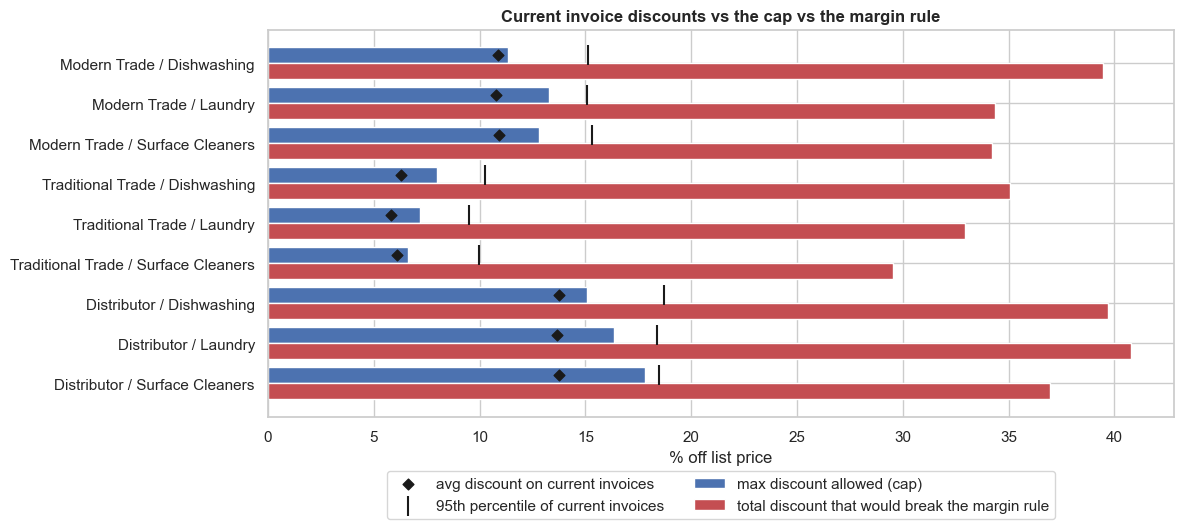

Invoice lines already above their channel × category cap: 28.0%
required_exec_tradeoff
Commit to featured endcap placement for 4 weeks         3
Secure +10% shelf share or place 1 secondary display    2
Secure +15% shelf share or place 1 secondary display    2
Achieve 100% MSL compliance + planogram adherence       2
Name: count, dtype: int64


In [50]:
display(guardrails)
gm = products.merge(guardrails, on='category')
gm['discount_that_breaks_margin'] = (1 - gm.unit_cost / ((1 - gm.min_target_margin / 100) * gm.list_price)) * 100
g2 = si.merge(guardrails, on=['channel', 'category'])
g2['over_cap'] = g2.discount_pct > g2.max_discount_pct
g2['margin_pct'] = (g2.net_sales - g2.units_sold * g2.unit_cost) / g2.net_sales * 100
gsum = (g2.groupby(['channel', 'category'])
          .agg(max_discount_allowed=('max_discount_pct', 'first'), avg_invoice_discount=('discount_pct', 'mean'),
               p95_invoice_discount=('discount_pct', lambda s: s.quantile(.95)), share_of_invoices_over_cap=('over_cap', 'mean'),
               min_margin_rule=('min_target_margin', 'first'), lowest_margin_on_any_invoice=('margin_pct', 'min'))
          .join(gm.groupby(['channel', 'category']).discount_that_breaks_margin.min()).reindex(CH_ORDER, level=0))
display(gsum.round(2))

plot_df = gsum.reset_index()
labels = plot_df.channel + ' / ' + plot_df.category
y = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.barh(y - 0.2, plot_df.max_discount_allowed, height=0.4, color='#4C72B0', label='max discount allowed (cap)')
ax.barh(y + 0.2, plot_df.discount_that_breaks_margin, height=0.4, color='#C44E52', label='total discount that would break the margin rule')
ax.scatter(plot_df.avg_invoice_discount, y - 0.2, color='k', marker='D', s=30, zorder=5, label='avg discount on current invoices')
ax.scatter(plot_df.p95_invoice_discount, y - 0.2, color='k', marker='|', s=200, zorder=5, label='95th percentile of current invoices')
ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlabel('% off list price'); ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title('Current invoice discounts vs the cap vs the margin rule')
show('08_guardrails')
print(f"Invoice lines already above their channel × category cap: {g2.over_cap.mean():.1%}")
print(guardrails.required_exec_tradeoff.value_counts())

**What we found**
1. With the official margin formula (Q5, Q16), the margin rule still **never triggers**. The total discount that would break the minimum margin is **29.6–40.8%**, far above both the caps (6.6–17.8%) and the highest invoice discount in the data (20%). The lowest margin on any invoice is 38.9%, above every minimum (17.4–31.5%).
2. New in v2: **28.0% of invoice lines are already above their channel × category cap** (up to 44% for Modern Trade Dishwashing). So either `max_discount_pct` caps the *extra* discount a rep can add on top of the account's normal discount (how we read it in v1), or a lot of current invoices break the rules. This changes how Scenario A works, so we need Dr. Masse to confirm.
3. The give-backs are still the same 4 free-text rules. Now that Q16 is answered ("+15%" means percentage points, an endcap counts as `secondary_display`), we can turn them into automatic checks.

## 9. Key insights: what changed from v1, and what it means for our build

| # | v1 finding | Status in v2 | What it means for us |
|---|---|---|---|
| 1 | ~30% of store-days missing; sell-out stock frozen across them | **8.1%** missing, still random whole days; stock still frozen across them, but deliveries are recorded on ~75% of them | Carry stock forward, treat gap-day sales as unknown; much smaller impact now |
| 2 | Data ends 30 Jun 2026 | Same (confirmed in Q18); 1.1% of deliveries land in July | Treat 30 Jun as today; cut actual delivery dates there |
| 3 | Tier drives sales, execution and OOS | **Much stronger for OOS**: 0.6% (Tier 1) vs 16.8% (Tier 3); TT Tier 3 at 25% | Tier × channel is the main filter and the main model segment |
| 4 | Region barely matters | Same | A map is nice to have, not the story |
| 5 | Category seasonality; weekends +23% | Same seasonality (+22% weekends), plus promo spikes on top | Month + weekday + promo factors for the perfect order |
| 6 | MSL compliance ~40% | **51%** overall, but only **3.5%** for TT Tier 3 | The rep view should put TT Tier 3 stores first |
| 7 | Monthly sell-in gap distorted by the number of Mondays | Fixed by bucketing both sides into invoice weeks | Dashboard compares sell-in and sell-out by week (Q13) |
| 8 | Sell-in gap is one number per channel | Same (+11% / −45% / +11%); TT gap survives Q13's window fix; invoices = next week's sales × 1.11 | Ask Dr. Masse; never use invoice quantities as model features |
| 9 | No price signal | **Promotions give an elasticity of ≈ −1.1 to −1.3**; the everyday price wiggle is noise | Scenario B can use a data-derived elasticity (Q14) |
| 10 | Execution doesn't move sales | Same; display uplift ≈ 0% | Scenario A uplift has to be a labelled assumption |
| 11 | The margin guardrail never triggers | Same; and 28% of invoices are already above the discount cap | Confirm what the cap applies to |
| 12 | Irregular deliveries cap OOS precision (~0.55) | Still open: the new delivery data doesn't match the shelf refills, so it can't tell when the next refill lands | Ask for the real refill dates; test in the modelling notebook |
| 13 | *(new)* | `fact_deliveries` is generated from sell-in, not from the shelf; the "Early" label is wrong | Use it for a logistics view only, based on dates |
| 14 | *(new)* | Discounts are a fixed level per channel × tier, not per order | Scenario A starts from each account's usual discount |
| 15 | *(new)* | Sell-out was fully regenerated | Rebuild every dashboard number on v2 |

## 10. Questions for Dr. Masse

1. **Deliveries vs stock:** `fact_deliveries` doesn't line up with the stock refills in `fact_sell_out` (a same-day match only 11.7% of the time, the same as chance; refills are ~2× bigger and half as frequent). Is this intended? Could we get the dates when the *shelf* actually gets refilled? In our what-if test on the original data, knowing when the next refill lands was the one input that put 0.75 precision in reach.
2. **Delivery status:** every "Early" delivery arrives one day *after* its scheduled date. Is the label wrong, or the dates?
3. **Traditional Trade sell-in gap:** even with matched 2-week and monthly windows (Q13), the gap stays at −45%, because each biweekly invoice covers only the next 7 days of sales. Is that intended, and what should the KPI show?
4. **Discount cap:** 28% of invoice lines are already above `max_discount_pct`. Does the cap apply to the extra discount a rep negotiates, or to the total invoice discount?
5. **Promo minimum volume:** only 32% of promo invoice lines reach `min_volume_units`. Is the minimum per invoice line, per order, or per promo period?
6. **Elasticity:** is an elasticity from the promotions (≈ −1.1 to −1.3) acceptable for the price *increases* in Scenario B?
7. **Execution uplift:** the data shows no sales lift from displays or shelf share (≈ 0%). Should Scenario A use 0%, or a labelled assumption?
8. **Q7 numbers:** the audits show higher planogram compliance than the Q7 figures (e.g. TT Tier 3 52.9% vs ~45%). Where do the Q7 numbers come from?
9. **OOS metrics by segment:** we know the targets are fixed (Q12). OOS now ranges from under 1% of store-SKU-days in Tier 1 to ~25% in Traditional Trade Tier 3, so one overall number hides very different situations. Can we report the metrics per segment alongside the overall number?
10. **Final data:** the update regenerated all of sell-out, not just added columns. Is v2 final, so we can rebuild the dashboard and the model on it?

## 11. Next steps

1. Send these questions to Dr. Masse, starting with the deliveries vs stock refills one.
2. Update the repo docs flagged for v2 review (data dictionary, KPI spec, bottlenecks) with the numbers from this notebook.
3. Rebuild the dashboard data (Module 1) on v2: official KPI definitions, Distributors shown separately, the sell-in gap by invoice week, plus a new promotions view and a logistics view (on-time % from the dates, fill rate from units).
4. Do the missing-data experiments and the OOS model in their own notebooks, on v2: train up to May 2026 and test on June 2026 (kept out of this EDA). Use the promo calendar as a forward-looking input, keep invoice and delivery quantities out (they leak next week's sales), and try segment-specific thresholds and refill-rhythm features.
5. Module 3: elasticity from the promotions for Scenario B; each account's usual discount (channel × tier) as the starting point for Scenario A.
6. Push this notebook and its figures to the repo on a v2 branch and open a PR (team rule: new data work is labelled v2).